# OpenCV 培训讲义（必修）

> RobotIC 算法组 · 新人培训第一讲 · **学生讲义**
> 按学生自学的顺序编排

---

## 本讲内容

| 章 | 内容 | 难度 |
| --- | --- | --- |
| 第 1 章 | 图像的读取与显示（含视频） | ⭐ |
| 第 2 章 | 图像的基本操作：像素 / 通道 / 边框 / ROI | ⭐⭐ |
| 第 3 章 | 颜色空间：灰度 / BGR / HSV | ⭐⭐ |
| 第 4 章 | 掩码与逻辑运算（含加法 / 混合） | ⭐⭐ |
| 第 5 章 | 二值化与颜色分割 | ⭐⭐⭐ |
| 第 6 章 | 图像形态学变换：腐蚀 / 膨胀 / 开 / 闭 | ⭐⭐ |
| 第 7 章 | 图像卷积：滤波与边缘检测的共同底层 | ⭐⭐⭐ |
| 第 8 章 | 图像滤波与去噪 | ⭐⭐ |
| 第 9 章 | 几何变换（含透视变换实战） | ⭐⭐ |
| 第 10 章 | 在图像上画图 | ⭐ |
| 第 11 章 | 面向对象编程 | ⭐⭐ |
| 第 12 章 | 综合实战：红绿灯识别 | ⭐⭐⭐ |
| 附录 A | 函数速查表 | 随时翻 |

### 学之前，你需要

- 会写最基本的 Python：变量、`if`、`for`、函数、`import`
- 电脑上能跑 Jupyter Notebook,按照群里面的教程配好了环境
- 会 `pip install`（第 0 章有命令）


### 怎么用这份讲义

1. **从上往下跑代码**，不要跳（后面的单元格依赖前面定义的函数）
2. 代码格里的都是**能直接运行的 OpenCV 代码**，图片路径写成 `res/xxx.png` 相对路径
3. 看到 ⚠️ 易错点，停下来想一想为什么
4. ✍️ 练习一定要自己写一遍，写不出来看可以问ai
5. 写代码时可以随时翻附录 A（函数速查表）

## 素材

都在 `res/` 目录下，代码里直接写相对路径就能读：

| 文件 | 内容 |
| --- | --- |
| `res/nl_side.png` | 纯色背景小图 |
| `res/nl_think.png` | 白底站姿（适合抠图） |
| `res/nl_santa.png` | 红帽子 + 黄皮肤（颜色对比强） |
| `res/nl_rainbow.png` | 彩虹渐变（看 H 通道） |
| `res/nl_galaxy.png` | 星空暗色（看 V 通道） |
| `res/nl_question.png` `res/nl_point.png` `res/nl_angry.png` | 其他姿势 |
| `res/nl_hd01.jpg` `res/nl_hd13.jpg` `res/nl_hd17.jpg` | 高清壁纸 |
| `res/nl_classic1.jpg` `res/nl_classic2.jpg` | 古典油画场景 |
| `res/nl_video.mp4` | 演示视频（1280x720 @25fps，596 帧） |
| `res/rgb.png` | RGB 颜色空间示意图（三维立方体，第 3 章） |
| `res/HSV.png` | HSV 颜色空间示意图（圆锥 + 色环，第 3 章） |
| `res/hans-traffic-light-8511_1920.jpg` | 红绿灯实拍照片（只有红灯亮，第 12 章用） |
| `res/lena_word.png` | 纸面诗稿（上半亮、下半暗，第 5 章演示自适应阈值用） |

本讲义生成的图片 / 视频统一放在 `out/` 目录。

---

# 第 0 章 开始之前：环境与工具

> 🎯 **学习目标**：知道 OpenCV 是什么，环境能跑起来，`cv2` 能正常导入。

## 0.1 OpenCV 是什么

OpenCV 是计算机视觉领域最经典的专用库，支持多语言、跨平台。

**为什么用 Python 写 OpenCV？**

- Python 简单、可读性好，几行代码就能表达想法；
- 但 Python 比 C/C++ 慢 —— 所以 **OpenCV-Python 其实是原始 OpenCV C++ 实现的 Python 包装器**：
  计算密集的部分在后台跑的是真正的 C++ 代码，速度和原生 C++ 一样快，而写起来轻松得多。

**它和 NumPy 的关系**（这一点很重要）：

> OpenCV-Python 利用 **NumPy** 做数值运算，**所有图像都是 NumPy 数组**。
> 所以你后面看到的所有"图像操作"，本质上都是**数组操作**。

## 0.2 安装

```bash
pip install opencv-python
pip install numpy matplotlib

# 需要额外扩展模块（SIFT、contrib 系列）时才装
pip install opencv-contrib-python
```

> 💡 **小贴士**：**包名**是 `opencv-python`，**导入名**是 `cv2`（历史原因保留的名字）。
> pip 慢的话加国内源：`pip install opencv-python -i https://pypi.tuna.tsinghua.edu.cn/simple`

## 0.3 三条铁律（先背下来）

| 铁律 | 说明 | 不遵守会怎样 |
| --- | --- | --- |
| **OpenCV 读进来是 BGR** | 不是 RGB | 显示时红蓝互换 |
| **图像是 `[y, x]`，不是 `[x, y]`** | NumPy 索引先行后列 | 取像素取错位置 |
| **中文路径会让读写静默失败** | `imread` 返回 `None`，`imwrite` 干脆不写 | 报奇怪的错、找不到文件 |

## 0.4 起手式

写 OpenCV 程序，开头永远是这几行，直接抄：

```python
import cv2
import numpy as np
import matplotlib.pyplot as plt
```

接下来我们把环境和素材准备好。**显示**的事情放到第 1 章专门讲。


In [70]:
# 传统视觉常用起手式
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

print("OpenCV 版本:", cv2.__version__)

# matplotlib 全局设置：画布大小 / 中文字体 / 分辨率
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'SimSun']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 72

os.makedirs('out', exist_ok=True)       # 生成的图片 / 视频统一放这里
print("工作目录:", os.getcwd())


OpenCV 版本: 4.13.0
工作目录: d:\0mylearn\Assignment-1-Computer-Vision\视觉教材opencv部分


In [71]:
# 先确认素材都在（res/ 下的奶蛙图库）
import glob

for path in sorted(glob.glob('res/nl_*.png')) + sorted(glob.glob('res/nl_*.jpg')):
    img = cv2.imread(path)
    print(f"{path:22s} {str(img.shape):18s} {img.dtype}")


res\nl_angry.png       (610, 690, 3)      uint8
res\nl_galaxy.png      (300, 300, 3)      uint8
res\nl_orange.png      (541, 500, 3)      uint8
res\nl_point.png       (690, 668, 3)      uint8
res\nl_question.png    (864, 824, 3)      uint8
res\nl_rainbow.png     (935, 1080, 3)     uint8
res\nl_santa.png       (498, 500, 3)      uint8
res\nl_side.png        (302, 320, 3)      uint8
res\nl_think.png       (655, 690, 3)      uint8
res\nl_yellow.png      (551, 411, 3)      uint8
res\nl_classic1.jpg    (1080, 1920, 3)    uint8
res\nl_classic2.jpg    (1080, 1920, 3)    uint8
res\nl_hd01.jpg        (1080, 1920, 3)    uint8
res\nl_hd13.jpg        (1080, 1920, 3)    uint8
res\nl_hd17.jpg        (1080, 1920, 3)    uint8
res\nl_satan.jpg       (720, 1280, 3)     uint8


---

# 第 1 章 图像的读取与显示

> 🎯 **学习目标**：能正确读进一张图，并说出它到底是什么东西。

## 讲解要点

### 1. `imread` 的三种模式

`cv2.imread(path, flag)` 的第二个参数是**读取模式**：

| 读取模式 | 值 | 含义 | shape |
| --- | --- | --- | --- |
| `cv2.IMREAD_COLOR`（默认） | 1 | 始终读成 BGR 三通道彩色 | `(H, W, 3)` |
| `cv2.IMREAD_GRAYSCALE` | 0 | 读成单通道灰度 | `(H, W)` |
| `cv2.IMREAD_UNCHANGED` | -1 | 原样读入，含 alpha 通道 | `(H, W, 4)` |

```python
img  = cv2.imread('res/nl_think.png')                             # 彩色
gray = cv2.imread('res/nl_think.png', cv2.IMREAD_GRAYSCALE)       # 灰度
gray = cv2.imread('res/nl_think.png', 0)                          # 也可以直接写 0
```

### 2. 图像就是 NumPy 数组

| 属性 | 含义 |
| --- | --- |
| `type(img)` | `numpy.ndarray` |
| `img.shape` | 彩色 `(高, 宽, 3)`，灰度 `(高, 宽)` |
| `img.dtype` | 通常是 `uint8`（0~255） |
| `img.size` | 总元素个数 |

**坐标约定**：`img[y, x, c]`，原点在**左上角**，y 向下、x 向右，通道序 **B G R**。

### 3. ⚠️ 路径写错时 `imread` 不报错，它返回 `None`

这是新手遇到的第一个大坑。路径错 / 文件不存在 / 中文路径，`imread` 都只会**安静地返回 `None`**，
然后继续往下走，直到撞上这个著名的报错：

```text
cv2.error: OpenCV(4.x.x) ... error: (-215:Assertion failed)
size.width>0 && size.height>0 in function 'cv::imshow'
```

> ⚠️ **易错点**：见到 `-215`，第一反应就是 `print(img)` 看是不是 `None`。
> 排查永远从"图到底读到没有"开始。

### 4. 图像路径怎么写

| 写法 | 例子 | 说明 |
| --- | --- | --- |
| 相对路径 | `'res/nl_santa.png'` | 相对于**当前工作目录**（Notebook 所在目录） |
| 上一级 | `'../images/a.jpg'` | |
| 绝对路径 | `r'D:\0mylearn\assignment-1\res\nl_santa.png'` | Windows 建议用 `r''` 原始字符串，或把 `\` 换成 `/` |

> 💡 **小贴士**：用 `os.path.join()` 拼路径比手写 `'a/b/c'` 更稳妥，还能跨平台。
> 在 Notebook 里不确定工作目录时，先 `print(os.getcwd())`。

### 5. 显示图像（一）：OpenCV 自己的 `cv2.imshow`

图像读进来，第一件事当然是想看看它。OpenCV 自带显示函数，就三行：

```python
cv2.imshow('nailong', img)     # 在名为 nailong 的窗口里显示图像
cv2.waitKey(0)                 # 等待按键：0 = 无限等
cv2.destroyAllWindows()        # 销毁所有窗口
```

**`cv2.waitKey()` 是窗口的"心脏"**：

| 写法 | 含义 |
| --- | --- |
| `cv2.waitKey(0)` | **无限等待**按键 |
| `cv2.waitKey(25)` | 等 25 毫秒后自动继续（≈ 1000/40fps，视频播放常用） |
| `cv2.waitKey(0) & 0xFF == ord('q')` | 几乎不等待，按 q 退出循环（摄像头常用） |

> 💡 **小贴士**：某些系统上 `waitKey` 的返回值不止 8 位，要 `& 0xFF` 之后再和 `ord('q')` 比较。

### 6. 显示图像（二）：Notebook 里为什么换成 matplotlib

| 原因 | 具体表现 |
| --- | --- |
| **① 内核会卡住** | `cv2.waitKey(0)` 无限等按键，Notebook 里整个内核停在那里 |
| **② 结果留不下来** | 弹窗内容**不会存进 `.ipynb`**，关掉重开就什么都看不到了 |
| **③ 交作业不方便** | 别人拿到你的 notebook 跑一遍，屏幕上什么也不会出现 |

> 💡 **小贴士**：别以为 `cv2.imshow` 是个坏东西，它只是**不适合在 Notebook 里用**：
> - 写正式的 `.py` 程序（视觉节点、调摄像头）→ **`cv2.imshow` 才是首选**，快、不占内存
> - 写 **Notebook**（学习、调参、写报告、交作业）→ 用 matplotlib

### 7. 显示图像（三）：matplotlib

**matplotlib** 是 Python 的绘图库，它能把图**直接内联画在单元格下面**，而且输出会**一起存进 `.ipynb`**。

两个必踩的坑：

| 坑 | 现象 | 解决 |
| --- | --- | --- |
| matplotlib 按 **RGB** 解释 | 红蓝互换 | `img[:, :, ::-1]` |
| 灰度图不声明 `cmap` | 用彩色色表渲染，像热力图 | `plt.imshow(gray, cmap='gray')` |

分工记清：**OpenCV 负责"算"，matplotlib 负责"画"**。

### 8. 转灰度：`BGR2GRAY` 还是 `RGB2GRAY`？

灰度加权公式是 `0.299R + 0.587G + 0.114B`，**B 和 R 的系数不一样**。所以：

- OpenCV 读进来的图（BGR 顺序）→ 必须用 `cv2.COLOR_BGR2GRAY` ✅
- 已经转成 RGB 的图 → 用 `cv2.COLOR_RGB2GRAY`

用错了不会报错，但结果会**偏暗、偏色**。

> 💡 **小贴士**：`cv2.cvtColor(img, cv2.COLOR_BGR2RGB)` 只是交换 R、B 两个通道，
> 所以"先 BGR2RGB 再 RGB2GRAY" 和 直接 `BGR2GRAY` 结果**完全相同**。

### 9. 保存图像

```python
cv2.imwrite('out/a.jpg', img)                                  # JPEG：有损压缩
cv2.imwrite('out/a.jpg', img, [cv2.IMWRITE_JPEG_QUALITY, 90])  # 调质量
cv2.imwrite('out/a.png', img)                                  # PNG：无损压缩
```

- **文件后缀决定保存格式**；
- 成功返回 `True`，失败返回 `False`；
- 做算法验证、算指标时**一律存 PNG** —— JPEG 有损，存了再读像素值就变了。

> ❓ **自测**：Notebook 里不能用 `cv2.imshow`，那我们靠什么看结果？
> （答：matplotlib 内联显示；它的输出会随 `.ipynb` 一起保存。）


In [72]:
# 演示 1：OpenCV 原生的显示方式 —— cv2.imshow
img = cv2.imread('res/nl_santa.png')

cv2.imshow('nailong', img)      # ① 弹出一个叫 nailong 的窗口
cv2.waitKey(0)                  # ② 在窗口上按任意键继续（0 = 无限等）
cv2.destroyAllWindows()         # ③ 关掉所有窗口


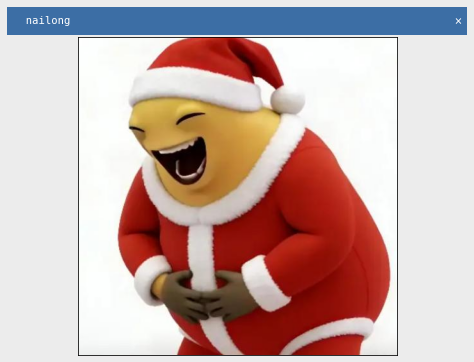

In [73]:
# 演示 2：窗口一闪而过看不见，这里画一张示意图
def draw_window_mock(img, title='nailong'):
    """示意图：cv2.imshow 弹出的独立窗口长什么样（标题栏 + 图像）。"""
    fig = plt.figure(figsize=(6.8, 5.2), facecolor='#ececec')

    # 标题栏
    bar = fig.add_axes([0.03, 0.885, 0.94, 0.075])
    bar.set_facecolor('#3c6ea5')
    bar.set_xticks([]); bar.set_yticks([])
    for s in bar.spines.values():
        s.set_visible(False)
    bar.text(0.012, 0.5, '  ' + title, color='white', fontsize=10.5,
             va='center', family='monospace')
    bar.text(0.988, 0.5, '\u00d7', color='white', fontsize=12, va='center', ha='right')

    # 图像区
    ax = fig.add_axes([0.03, 0.03, 0.94, 0.85])
    ax.imshow(img[:, :, ::-1])
    ax.set_xticks([]); ax.set_yticks([])
    plt.show()


draw_window_mock(img)


In [74]:
# 演示 3：改用 matplotlib —— 把"并排显示多张图"封装成一个函数

def show_img(*imgs: np.ndarray, titles=None) -> None:
    """用 matplotlib 在 Notebook 里并排显示图像。

    - 灰度图（2 维）用 cmap='gray'
    - 彩色图（3 维）需要把 OpenCV 的 BGR 顺序转成 RGB
    """
    plt.figure()
    for idx, img in enumerate(imgs):
        plt.subplot(1, len(imgs), idx + 1)
        if img.ndim == 2:
            plt.imshow(img, cmap='gray')       # 坑二：灰度图必须声明 cmap
        else:
            plt.imshow(img[:, :, ::-1])        # 坑一：BGR -> RGB
        if titles:
            plt.title(titles[idx])
        plt.axis('off')
    plt.show()


print("show_img 已就绪 —— 后面每一节都用它做「原图 vs 处理结果」对比")


show_img 已就绪 —— 后面每一节都用它做「原图 vs 处理结果」对比


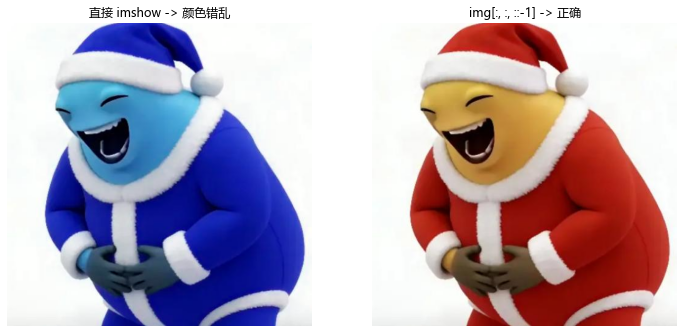

In [75]:
# 演示 4：坑一 —— 不转换通道，颜色就错了
img = cv2.imread('res/nl_santa.png')     # 红帽子，颜色对不对一眼就看出来

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(img)                  # 没转换 -> 红蓝互换
plt.title('直接 imshow -> 颜色错乱')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img[:, :, ::-1])      # BGR -> RGB
#img[高，宽，通道]python中切片[start ：stop ：步长]-1代表倒着取
plt.title('img[:, :, ::-1] -> 正确')
plt.axis('off')
plt.show()


IMREAD_COLOR     : (655, 690, 3) uint8
IMREAD_GRAYSCALE : (655, 690) uint8
IMREAD_UNCHANGED : (655, 690, 3) uint8
cvtColor 转的灰度和直接读灰度一致: False


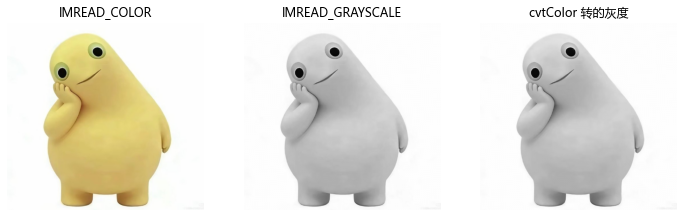

In [76]:
# 演示 5：imread 的三种模式
color = cv2.imread('res/nl_think.png')                          # 默认：BGR 彩色
gray = cv2.imread('res/nl_think.png', cv2.IMREAD_GRAYSCALE)     # 灰度：单通道
raw = cv2.imread('res/nl_think.png', cv2.IMREAD_UNCHANGED)      # 原样：不做任何转换

print("IMREAD_COLOR     :", color.shape, color.dtype)
print("IMREAD_GRAYSCALE :", gray.shape, gray.dtype)
print("IMREAD_UNCHANGED :", raw.shape, raw.dtype)

# 彩色读进来之后也能转灰度
gray2 = cv2.cvtColor(color, cv2.COLOR_BGR2GRAY)
print("cvtColor 转的灰度和直接读灰度一致:", np.array_equal(gray, gray2))

show_img(color, gray, gray2,
         titles=['IMREAD_COLOR', 'IMREAD_GRAYSCALE', 'cvtColor 转的灰度'])


等价关系验证: True
误用后的平均亮度: 152.5  ->  正确: 163.7


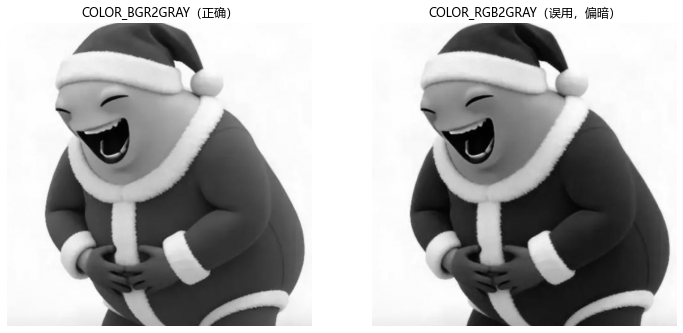

In [77]:
# 演示 6：BGR2GRAY 和 RGB2GRAY 的区别（用错了会偏暗）
img = cv2.imread('res/nl_santa.png')

gray_correct = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)       # 正确：OpenCV 读进来是 BGR
gray_wrong = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)         # 误用：把 BGR 数据当成 RGB

# 先 BGR->RGB 再 RGB2GRAY，与直接 BGR2GRAY 完全等价
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray_equiv = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
print("等价关系验证:", np.array_equal(gray_correct, gray_equiv))
print("误用后的平均亮度: %.1f  ->  正确: %.1f" % (gray_wrong.mean(), gray_correct.mean()))

show_img(gray_correct, gray_wrong,
         titles=['COLOR_BGR2GRAY（正确）', 'COLOR_RGB2GRAY（误用，偏暗）'])


In [78]:
# 演示 7：路径怎么写
print("当前工作目录:", os.getcwd())
print("res 目录里有什么:", os.listdir('res')[:6], '...')

rel = 'res/nl_santa.png'                        # 相对路径
abspath = os.path.abspath(rel)                  # 转成绝对路径
joined = os.path.join('res', 'nl_santa.jpg')    # 用 os.path 拼，更稳妥

print("\n相对路径  :", rel)
print("绝对路径  :", abspath)
print("os.path 拼:", joined)
print("是绝对路径吗?", os.path.isabs(rel), "/", os.path.isabs(abspath))
print("文件存在吗?", os.path.exists(rel))

print("\n相对路径读图成功:", cv2.imread(rel) is not None)
print("绝对路径读图成功:", cv2.imread(abspath) is not None)

# ⚠️ Windows 路径陷阱：反斜杠 '\' 会被 Python 当成转义字符！
good_1 = 'res/nl_think.png'      # 正斜杠写法（这两个文件都在）
good_2 = 'res/rgb.png'
bad_n = 'res\nl_think.png'       # '\n' 变成了换行符
bad_r = 'res\rgb.png'            # '\r' 变成了回车符

print("\n正斜杠写法（正确）：")
print("  ", repr(good_1), " 能找到文件吗 :", os.path.exists(good_1))
print("  ", repr(good_2), " 能找到文件吗 :", os.path.exists(good_2))

print("\n反斜杠写法（错误）：")
print("  ", repr(bad_n), " 能找到文件吗 :", os.path.exists(bad_n), " <- '\\n' 是换行！")
print("  ", repr(bad_r), " 能找到文件吗 :", os.path.exists(bad_r), " <- '\\r' 是回车！")

print("\n原始字符串写法（也可以）：")
print("  ", repr(r'res\nl_think.png'), " 能找到文件吗 :", os.path.exists(r'res\nl_think.png'))
print("\n所以：Windows 路径要么用正斜杠 /，要么在字符串前面加 r。")
print("常见的还有 '\\t'（TAB），比如写成 'res\\tabc.jpg' 同样会找不到文件。")


当前工作目录: d:\0mylearn\Assignment-1-Computer-Vision\视觉教材opencv部分
res 目录里有什么: ['2D_Convolution_Animation.gif', 'close.png', 'coins.jpg', 'dilate.png', 'erode.jpg', 'getperspective_transform_01.png'] ...

相对路径  : res/nl_santa.png
绝对路径  : d:\0mylearn\Assignment-1-Computer-Vision\视觉教材opencv部分\res\nl_santa.png
os.path 拼: res\nl_santa.jpg
是绝对路径吗? False / True
文件存在吗? True

相对路径读图成功: True
绝对路径读图成功: False

正斜杠写法（正确）：
   'res/nl_think.png'  能找到文件吗 : True
   'res/rgb.png'  能找到文件吗 : True

反斜杠写法（错误）：
   'res\nl_think.png'  能找到文件吗 : False  <- '\n' 是换行！
   'res\rgb.png'  能找到文件吗 : False  <- '\r' 是回车！

原始字符串写法（也可以）：
   'res\\nl_think.png'  能找到文件吗 : True

所以：Windows 路径要么用正斜杠 /，要么在字符串前面加 r。
常见的还有 '\t'（TAB），比如写成 'res\tabc.jpg' 同样会找不到文件。


In [79]:
# 演示 8：读图失败的坑
bad = cv2.imread('res/不存在的图.png')
print("读不存在的图 ->", bad)          # 返回 None，而且不报错！

# 所以写代码要"先判断再使用"
img = cv2.imread('res/nl_side.png')
if img is None:
    raise FileNotFoundError('读取失败：res/nl_side.png')
print("读取成功:", img.shape)

# 中文路径也一样读不了（这是更隐蔽的坑）
patch = np.zeros((60, 200, 3), np.uint8)
print("\n用中文文件名存图 ->", cv2.imwrite('out/中文名.png', patch))
print("文件存在吗 ->", os.path.exists('out/中文名.png'))

# 正确做法：用 imencode / imdecode 绕过
ok, buf = cv2.imencode('.png', patch)
buf.tofile('out/中文名.png')
img_zh = cv2.imdecode(np.fromfile('out/中文名.png', dtype=np.uint8), cv2.IMREAD_COLOR)
print("绕过之后 -> 文件存在:", os.path.exists('out/中文名.png'), " 读回来 shape:", img_zh.shape)


读不存在的图 -> None
读取成功: (302, 320, 3)

用中文文件名存图 -> False
文件存在吗 -> True
绕过之后 -> 文件存在: True  读回来 shape: (60, 200, 3)


imwrite 返回值: True True


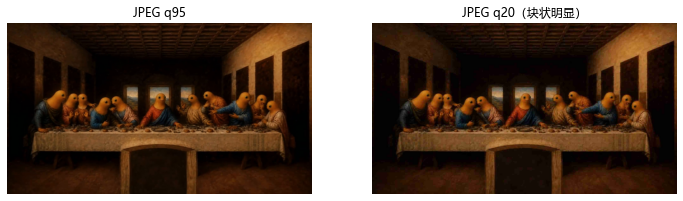

PNG 与原图完全一致: True
JPEG q95 平均差异 : 0.081
JPEG q20 平均差异 : 2.743
q95.jpg           313.7 KB
q20.jpg            55.7 KB
lossless.png     1683.9 KB


In [80]:
# 演示 9：存图 —— JPEG 有损，PNG 无损
img = cv2.imread('res/nl_classic1.jpg')

ok_jpg = cv2.imwrite('out/q95.jpg', img, [cv2.IMWRITE_JPEG_QUALITY, 95])
cv2.imwrite('out/q20.jpg', img, [cv2.IMWRITE_JPEG_QUALITY, 20])
ok_png = cv2.imwrite('out/lossless.png', img)

q95 = cv2.imread('out/q95.jpg')
q20 = cv2.imread('out/q20.jpg')
png = cv2.imread('out/lossless.png')

print("imwrite 返回值:", ok_jpg, ok_png)
show_img(q95, q20, titles=['JPEG q95', 'JPEG q20（块状明显）'])

print("PNG 与原图完全一致:", np.array_equal(img, png))
print("JPEG q95 平均差异 : %.3f" % np.abs(img.astype(int) - q95.astype(int)).mean())
print("JPEG q20 平均差异 : %.3f" % np.abs(img.astype(int) - q20.astype(int)).mean())
for f in ['q95.jpg', 'q20.jpg', 'lossless.png']:
    print(f"{f:14s} {os.path.getsize('out/' + f)/1024:8.1f} KB")


### 视频：读、放、存

OpenCV 读视频和读摄像头是同一套 API，只是 `cv2.VideoCapture()` 的参数不同：

```python
cap = cv2.VideoCapture(0)                    # 0 = 默认摄像头
cap = cv2.VideoCapture('res/nl_video.mp4')   # 或者传视频文件路径
```

| 函数 | 作用 |
| --- | --- |
| `cap.isOpened()` | 判断是否成功打开 |
| `cap.read()` | 读一帧 → `(ret, frame)`；`ret` 为 `False` 表示读完了 |
| `cap.get(propId)` | 读属性：`CAP_PROP_FRAME_WIDTH` / `_HEIGHT` / `_FPS` / `_FRAME_COUNT` … |
| `cap.set(propId, value)` | 设属性，例如 `cap.set(cv2.CAP_PROP_POS_FRAMES, 10)` 跳到第 10 帧 |
| `cap.release()` | **必须调用**，释放资源 |

**写视频**用 `cv2.VideoWriter`：

```python
fourcc = cv2.VideoWriter_fourcc(*'MJPG')            # 编码器：XVID / MJPG / X264
out = cv2.VideoWriter('out/a.avi', fourcc, 20.0, (640, 480))   # 帧率 + (宽, 高)
out.write(frame)
out.release()
```

> ⚠️ **易错点**：`VideoWriter` 的尺寸顺序是 **(宽, 高)**，和 `img.shape` 的 `(高, 宽)` **反过来**！
> 写错了不会报错，但存出来的视频是坏的。


是否成功打开: True
帧宽 CAP_PROP_FRAME_WIDTH : 1280.0
帧高 CAP_PROP_FRAME_HEIGHT: 720.0
帧率 CAP_PROP_FPS         : 25.0
总帧数 CAP_PROP_FRAME_COUNT: 596.0


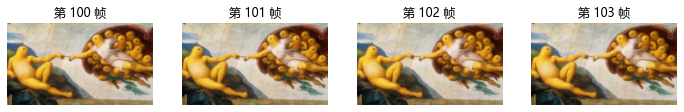

In [81]:
# 演示 10：读视频 —— 抽几帧出来看
cap = cv2.VideoCapture('res/nl_video.mp4')

print("是否成功打开:", cap.isOpened())
print("帧宽 CAP_PROP_FRAME_WIDTH :", cap.get(cv2.CAP_PROP_FRAME_WIDTH))
print("帧高 CAP_PROP_FRAME_HEIGHT:", cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
print("帧率 CAP_PROP_FPS         :", cap.get(cv2.CAP_PROP_FPS))
print("总帧数 CAP_PROP_FRAME_COUNT:", cap.get(cv2.CAP_PROP_FRAME_COUNT))

# 跳到第 100 帧
cap.set(cv2.CAP_PROP_POS_FRAMES, 100)

frames = []
for i in range(4):
    ret, frame = cap.read()
    if not ret:
        break
    frames.append(frame)
cap.release()                       # 用完一定要释放！

show_img(*frames, titles=[f'第 {100+i} 帧' for i in range(len(frames))])


原视频: 1280x720 @ 25.0fps
处理了 596 帧，已写出 out/gray.avi
读回一帧: True (720, 1280, 3)


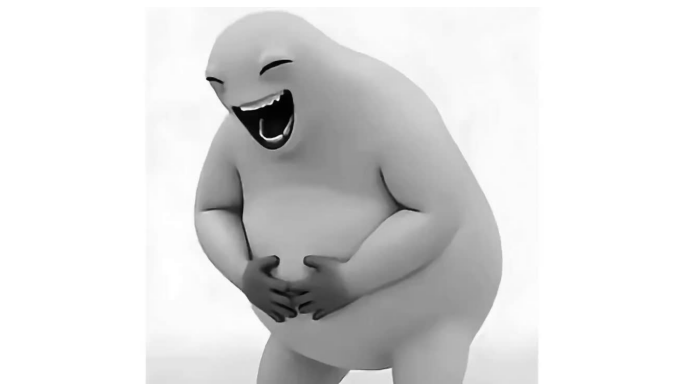

In [82]:
# 演示 11：逐帧遍历 + 保存视频
cap = cv2.VideoCapture('res/nl_video.mp4')

fps = cap.get(cv2.CAP_PROP_FPS)
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
print(f"原视频: {w}x{h} @ {fps}fps")

# 尺寸顺序是 (宽, 高)，和 img.shape 反过来！
fourcc = cv2.VideoWriter_fourcc(*'MJPG')
out = cv2.VideoWriter('out/gray.avi', fourcc, fps, (w, h))

count = 0
while True:
    ret, frame = cap.read()
    if not ret:
        break                        # 读完了
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    out.write(cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR))   # VideoWriter 只认三通道
    count += 1

cap.release()
out.release()
print(f"处理了 {count} 帧，已写出 out/gray.avi")

# 读回来验证
cap = cv2.VideoCapture('out/gray.avi')
ret, frame = cap.read()
cap.release()
print("读回一帧:", ret, frame.shape if ret else None)
show_img(frame)


### ✍️ 练习

1. 用三种模式读 `res/nl_think.png`，打印 `shape / dtype / size`。
2. 用 `cv2.resize` 把 `res/nl_hd13.jpg` 缩到宽 500，打印缩放前后的 `shape`。
3. 把 `res/nl_santa.png` 存成 PNG 和 JPEG(q30)，比较文件大小与平均像素差异。
4. 打印 `res/nl_video.mp4` 的帧率与总帧数，算出它一共播放多少秒。
5. 把 `res/nl_video.mp4` 每隔 10 帧抽一帧，横着拼成一张长图看看。

> ❓ **自测**：为什么"图像处理"本质上就是"数组运算"？


---

# 第 2 章 图像的基本操作：像素 / 通道 / 边框 / ROI

> 🎯 **学习目标**：能自由地取、改图像里的任意一块内容。

## 讲解要点

### 1. 访问和修改像素

```python
px = img[100, 100]          # 访问 (x=100, y=100) 处像素 -> [B, G, R]
blue = img[100, 100, 0]     # 只取蓝色通道
img[100, 100] = [255, 255, 255]     # 改成白色
```

> 💡 **小贴士**：单像素读取还可以用 `img.item(y, x, c)`，更快。
> 但 **NumPy 2.0 已经删除了 `img.itemset()`**，写值请直接用 `img[y, x, c] = v`。

**不要写双重 `for` 循环遍历像素！** 用切片批量赋值：

```python
img[150:170, 150:170] = [0, 255, 0]     # 一次改一整块
```

### 2. 图像属性

| 属性 | 含义 |
| --- | --- |
| `img.shape` | `(高, 宽, 通道)`；灰度图只有 `(高, 宽)` |
| `img.size` | 总像素数 = 高 × 宽 × 通道 |
| `img.dtype` | 数据类型，通常是 `uint8` |

### 3. 拆分和合并通道

```python
b, g, r = cv2.split(img)          # 拆成三个单通道（较慢，尽量少用）
img = cv2.merge((b, g, r))        # 合并回去

b = img[:, :, 0]                  # ✅ 只要一个通道时，用 NumPy 索引更快
img[:, :, 2] = 0                  # 直接把红色通道全部置 0
```

> 注意 `cv2.split()` / `cv2.merge()` 的参数顺序是 **(b, g, r)**，不是 (r, g, b)。

### 4. 边框填充：`cv2.copyMakeBorder`

```python
cv2.copyMakeBorder(src, top, bottom, left, right, borderType[, value])
```

| borderType | 补法 |
| --- | --- |
| `BORDER_CONSTANT` | 用固定颜色填（需传 `value=(B,G,R)`） |
| `BORDER_REPLICATE` | 复制边缘像素 `aaa\|abcdef\|fff` |
| `BORDER_REFLECT` | 反射 `fedcba\|abcdef\|fedcba` |
| `BORDER_REFLECT_101`（默认） | 反射 101 `gfedcb\|abcdef\|gfedcb` |
| `BORDER_WRAP` | 环绕 `cdefgh\|abcdef\|abcdef` |

### 5. ROI：感兴趣区域

ROI（Region Of Interest）就是图像里**我们关心的那一块**，用 NumPy 切片就能取出来，还能直接赋值：

```python
roi = img[20:320, 80:340]        # ⚠️ 先 y 后 x，切片左闭右开
img[0:300, 0:260] = roi          # 把 ROI 复制到别处
```

**为什么一定要裁 ROI**：

| 好处 | 说明 |
| --- | --- |
| **抗干扰** | 画面里无关的东西直接消失，不用再想办法排除 |
| **提速** | 1920×1080 → 640×480，像素少 85%，处理快好几倍 |
| **简化阈值** | 局部光照更均匀，一组阈值就够 |

> 💡 **小贴士**：ROI 是**性价比最高的抗干扰手段**。
> 以后调不出阈值时，第一个该问自己的不是"阈值怎么设"，而是"我为什么不先裁 ROI"。

### 6. ⚠️ 切片是「视图」不是「副本」

```python
roi = img[0:100, 0:100]          # 视图：改 roi 会改到 img！
roi = img[0:100, 0:100].copy()   # 副本：互不影响
```

> ⚠️ **易错点**：这个坑一定要亲手试一次 ——
> 在 ROI 上画了个框，结果发现**原图也被画了**。踩过一次就不会再忘。

> ❓ **自测**：为什么"先 ROI 后分割"比"先分割后裁"好？


img[100, 100]      = [ 34 132 194]   <- [B, G, R]
蓝色通道 img[100,100,0] = 34
更快的单像素读取 item(100,100,0) = 34


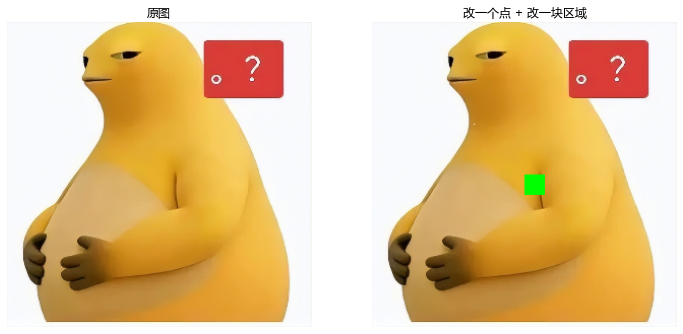

In [83]:
# 演示 1：访问和修改像素
img = cv2.imread('res/nl_question.png')
img = cv2.resize(img, (300, 300))

# 访问像素（注意先 y 后 x）
print("img[100, 100]      =", img[100, 100], "  <- [B, G, R]")
print("蓝色通道 img[100,100,0] =", img[100, 100, 0])
print("更快的单像素读取 item(100,100,0) =", img.item(100, 100, 0))

# 修改像素
mod = img.copy()
mod[100, 100] = [255, 255, 255]          # 单个点改成白色
mod[150:170, 150:170] = [0, 255, 0]      # 切片批量：一整块改成绿色

show_img(img, mod, titles=['原图', '改一个点 + 改一块区域'])


In [84]:
# 演示 2：图像属性
img = cv2.imread('res/nl_hd01.jpg')

print("shape:", img.shape, "  <- (高, 宽, 通道)")
print("size :", img.size, "  <- 总像素数 = 高 x 宽 x 通道")
print("dtype:", img.dtype)
print("高 =", img.shape[0], " 宽 =", img.shape[1], " 通道 =", img.shape[2])
print("nbytes: %.1f MB" % (img.nbytes / 1024 / 1024))

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
print("灰度图 shape:", gray.shape, "  <- 只有两个维度")

# 内存换算：算法为什么要讲究效率
fps, sec = 30, 60
print("\n一张 1080p 彩色图 = %.1f MB" % (img.nbytes / 1024 / 1024))
print("%dfps 跑 %ds = %.1f GB 的像素吞吐量" % (fps, sec, img.nbytes * fps * sec / 1024**3))


shape: (1080, 1920, 3)   <- (高, 宽, 通道)
size : 6220800   <- 总像素数 = 高 x 宽 x 通道
dtype: uint8
高 = 1080  宽 = 1920  通道 = 3
nbytes: 5.9 MB
灰度图 shape: (1080, 1920)   <- 只有两个维度

一张 1080p 彩色图 = 5.9 MB
30fps 跑 60s = 10.4 GB 的像素吞吐量


merge 回去和原图一样吗: True
两种方式取蓝通道结果一致: True


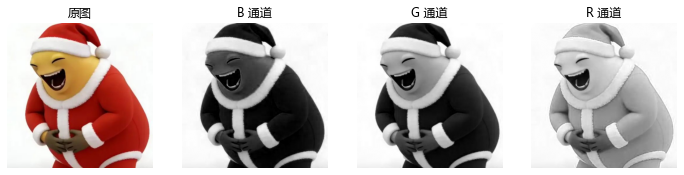

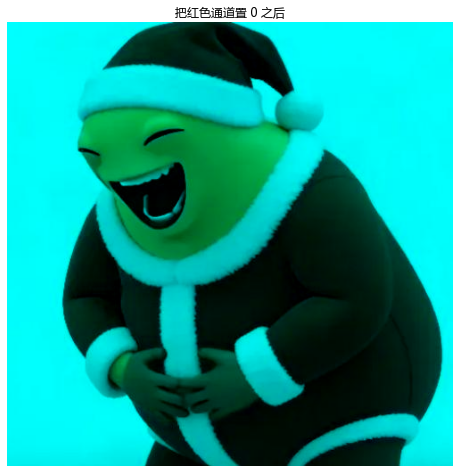

In [85]:
# 演示 3：拆分和合并通道
img = cv2.imread('res/nl_santa.png')

b, g, r = cv2.split(img)         # 拆分（返回 3 个新数组，较慢）
merged = cv2.merge((b, g, r))    # 合并
print("merge 回去和原图一样吗:", np.array_equal(img, merged))

# 只要一个通道时，NumPy 索引更快
blue_np = img[:, :, 0]
print("两种方式取蓝通道结果一致:", np.array_equal(b, blue_np))

# 把红色通道全部置 0（图像会偏青）
no_red = img.copy()
no_red[:, :, 2] = 0

show_img(img, b, g, r, titles=['原图', 'B 通道', 'G 通道', 'R 通道'])
show_img(no_red, titles=['把红色通道置 0 之后'])


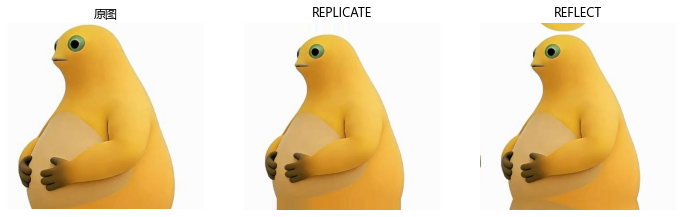

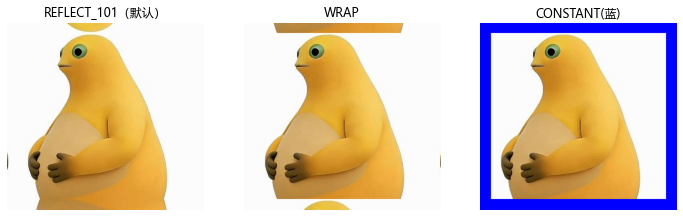

In [86]:
# 演示 4：边框填充 —— 五种 borderType
img = cv2.imread('res/nl_side.png')
p = 20      # 四周各补 20 像素

replicate = cv2.copyMakeBorder(img, p, p, p, p, cv2.BORDER_REPLICATE)
reflect = cv2.copyMakeBorder(img, p, p, p, p, cv2.BORDER_REFLECT)
reflect101 = cv2.copyMakeBorder(img, p, p, p, p, cv2.BORDER_REFLECT_101)
wrap = cv2.copyMakeBorder(img, p, p, p, p, cv2.BORDER_WRAP)
# value 是 BGR 顺序：(255, 0, 0) 才是蓝色
constant = cv2.copyMakeBorder(img, p, p, p, p, cv2.BORDER_CONSTANT, value=(255, 0, 0))

show_img(img, replicate, reflect, titles=['原图', 'REPLICATE', 'REFLECT'])
show_img(reflect101, wrap, constant, titles=['REFLECT_101（默认）', 'WRAP', 'CONSTANT(蓝)'])


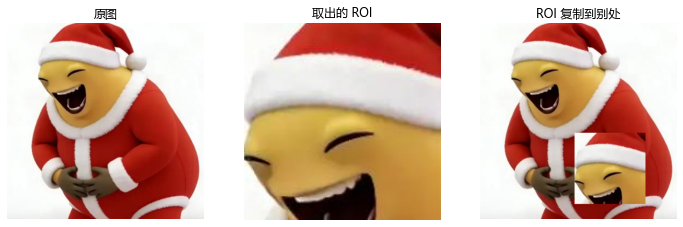

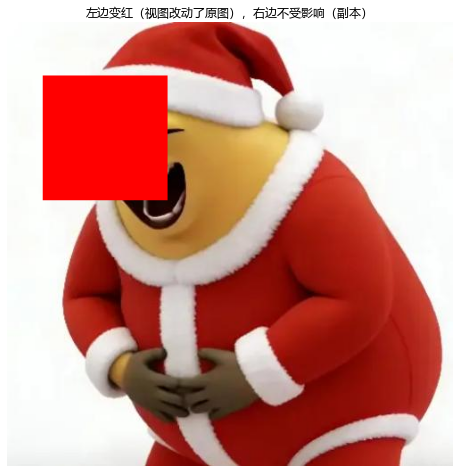

原图像素数: 747000  ROI 像素数: 498000
像素数减少: 33%


In [87]:
# 演示 5：ROI 与"视图 / 副本"的坑
img = cv2.imread('res/nl_santa.png')

# ① 取 ROI 并复制到别处
roi = img[20:200, 80:260]
img2 = img.copy()
img2[280:460, 240:420] = roi          # 把 ROI 复制到右下角
show_img(img, roi, img2, titles=['原图', '取出的 ROI', 'ROI 复制到别处'])

# ② 视图 vs 副本：改"视图"会改到原图！
img3 = img.copy()
view = img3[60:200, 40:180]             # 视图
copy = img3[60:200, 180:320].copy()     # 副本（加了 .copy()）
view[:] = (0, 0, 255)                   # 改成红色
copy[:] = (0, 255, 0)                   # 改成绿色
show_img(img3, titles=['左边变红（视图改动了原图），右边不受影响（副本）'])

# ③ 裁 ROI 也能提速
h, w = img.shape[:2]
roi_big = img[h // 3:, :]
print("原图像素数:", img.size, " ROI 像素数:", roi_big.size)
print("像素数减少: %.0f%%" % ((1 - roi_big.size / img.size) * 100))


### ✍️ 练习

1. 用 `res/nl_point.png` 打印几个像素的 `[B,G,R]`，找出"背景"和"主体"的差别。
2. 把 `res/nl_question.png` 的**上半部分**取出来，把**下半部分**覆盖成它的内容（注意先 `.copy()`）。
3. 用 `cv2.copyMakeBorder` 给 `res/nl_side.png` 补一圈 30 像素的白色边框，存入 `out/`。
4. 用 `res/nl_hd17.jpg` 裁出**中心 1/4**，打印原图与 ROI 的 shape，算出像素数减少多少。
5. 比较 `cv2.split` 取一个通道 和 `img[:, :, i]` 取一个通道的结果是否相同。

> ❓ **自测**：为什么说 ROI 是"性价比最高的抗干扰手段"？


---

# 第 3 章 颜色空间：灰度 / BGR / HSV

> 🎯 **学习目标**：知道同一个像素能用哪几套"坐标系"描述，看得懂 0~255 / 0~1 两种刻度，
> 并能把目标颜色用 HSV 区间说清楚。
> 💡 **小贴士**：这一章是全篇最值钱的。赛场上一大半"识别不到目标"，根因就在这。

## 讲解要点

同一个像素，可以用不同的"几个数"来描述。经典视觉里最常用的就三套：

| 空间 | 每个像素用几个数 | 这几个数是什么 |
| --- | --- | --- |
| **灰度 GRAY** | **1 个** | 亮度 |
| **BGR** | 3 个 | 蓝、绿、红各自的强度 |
| **HSV** | 3 个 | 色相、饱和度、明度 |
| **BGRA** | **4 个** | 上面 3 个颜色 + **alpha 透明度** |

### 1. BGR 顺序

OpenCV 默认读进来的是 **BGR** 顺序，每个像素 3 个字节：

| 颜色 | BGR |
| --- | --- |
| 黑 | `(0,0,0)` |
| 白 | `(255,255,255)` |
| 红 | `(0,0,255)` |
| 绿 | `(0,255,0)` |
| 蓝 | `(255,0,0)` |
| 黄 | `(0,255,255)` |

**先建立一个直观印象**：一个像素的颜色，就是**三维立方体里的一个点** ——
三个轴分别是 R、G、B，每个轴的范围都是 0~255。

![RGB 色彩空间：颜色就是 R G B 三维空间里的一个点](res/rgb.png)

- 立方体的 8 个顶点就是 8 种「纯色」：黑 `(0,0,0)`、白 `(255,255,255)`、红、绿、蓝、青、品红、黄
- 越往立方体内部走，颜色越「混」、越灰
- 图中那个亮点就是 `(R, G, B) = (83, 150, 60)` 这个颜色

> ⚠️ **易错点**：示意图画的是**学术上通用的 RGB** 顺序；
> **OpenCV 存的是 BGR**（顺序反了）。模型是同一个，但通道号要对准。

拆分通道两种写法：

```python
b, g, r = cv2.split(img)     # 返回 3 个新数组（慢）
b = img[:, :, 0]             # NumPy 切片（视图，快）—— 推荐
```

> ⚠️ **易错点**：写 `b, g, r = cv2.split(img)` 时，**左边变量个数必须和通道数一致**。
> 如果 `img` 是 4 通道（BGRA），这句会直接抛
> `ValueError: too many values to unpack (expected 3)`。

**演示技巧**：单通道直接显示是灰度图，看不出"哪块偏红"。
把通道放回一张黑画布的对应位置，就能**着色显示**：

```python
only_r = np.zeros_like(img)
only_r[:, :, 2] = img[:, :, 2]
```

### 2. 灰度图：只有亮度，没有颜色

灰度图是**最简单的图像**：每个像素只有 **1 个数字**，表示亮度。

| 值 | 看起来是 |
| --- | --- |
| `0` | 纯黑 |
| `255` | 纯白 |
| 中间的 | 各种深浅的灰 |

**形状会少一个维度**：

```python
img.shape      # (高, 宽, 3)   <- 彩色：3 个通道
gray.shape     # (高, 宽)      <- 灰度：只有 2 个维度
```

**怎么转**：

```python
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)   # 最常用
gray = cv2.imread('res/nl_think.png', 0)       # 也可以读的时候直接按灰度读
```

**它不是"三个通道取平均"**。OpenCV 用的是**按人眼敏感度加权**：

$$Y = 0.299R + 0.587G + 0.114B$$

为什么加权？因为**人眼对绿色最敏感、对蓝色最不敏感** ——
数字上同样"亮"的绿和蓝，人看起来绿色亮得多。加权之后算出来的灰度，才符合人眼的明暗感受。

> 💡 **小贴士**：系数不用背，记住 **绿色权重最大（0.587）、蓝色最小（0.114）** 就够了。
> 顺带记住：纯红转灰度是 **76**，纯绿是 **150**，纯蓝只有 **29**。

> ⚠️ **易错点**：正因为 B 和 R 的系数不一样，`COLOR_BGR2GRAY` 和 `COLOR_RGB2GRAY` **结果不同**。
> 用错了不报错，但结果会偏暗（第 1 章演示过）。

**为什么经典视觉这么爱用灰度**：

| 好处 | 说明 |
| --- | --- |
| **数据量只有 1/3** | 3 通道 → 1 通道，内存和计算量都大幅下降 |
| **算法大多按单通道设计** | `cv2.equalizeHist`、`cv2.findContours` 会**直接报错**；`cv2.threshold`、`cv2.Sobel` 虽然不报错，但会**每个通道各算一遍**，结果通常不是你想要的 |
| **专注形状和纹理** | 去掉颜色干扰，只看"哪里亮哪里暗"（边缘、轮廓） |

**代价**：颜色信息没了。靠颜色区分的目标（比如一个红球和一个蓝球），
如果亮度差不多，在灰度图里就**分不开**了 —— 这种时候必须用 HSV，不能用灰度。

> ⚠️ **易错点**：灰度图用 matplotlib 显示时**必须写 `cmap='gray'`**，
> 否则会被当成彩色图渲染，看着像热力图。

> ⚠️ **易错点**：别用"把灰度图转回 3 通道彩色图"来糊弄算法。
> `cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)` 出来的图**看着还是灰的，但真的是 3 通道**，
> 喂给 `cv2.equalizeHist` 一样报错。
> 判断通道数看 `img.shape`（是 `(高, 宽)` 还是 `(高, 宽, 3)`），**不要靠眼睛看**。

### 3. HSV 三个分量

| 分量 | 含义 | 范围 | 直觉 |
| --- | --- | --- | --- |
| **H** 色相 | 是什么颜色 | 0 ~ 179（或 0~255） | 色环一圈：红→黄→绿→青→蓝→紫→红 |
| **S** 饱和度 | 颜色多纯 | 0 ~ 255 | 0 = 灰白，255 = 最鲜艳 |
| **V** 明度 | 多亮 | 0 ~ 255 | 0 = 全黑，255 = 最亮 |

![HSV 色彩空间：色相是绕圈的角度，饱和度是半径，明度是高度](res/HSV.png)

**怎么读这张图**：

- **右边的色环**：色相 H 沿着环转一圈。0° 是红，60° 是黄，120° 是绿，
  180° 是青，240° 是蓝，300° 是品红，360° 又回到红
  —— 这就是为什么**红色要分两段**（首尾相接的地方被切开了）
- **左边的圆锥**：把色环竖起来看

| 分量 | 几何意义 | 图里的范围 |
| --- | --- | --- |
| **H** 色相 | 绕一圈的**角度** | 0° ~ 360° |
| **S** 饱和度 | 从圆心向外的**半径** | 0（灰白）~ 1（最纯） |
| **V** 明度 | 从上往下的**高度** | 1（最亮）~ 0（全黑） |

**换算到 OpenCV**：图里用的是 0~360° 和 0~100%（即 0~1），
但 OpenCV 为了塞进 `uint8`（0~255）压缩过了：

| 颜色 | 色环角度 | `COLOR_BGR2HSV`（H: 0~179） | `COLOR_BGR2HSV_FULL`（H: 0~255） |
| --- | --- | --- | --- |
| 红 | 0° / 360° | 0 | 0 |
| 黄 | 60° | 30 | 43 |
| 绿 | 120° | 60 | 85 |
| 青 | 180° | 90 | 128 |
| 蓝 | 240° | 120 | 171 |
| 品红 | 300° | 150 | 213 |

> 💡 **小贴士**：记住这个换算 ——
> `H_标准版 = 角度 / 2`，`H_FULL = 角度 x 255 / 360 ≈ 角度 / 1.41`。
> 看到"色相 120°"就能心算出 OpenCV 里是 60（标准版）或 85（FULL）。

> 💡 **注意**：上图里的 `S`、`V` 写的是 **0~1**，而 OpenCV 里是 **0~255**。
> 这正是第 9 节要讲的"两把尺子"。

### 4. ⭐ 为什么做颜色识别要用 HSV

光照变强时，同一个红色物体在 **BGR** 里三个通道**全都会变** —— 昨天调好的阈值今天失效。
但在 **HSV** 里，**H（色相）几乎不变**，变的只是 V。

**结论：要"按颜色"找目标 → 用 HSV。**

顺带对比一下三种空间各自的定位：

| 空间 | 什么时候用它 |
| --- | --- |
| 灰度 | 做**形状 / 边缘 / 轮廓**（不管颜色） |
| BGR | 图像**读写、显示**的默认格式 |
| HSV | 做**颜色分割**（按颜色挑目标） |
| BGRA | 需要**透明叠加**时（贴 logo、画 HUD） |

### 5. 颜色空间怎么切换：`cv2.cvtColor`

前面一直在用 `cv2.cvtColor`，这里正式讲一下它。

**函数签名（一共 4 个参数）**：

```python
dst = cv2.cvtColor(src, code[, dst[, dstCn]])   # [] 表示可以省略
```

| 位置 | 参数 | 含义 | 平时要不要写 |
| --- | --- | --- | --- |
| 1 | **`src`** | 输入图像（灰度 / BGR / BGRA 都可以） | **必写** |
| 2 | **`code`** | 转换码 `cv2.COLOR_...`，告诉它"从哪转到哪" | **必写** |
| 3 | `dst` | 输出图像。想复用一块已有内存时传进来 | 省略 |
| 4 | `dstCn` | 输出通道数，`0` = 由 `code` 自动决定 | 省略 |

> 💡 **小贴士**：99% 的情况只写前两个参数就够了：
> ```python
> gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
> ```
> （OpenCV 4.13 的文档里还有一个可选的 `hint` 参数，用于提示硬件加速，**学生阶段用不到**。）

**第 3 个参数 `dst` 什么时候用** —— 想让结果**写进一块已经准备好的数组**里，
避免每帧都重新申请内存（视频循环里会这么干）：

```python
dst = np.empty(img.shape[:2], np.uint8)     # 先准备好内存
out = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY, dst)
print(out is dst)                           # True —— 返回的就是你传进去的那块内存
```

**`code` 从哪来？** OpenCV 里有 **300 多个**颜色转换码，名字都以 `cv2.COLOR_` 开头，
可以直接列出来看：

```python
print(len([i for i in dir(cv2) if i.startswith('COLOR_')]))
```

**常用转换码（记住这几个就够用了）**：

| 转换码 | 从 → 到 | 干什么用 |
| --- | --- | --- |
| `COLOR_BGR2GRAY` | BGR → 灰度 | 单通道处理（阈值、Canny） |
| `COLOR_GRAY2BGR` | 灰度 → BGR | 灰度图要写进视频、要和彩色图做运算时 |
| `COLOR_BGR2RGB` | BGR → RGB | 交给 matplotlib / Pillow 显示 |
| `COLOR_RGB2BGR` | RGB → BGR | 反方向 |
| `COLOR_BGR2HSV` | BGR → HSV | **颜色分割的主力**（H: 0~179） |
| `COLOR_BGR2HSV_FULL` | BGR → HSV | 同上，但 H: 0~255（**本讲义统一用它**） |
| `COLOR_BGRA2BGR` | BGRA → BGR | 脱掉 alpha 通道 |
| `COLOR_BGR2BGRA` | BGR → BGRA | 补一个 alpha（全是 255，不透明） |
| `COLOR_BGR2LAB` | BGR → Lab | 光照变化大时比 HSV 更稳 |
| `COLOR_BGR2YCrCb` | BGR → YCrCb | 肤色检测常用 |

**图 → 图，只是换个坐标系**：

```text
BGR ──┐
      ├─→ GRAY / HSV / LAB / YCrCb / RGB ...
      └─  都是同一个像素，用不同的 "几个数" 去描述它
```

**四个坑**：

> ⚠️ **① `src` 不能是空图（`None`）**
> 否则会报：
> ```text
> (-215:Assertion failed) !_src.empty() in function 'cv::cvtColor'
> ```
> 见到这个报错，**往回找那一行 `cv2.imread`** —— 十有八九是路径写错了。

> ⚠️ **② `src` 的 `dtype` 只能是 `uint8` / `uint16` / `float32`**
> `img.astype(float)`（Python 的 `float` 就是 **`float64`**）或 `img.astype(np.int32)`
> 都会直接报 `(-2:Unspecified error) ... CvtHelper`。**必须写 `astype(np.float32)`。**

> ⚠️ **③ `BGR2GRAY` 和 `RGB2GRAY` 不是一回事**
> 灰度公式里 R 和 B 的系数不同（`0.299R + 0.587G + 0.114B`），用错了不会报错，
> 但结果会**偏暗**。第 1 章演示过。

> ⚠️ **④ 每次转换都有开销**
> 别在一帧里反复转来转去。要么开头转好一直用，要么全程统一一个空间。

> 💡 **小贴士**：不确定用哪个转换码，在 Notebook 里打 `cv2.COLOR_` 然后按 <kbd>Tab</kbd>，
> 补全列表会直接弹出来。

### 6. ⚠️ OpenCV 有两套 HSV，本讲义统一用 `_FULL`

| 转换码 | H 范围 | S / V |
| --- | --- | --- |
| `cv2.COLOR_BGR2HSV` | **0 ~ 179** | 0 ~ 255 |
| **`cv2.COLOR_BGR2HSV_FULL`** | **0 ~ 255** | 0 ~ 255 |

> 为什么 H 是 0~179 而不是 0~360？因为要**塞进 `uint8`**（0~255），所以把 360° 对半砍了。

**颜色区间表（FULL 制，照着查就行）**：

| 颜色 | H 范围 |
| --- | --- |
| 红 | **0~14 与 243~255**（跨 0 点，必须分两段） |
| 橙 | 15~30 |
| 黄 | 31~48 |
| 绿 | 49~115 |
| 青 / 蓝 | 116~160 |
| 紫 | 161~242 |

> ⚠️ **易错点**：抄网上的代码前，先确认它用的是哪一套 HSV。
> 换算关系：`H_FULL ≈ H_179 × 1.417`。这是最常见的翻车点。

### 7. 怎么知道某个颜色/某个点的 HSV 值？

**方法一：算一个已知颜色的 HSV**

```python
green = np.uint8([[[0, 255, 0]]])              # BGR 里的纯绿
print(cv2.cvtColor(green, cv2.COLOR_BGR2HSV))  # 看看它的 H
```

**方法二：从图里采样** —— 先给图叠加坐标网格 → 肉眼定位 → 打印该点 HSV。

> ❓ **自测**：为什么"红色"要分成两段区间？只用 `0~14` 会漏掉什么？
> （答：红色在色环上跨 0 点，H 既接近 255 又接近 0。）

### 8. 第四个通道：alpha（透明度）

前面所有图都是 **3 通道**。但 PNG 格式允许带**第 4 个通道 —— alpha（A）**，表示**透明度**：

| 通道 | 含义 | 范围 |
| --- | --- | --- |
| B / G / R | 颜色 | 0 ~ 255 |
| **A（alpha）** | **这一点的透明程度**：`0` = 全透明，`255` = 完全不透明 | 0 ~ 255 |

**形状上就多一个数**：

```python
bgr.shape      # (高, 宽, 3)
bgra.shape     # (高, 宽, 4)   <- 多了 alpha
```

**怎么读进来**：`cv2.imread` **默认会把 alpha 丢掉**，想保留必须用 `cv2.IMREAD_UNCHANGED`：

```python
a = cv2.imread('res/rgb.png')                        # (359, 1284, 3)   alpha 被丢了
b = cv2.imread('res/rgb.png', cv2.IMREAD_UNCHANGED)  # (359, 1284, 4)   4 个通道都在
```

> 💡 **小贴士**：`res/` 里的 `rgb.png`、`HSV.png`、`nailong5.png` 本身就是 4 通道 PNG，
> 可以直接拿来试。（它们的 alpha 全是 255，也就是"完全不透明"，所以看不出区别。）
> 另外 `res/nl_santa.png` 是 3 通道 —— 用 `IMREAD_UNCHANGED` 读出来也还是 3 通道。
> `IMREAD_UNCHANGED` 的规则是"**文件里有什么就给什么**"，文件里本来没有 alpha 就变不出来。

**BGRA 怎么转**：

| 转换码 | 结果形状 | alpha 去哪了 |
| --- | --- | --- |
| `COLOR_BGRA2BGR` | (高, 宽, 3) | **直接丢掉**（只脱一层壳） |
| `COLOR_BGRA2GRAY` | (高, 宽) | **丢掉**，再按加权公式转灰度 |
| `COLOR_BGR2BGRA` | (高, 宽, 4) | **新补的 alpha 全是 255**（不透明） |
| `COLOR_GRAY2BGRA` | (高, 宽, 4) | 同上 |

> ⚠️ **易错点**：`cvtColor` **永远不会替你"合成"透明效果**。
> 把带透明白边的 logo 直接 `COLOR_BGRA2BGR` 贴到图上，**透明区域会露出下面原来那层像素**，
> 看起来就是一块黑块或色块。想要真正的透明，必须自己按 alpha **加权混合**：

$$\text{结果} = \text{前景} \times \alpha + \text{背景} \times (1 - \alpha)$$

> 💡 **小贴士**：想让两张图合起来，其实还有更简单的办法 ——
> **第 4 章的按位运算（`cv2.bitwise_and/or`）抠图**做的正是这件事，
> 只不过它用的是**二值掩膜**（要么全要、要么全不要），
> 而 alpha 可以做**渐变过渡**（羽化边缘）。二者的思想是同一个。

> ⚠️ **易错点**：**通道数不一致的两个数组不能直接做运算**。
> `cv2.add(3通道图, 4通道图)`、`cv2.bitwise_and(...)` 都会报
> `(-209:Sizes of input arguments do not match)`。
> 要把 4 通道降成 3 通道，或者给 3 通道补成 4 通道，**先对齐再说**。

### 9. 数值刻度：0~1 还是 0~255？

回头看看前面两张图，它们其实"对不上"：

- `res/rgb.png` 写着每个轴 **0~255**
- `res/HSV.png` 写着 S 和 V 是 **0 ~ 1**

**同一张图，为什么两种刻度？** 因为这是**两把不同的尺子，量的是同一件事**：

| 刻度 | 谁在用 | "满格"是 |
| --- | --- | --- |
| **0 ~ 255** | OpenCV（`uint8`）、网页的 `#FF0000` | 255 |
| **0 ~ 1**（也写成 0~100%） | 论文 / 教科书 / 深度学习框架 / CSS 的 `rgb(100%,0,0)` | 1.0 |

纯红的两种写法 —— `(255, 0, 0)` 和 `(1.0, 0.0, 0.0)`：
**不是两种颜色，是同一个颜色。**

#### 怎么互转

```python
f = (u / 255.0).astype(np.float32)       # 0~255 -> 0~1
u = (f * 255).round().astype(np.uint8)   # 0~1 -> 0~255
```

#### 在 OpenCV 里，用哪把尺子由 `dtype` 决定

| `dtype` | 一个像素占几字节 | 习惯上的刻度 |
| --- | --- | --- |
| `uint8` | 1 | **0 ~ 255**（OpenCV 的默认世界） |
| `float32` | 4 | **0 ~ 1**（约定），也可以自己用 0~255 |
| `float64` | 8 | ⚠️ **OpenCV 大部分函数不支持**（`cvtColor` 直接报错） |

> ⚠️ **易错点**：**`cvtColor` 不会帮你换刻度。**
> 喂进去 0~1，出来还是 0~1；喂进去 0~255，出来还是 0~255。
> （实测：`float32` 且 0~1 的图转灰度，输出的最大值正好是 `1.0`。）**刻度得自己保证一致。**

> ⚠️ **易错点**：**阈值要和刻度配套。**
> 0~255 的图上写 `thresh=127`、`maxval=255`；
> 换成 0~1 的 `float32` 图，就得写 `thresh=0.5`、`maxval=1.0`。
> 抄代码时忘了改，就会得到一张全白或全黑的掩膜。

> ⚠️ **易错点**：`cv2.imwrite` 存 `float32` 图时会**自动降级成 `uint8`**（并打一行警告）。
> 于是把 0~1 的 float 图直接存出去，等于把 `0~1` 当成 `0~1` 的 `uint8` —— **存出来几乎全黑**。
> 存之前先 `(f * 255).astype(np.uint8)`。

#### 什么时候真的需要 0~1？

| 场景 | 为什么 |
| --- | --- |
| 喂给 PyTorch / TensorFlow | 框架要求输入归一化到 0~1 |
| **乘除 / 加权运算** | `uint8` 只能存整数，一乘就丢精度，还容易**溢出**（第 4 章会看到 `img + 80` 变成黑斑） |
| 光照 / 物理模型 | `0.5` 表示"一半能量"比 `127` 直观 |
| 传递中间结果 | 比如把 `H` 除以 360 归一化，再按角度算 |

**其余情况（读图、显示、存图、阈值、形态学运算）一律用 OpenCV 默认的 `uint8` 0~255。**

> 💡 **小贴士**：不确定当前是什么刻度，打印一下就知道了：
> ```python
> print(img.dtype, img.min(), img.max())
> ```
> `uint8` 配 `0~255`、`float32` 配 `0~1` —— 这是最常见的两种组合。
> 拿到一份别人的代码，**先跑这一句**，能省掉一大半调试时间。

> 💡 **想再往下挖**：`dtype` 那七个类型怎么选、`ddepth` 为什么能"救回"边缘、
> "像素带小数"时怎么安全地转回 `uint8` —— 这些超出本章范围的深水内容，
> 都搬到 **《OpenCV 选学讲义》第 6 章**了。


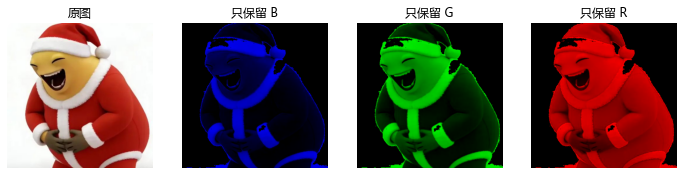

In [88]:
# 演示 1：拆通道 + 着色显示
nailong = cv2.imread('res/nl_santa.png')
b, g, r = cv2.split(nailong)                  # 拆出来的三个通道，单独看都是灰度图

# 着色显示：把通道放回一张黑画布的对应位置（0 -> B，1 -> G，2 -> R）
only_b, only_g, only_r = np.zeros_like(nailong), np.zeros_like(nailong), np.zeros_like(nailong)
only_b[:, :, 0] = b
only_g[:, :, 1] = g
only_r[:, :, 2] = r

# 这张图是白底 —— 白 = (255,255,255)，三个通道都满亮，直接看就是"满屏蓝/绿/红"，
# 把白底涂黑主体才跳出来（红衣服在 B/G 里几乎全黑，在 R 里最亮）
white_bg = (b > 235) & (g > 235) & (r > 235)  # 注意用 & 而不是 and
only_b[white_bg] = 0
only_g[white_bg] = 0
only_r[white_bg] = 0

show_img(nailong, only_b, only_g, only_r,
         titles=['原图', '只保留 B', '只保留 G', '只保留 R'])


H 范围: 0 ~ 255
S 范围: 0 ~ 255
V 范围: 0 ~ 255


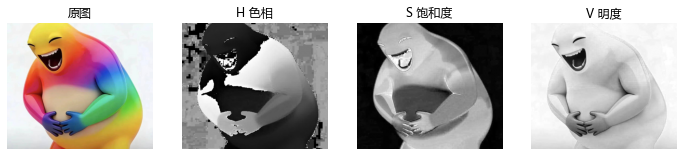

In [89]:
# 演示 2：H / S / V 三张图长什么样
rainbow = cv2.imread('res/nl_rainbow.png')          # 彩虹渐变，H 跨度最大
rainbow_hsv = cv2.cvtColor(rainbow, cv2.COLOR_BGR2HSV_FULL)
h, s, v = cv2.split(rainbow_hsv)

print("H 范围:", h.min(), "~", h.max())
print("S 范围:", s.min(), "~", s.max())
print("V 范围:", v.min(), "~", v.max())

show_img(rainbow, h, s, v, titles=['原图', 'H 色相', 'S 饱和度', 'V 明度'])


In [90]:
# 演示 3：算一个已知颜色的 HSV 值（不用猜）
for name, bgr in [('纯红', (0, 0, 255)), ('纯绿', (0, 255, 0)),
                  ('纯蓝', (255, 0, 0)), ('纯黄', (0, 255, 255))]:
    px = np.uint8([[[*bgr]]])                       # 必须是 3 维数组
    hsv_full = cv2.cvtColor(px, cv2.COLOR_BGR2HSV_FULL)
    hsv_std = cv2.cvtColor(px, cv2.COLOR_BGR2HSV)
    print(f"{name}  BGR={bgr}  HSV(标准)={hsv_std.ravel()}  HSV(FULL)={hsv_full.ravel()}")

print("\n可以看到：FULL 制的 H 大约是标准制的 1.417 倍")


纯红  BGR=(0, 0, 255)  HSV(标准)=[  0 255 255]  HSV(FULL)=[  0 255 255]
纯绿  BGR=(0, 255, 0)  HSV(标准)=[ 60 255 255]  HSV(FULL)=[ 85 255 255]
纯蓝  BGR=(255, 0, 0)  HSV(标准)=[120 255 255]  HSV(FULL)=[171 255 255]
纯黄  BGR=(0, 255, 255)  HSV(标准)=[ 30 255 255]  HSV(FULL)=[ 43 255 255]

可以看到：FULL 制的 H 大约是标准制的 1.417 倍


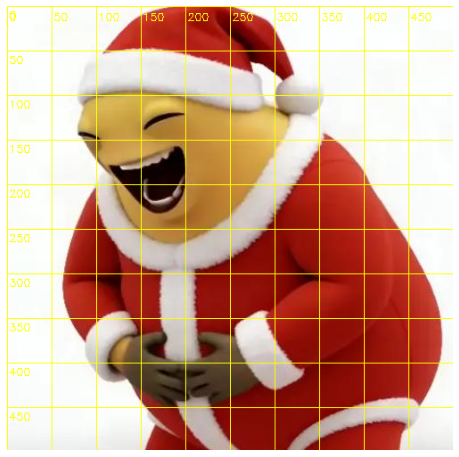

帽子（红）      (150, 60)  BGR=[234 238 239]  HSV_FULL=[ 34   5 239]
脸（黄）       (230,200)  BGR=[ 48 123 185]  HSV_FULL=[ 23 189 185]
背景（灰）      ( 30, 30)  BGR=[253 254 252]  HSV_FULL=[107   2 254]


In [91]:
# 演示 4：叠加坐标网格，从图里采样真实像素的 HSV
img = cv2.imread('res/nl_santa.png')
h, w = img.shape[:2]

grid = img.copy()          # 网格间隔 50 像素，照着网格就能读出坐标
for x in range(0, w, 50):
    cv2.line(grid, (x, 0), (x, h), (0, 255, 255), 1)
    cv2.putText(grid, str(x), (x + 2, 16), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 255), 1)
for y in range(0, h, 50):
    cv2.line(grid, (0, y), (w, y), (0, 255, 255), 1)
    cv2.putText(grid, str(y), (2, y + 14), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 255), 1)
show_img(grid)

# 照着网格读出坐标，打印这些点的 HSV
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV_FULL)
for name, (px, py) in {'帽子（红）': (150, 60),
                       '脸（黄）':   (230, 200),
                       '背景（灰）': (30, 30)}.items():
    print(f"{name:10s} ({px:3d},{py:3d})  BGR={img[py, px]}  HSV_FULL={hsv[py, px]}")


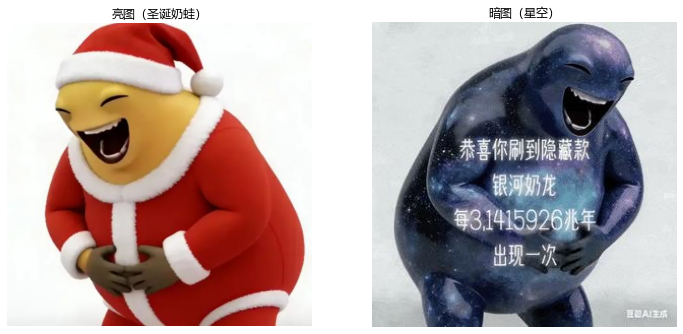

亮图  V 通道均值 =  199.4
暗图  V 通道均值 =  150.1
→ 暗图里阈值要放宽，或者先做亮度增强


In [92]:
# 演示 5：亮图 vs 暗图的差别主要在 V 通道
bright = cv2.imread('res/nl_santa.png')
dark = cv2.imread('res/nl_galaxy.png')

show_img(bright, dark, titles=['亮图（圣诞奶蛙）', '暗图（星空）'])

for name, im in [('亮图', bright), ('暗图', dark)]:
    v_ch = cv2.cvtColor(im, cv2.COLOR_BGR2HSV_FULL)[:, :, 2]
    print(f"{name}  V 通道均值 = {v_ch.mean():6.1f}")

print("→ 暗图里阈值要放宽，或者先做亮度增强")


形状: (498, 500, 3)  ->  (498, 500)


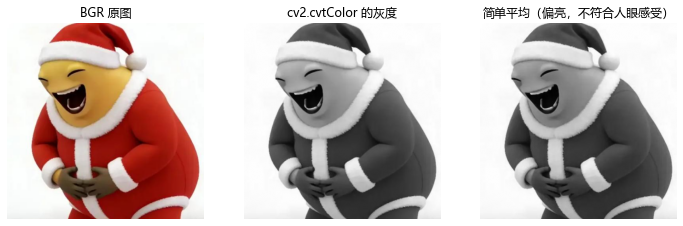

与官方灰度的平均差异：简单平均 2.77，加权公式 0.37  <- 加权公式几乎完全吻合


In [93]:
# 演示 6：灰度图 —— 形状少一个维度，数值也不是简单平均
img = cv2.imread('res/nl_santa.png')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
print("形状:", img.shape, " -> ", gray.shape)

# 灰度不是"三通道取平均"，而是按人眼敏感度加权（0.299R + 0.587G + 0.114B）
b, g, r = cv2.split(img)
avg = img.mean(axis=2).astype(np.uint8)                            # 简单平均
weighted = (0.299 * r + 0.587 * g + 0.114 * b).astype(np.uint8)    # 人眼加权公式

show_img(img, gray, avg,
         titles=['BGR 原图', 'cv2.cvtColor 的灰度', '简单平均（偏亮，不符合人眼感受）'])
print("与官方灰度的平均差异：简单平均 %.2f，加权公式 %.2f  <- 加权公式几乎完全吻合"
      % (np.abs(avg.astype(int) - gray.astype(int)).mean(),
         np.abs(weighted.astype(int) - gray.astype(int)).mean()))


---

### 补充：同一个颜色，在不同空间里长什么样

`cv2.cvtColor` **不改变图像内容**，它只是换个"坐标系"来描述同一个像素。
拿几个纯色举例（每一行都是同一块颜色）：

| 颜色 | 在 BGR 里 | 在 GRAY 里 | 在 HSV(标准) 里 | 在 HSV(FULL) 里 |
| --- | --- | --- | --- | --- |
| 红 | `(0, 0, 255)` | `76` | `(0, 255, 255)` | `(0, 255, 255)` |
| 绿 | `(0, 255, 0)` | `150` | `(60, 255, 255)` | `(85, 255, 255)` |
| 蓝 | `(255, 0, 0)` | `29` | `(120, 255, 255)` | `(171, 255, 255)` |
| 黄 | `(0, 255, 255)` | `226` | `(30, 255, 255)` | `(43, 255, 255)` |
| 浅灰 | `(200, 200, 200)` | `200` | `(0, 0, 200)` | `(0, 0, 200)` |

看懂这张表就懂了 `cvtColor`：

- **"红"这一个颜色，在四个空间里是四组完全不同的数字** —— 但描述的是同一个红
- 灰度只有 **1 个数**（亮度），BGR / HSV 有 **3 个数**，
  所以形状会从 `(H, W, 3)` 变成 `(H, W)` —— 少了一个维度
- 浅灰那行的 S = 0、H = 0：**没有颜色**的时候，色相就没意义了
- 同一个绿，标准 HSV 的 H = 60，FULL 的 H = 85 —— 这就是为什么必须先确认用哪一套

**它不做什么**（这几点最容易误会）：

| ❌ 它不负责 | 说明 |
| --- | --- |
| 不是"增强"或"美化" | 不会让图变好看 |
| 不改变亮度 / 对比度 | 只是换描述方式，像素值本身没被"处理" |
| 不去噪 | 噪声原样保留 |
| 不改变分辨率 | 宽高完全不变 |

> 💡 **小贴士**：判断一个操作是不是 `cvtColor` 该干的活，就问一句 ——
> **"我是想换个角度看同一张图，还是想改变这张图？"**
> 换角度 → `cvtColor`；改变它 → 滤波 / 阈值 / 形态学那些函数。


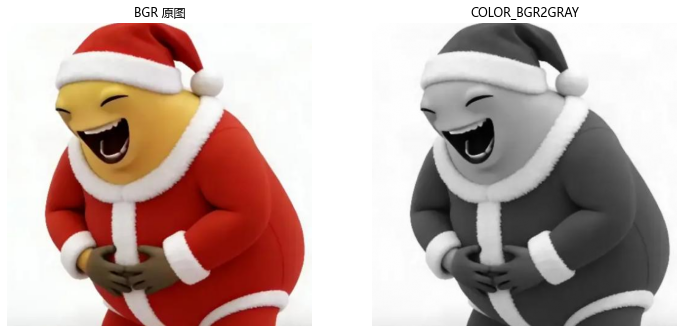

BGR2RGB 等价于 img[:, :, ::-1]: True
H 最大值：标准版 179，FULL 版 255


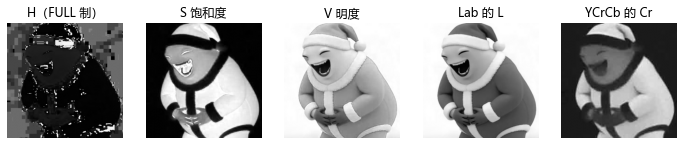

In [94]:
# 演示 7：cv2.cvtColor —— 一个函数，通往所有颜色空间
img = cv2.imread('res/nl_santa.png')          # 原始：BGR

# ① 转灰度（最常用）
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
show_img(img, gray, titles=['BGR 原图', 'COLOR_BGR2GRAY'])

# ② 转 RGB：只是把 R、B 两个通道换个位置，和第 1 章的 img[:, :, ::-1] 完全等价
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
print("BGR2RGB 等价于 img[:, :, ::-1]:", np.array_equal(rgb, img[:, :, ::-1]))

# ③ 转 HSV：标准版和 FULL 版的 H 范围不一样
hsv_std = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hsv_full = cv2.cvtColor(img, cv2.COLOR_BGR2HSV_FULL)
h, s, v = cv2.split(hsv_full)
print("H 最大值：标准版 %d，FULL 版 %d" % (hsv_std[:, :, 0].max(), hsv_full[:, :, 0].max()))

# ④ 其他颜色空间：Lab 的 L 也是亮度，YCrCb 的 Cr 偏肤色
lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
ycc = cv2.cvtColor(img, cv2.COLOR_BGR2YCrCb)
show_img(h, s, v, lab[:, :, 0], ycc[:, :, 1],
         titles=['H（FULL 制）', 'S 饱和度', 'V 明度', 'Lab 的 L', 'YCrCb 的 Cr'])


默认读 (359, 1284, 3)  UNCHANGED 读 (359, 1284, 4)  alpha 值 [255]


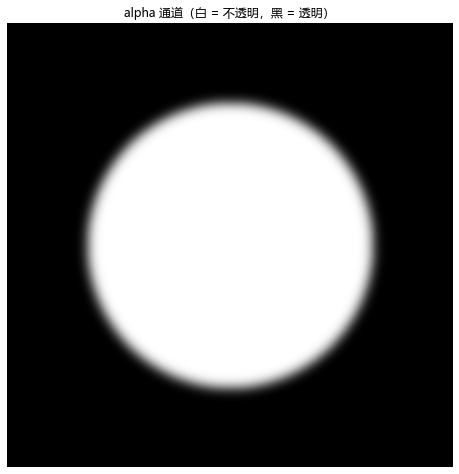

BGRA2BGR (498, 500, 3)  BGRA2GRAY (498, 500)  BGR2BGRA (498, 500, 4)


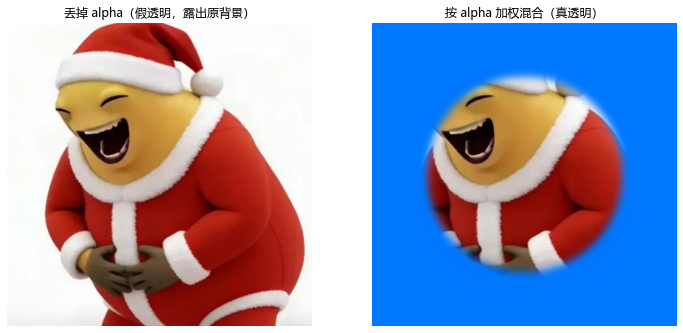

3 通道 + 4 通道做加法: error: (-209:Sizes of input arguments do not match) The operation is n
拆 4 通道图 -> ValueError: too many values to unpack (expected 3)


In [95]:
# 演示 8：第四个通道 alpha（透明度）
# ① 同一个 PNG，两种读法，通道数不一样
rgb3 = cv2.imread('res/rgb.png')                          # 默认：alpha 被丢掉
rgb4 = cv2.imread('res/rgb.png', cv2.IMREAD_UNCHANGED)    # 保留 alpha
# alpha 里的值全是 255（完全不透明），所以两种读法看不出画面差别
print("默认读", rgb3.shape, " UNCHANGED 读", rgb4.shape, " alpha 值", np.unique(rgb4[:, :, 3]))

# ② 自己造一张真正带透明度的图：给 nl_santa 加一个圆形 alpha
fg = cv2.imread('res/nl_santa.png')
h, w = fg.shape[:2]
alpha = np.zeros((h, w), np.float32)
cv2.circle(alpha, (w // 2, h // 2), 160, 1.0, -1)          # 圆内不透明
alpha = cv2.GaussianBlur(alpha, (41, 41), 0)               # 边缘羽化，过渡自然
bgra = np.dstack([fg, (alpha * 255).astype(np.uint8)])     # 拼成 BGRA（4 通道）
show_img(bgra[:, :, 3], titles=['alpha 通道（白 = 不透明，黑 = 透明）'])

# ③ 3 通道的转换码遇到 4 通道图：会把 alpha 直接忽略掉
print("BGRA2BGR", cv2.cvtColor(bgra, cv2.COLOR_BGRA2BGR).shape,
      " BGRA2GRAY", cv2.cvtColor(bgra, cv2.COLOR_BGRA2GRAY).shape,
      " BGR2BGRA", cv2.cvtColor(fg, cv2.COLOR_BGR2BGRA).shape)

# ④ 想要真透明，只能自己按 alpha 加权混合
bg = np.full_like(fg, (255, 120, 0))                       # 换一张纯色背景
comp = (fg * alpha[:, :, None] + bg * (1 - alpha[:, :, None])).astype(np.uint8)
show_img(cv2.cvtColor(bgra, cv2.COLOR_BGRA2BGR), comp,
         titles=['丢掉 alpha（假透明，露出原背景）', '按 alpha 加权混合（真透明）'])

# ⑤ 两个坑：通道数不一致不能直接运算；拆 4 通道图时左边变量个数必须对上
try:
    cv2.add(fg, bgra)
except cv2.error as e:
    print("3 通道 + 4 通道做加法:", str(e)[str(e).find('error:'):][:70].replace('\n', ' '))
try:
    b, g, r = cv2.split(bgra)
except ValueError as e:
    print("拆 4 通道图 -> ValueError:", e)


uint8 uint8 0~255  /  float32 float32 0.00~1.00  —— 同一张图，只是单位从「格」换成了「百分比」


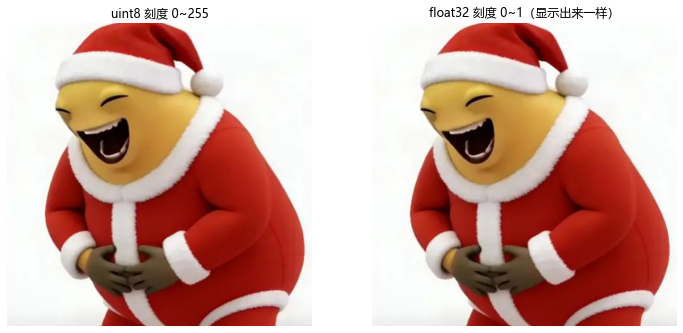

0~1 转回 0~255 后和原图完全一致: True
cvtColor 输入 0~1 -> 0.00~1.00 ；输入 0~255 -> 0~255
float64（Python 的 float） 报错： error: (-2:Unspecified error) in function '__cdecl cv::impl:
int32 报错： error: (-2:Unspecified error) in function '__cdecl cv::impl:
thresh 要配套：0~255 写 127 -> 127.0 ； 0~1 写 0.5 -> 0.5
把 0~1 的 float 图直接 imwrite，读回来均值只有 0.7  <- 要先 (f*255).astype(np.uint8) 再存


In [96]:
# 演示 9：0~1 还是 0~255 —— 两把尺子量同一张图
img = cv2.imread('res/nl_santa.png')
f01 = (img / 255.0).astype(np.float32)     # 换成 0~1 的 float32
f255 = img.astype(np.float32)              # 也可以保持 0~255 的 float32

print("uint8 %s %d~%d  /  float32 %s %.2f~%.2f  —— 同一张图，只是单位从「格」换成了「百分比」"
      % (img.dtype, img.min(), img.max(), f01.dtype, f01.min(), f01.max()))
show_img(img, f01, titles=['uint8 刻度 0~255', 'float32 刻度 0~1（显示出来一样）'])

# 换算公式：来回走一趟应该完全还原
back = (f01 * 255).round().astype(np.uint8)
print("0~1 转回 0~255 后和原图完全一致:", np.array_equal(back, img))

# cvtColor 不做任何刻度换算：输入什么刻度，输出就是什么刻度
g01 = cv2.cvtColor(f01, cv2.COLOR_BGR2GRAY)
g255 = cv2.cvtColor(f255, cv2.COLOR_BGR2GRAY)
print("cvtColor 输入 0~1 -> %.2f~%.2f ；输入 0~255 -> %.0f~%.0f"
      % (g01.min(), g01.max(), g255.min(), g255.max()))

# 坑 ①：cvtColor 只认 uint8 / uint16 / float32，float64 和 int32 直接报错
for name, bad in [('float64（Python 的 float）', img.astype(float)),
                  ('int32', img.astype(np.int32))]:
    try:
        cv2.cvtColor(bad, cv2.COLOR_BGR2GRAY)
    except cv2.error as e:
        msg = str(e)
        print("%s 报错：" % name, msg[msg.find('error:'):][:60].replace('\n', ' '))

# 坑 ②：阈值必须跟着刻度写  坑 ③：imwrite 存 float 会降级，0~1 的图存出来几乎全黑
print("thresh 要配套：0~255 写 127 ->", cv2.threshold(img[:, :, 0], 127, 255, cv2.THRESH_BINARY)[0],
      "； 0~1 写 0.5 ->", round(cv2.threshold(f01[:, :, 0], 0.5, 1.0, cv2.THRESH_BINARY)[0], 2))
cv2.imwrite('out/float_scale_demo.png', f01)
print("把 0~1 的 float 图直接 imwrite，读回来均值只有 %.1f  <- 要先 (f*255).astype(np.uint8) 再存"
      % cv2.imread('out/float_scale_demo.png').mean())


### ✍️ 练习

1. 用 `res/nl_santa.png` 打印几个像素的 BGR 和 HSV_FULL，找出"红帽子"的 H 大致范围。
2. 用演示 3 的方法算出**橙色**和**紫色**的 HSV，对照颜色区间表验证。
3. 对 `res/nl_galaxy.png` 求 H / S / V 三张图，说明暗图为什么难处理。
4. 对比同一张图在 `COLOR_BGR2HSV` 与 `COLOR_BGR2HSV_FULL` 下的 H 最大值，验证 ×1.417 的换算。
5. 把 `res/nl_santa.png` 转成 **Lab** 和 **YCrCb**，各取一个通道看看，猜猜哪个通道最像灰度。
6. 用色环角度表算一下：色相 90° 在 `COLOR_BGR2HSV` 和 `COLOR_BGR2HSV_FULL` 里分别是多少？
7. 把 `res/HSV.png` 分别用**默认方式**和 `cv2.IMREAD_UNCHANGED` 读进来，比较两个 `shape`；
   再打印 alpha 通道的 `min()` / `max()`，解释为什么这两种读法看不到画面差别。
8. 用 `np.linspace` 给 `res/nl_think.png` 造一条**从左到右渐变**的 alpha（左边全透明、右边不透明），
   然后分别用"丢掉 alpha"和"加权混合"把它贴到 `res/nl_hd17.jpg` 上，对比两张结果图。
9. 把 `res/nl_hd01.jpg` 转成 0~1 的 `float32`，提亮（乘 1.5）后：
   ① 直接 `cv2.imwrite` 存一次；② 先 `np.clip(f*255, 0, 255).astype(np.uint8)` 再存一次。
   把两张图都读回来对比，解释差异。
10. **思考题**：`cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)` 和 `cv2.imread(path, 0)` 都能得到灰度图，有什么区别？

> ❓ **自测 1**：只给你一张图，你怎么系统地找出"某个颜色"的 HSV 区间？
> ❓ **自测 2**：拿到同事的代码，怎么用一句话判断他用的图是 0~255 还是 0~1 的刻度？

---

# 第 4 章 掩码与逻辑运算

> 🎯 **学习目标**：搞清楚"掩码"到底是什么，并会用按位运算做"抠图贴图"。

## 讲解要点

### 1. 掩码：一张"要不要"的地图

**掩码（mask）** 是一张和原图**同尺寸**的图。它**不表示颜色**，只表示每个像素**要不要**：

| 掩码的值 | 含义 |
| --- | --- |
| `255`（白） | **要**（保留） |
| `0`（黑） | **不要**（丢弃） |

掩码一般是自己造出来的，取值天然就是 `0 / 255`：

```python
mask = np.zeros(img.shape[:2], np.uint8)     # 全黑 = 全都不要
mask[100:400, 100:400] = 255                 # 中间一块白 = 只要这一块
```

后面第 5 章讲阈值、以及颜色分割时你会看到：
**所有"分割"类操作，返回值都是一张现成的掩码。**

> ⚠️ **别和后面阈值里的黑白混**：第 5 章阈值图里的"白"表示"**亮**"或者"目标"，
> 掩码里的"白"表示"**要**"。同样叫黑白，说的是两张不同的图。

> 💡 **对照素材**：`res/mask_white_text.png`（白底黑字）和 `res/mask_black_text.png`（黑底白字）
> 是一对互为反相的文字掩码 ——
> **黑底白字本身就是一张现成的掩码**，**白底黑字则相当于掩码取反**。
> 演示 1 会现场生成它们，并演示"掩码反了，抠出来的结果正好相反"。

### 2. 按位运算：四个函数 + 一张真值表

| 函数 | 作用 | 常见用法 |
| --- | --- | --- |
| `cv2.bitwise_and(src1, src2[, mask])` | 按位与 | `bitwise_and(img, img, mask=m)` = **按掩码抠图** |
| `cv2.bitwise_or(src1, src2[, mask])` | 按位或 | 合并两个掩码 / 叠加两张图 |
| `cv2.bitwise_not(src)` | 按位取反 | 掩码取反（`mask_inv`） |
| `cv2.bitwise_xor(src1, src2[, mask])` | 按位异或 | 求两张图的差异 |

**掩码里只有 0 / 255 两种值，所以"按位"运算就等于"逻辑"运算**：

| `a` | `b` | `and` | `or` | `xor` | `not a` |
| --- | --- | --- | --- | --- | --- |
| 0 | 0 | 0 | 0 | 0 | 255 |
| 0 | 255 | 0 | 255 | 255 | 255 |
| 255 | 0 | 0 | 255 | 255 | 0 |
| 255 | 255 | 255 | 255 | 0 | 0 |

**记法**：`and` = **交集**（有一个黑就黑）、`or` = **并集**（有一个白就白）、
`xor` = **差异**（两个不一样才白）。

> ⚠️ **三个易错点**
>
> **①「逻辑运算」只是 0/255 下的俗称。** 值不是 0/255 就露馅：
> `cv2.bitwise_and(1, 2)` 按位算 `0001 & 0010 = 0`，可按逻辑理解"两个都非零"该为真。
> **所以掩码老实写 0 / 255。**
>
> **② 掩码不必是 255。** OpenCV 只判断"**是不是 0**"：
> 填 `1`、`128`、`255` 效果完全一样，而且保留的是**原值**（不会被掩码的值"与"掉）。
>
> **③ 尺寸必须和原图一致**，否则报
> `(-215:Assertion failed) ... _mask.sameSize(*psrc1)`。掩码是**单通道**就行，原图是彩色也无所谓。

### 3. 实战：像素级的逻辑操作 —— 给 lena 做一行"反色文字"

手上有两张现成的"标记图"（同一串字的两种反相画法）：

| 文件 | 长什么样 | 它天然就是 |
| --- | --- | --- |
| `res/mark_white.png` | **黑底白字** `SCUT GC` | 一张现成的**掩码**：字 = 255（要），底 = 0（不要） |
| `res/mark_black.png` | **白底黑字** `SCUT GC` | 上面那张的**反相**：字 = 0（不要），底 = 255（要） |

目标：让 lena 上的 `SCUT GC` 这行字变成**底片（反色）**，其它地方一动都不动。

就四步，每步一个按位函数：

| 步骤 | 代码 | 得到什么 |
| --- | --- | --- |
| ① 抠出文字 | `cv2.bitwise_and(img, mark_white)` | 只有笔画处 = lena，其余全黑 |
| ② 文字反色 | `cv2.bitwise_not(①, mask=mark_white 的灰度)` | 笔画处 = `255 - lena`，其余仍是黑 |
| ③ 原图挖字 | `cv2.bitwise_and(img, mark_black)` | 整张 lena，笔画处被挖成黑 |
| ④ 两块相加 | ② + ③ | **文字反色，其余原样** |

> 💡 **为什么 ③ 用 `and` 而不是 `not`？**
> 因为 `mark_black` 里**字是黑的** —— 拿它和原图做 `and`，"字"那块自然就变成 0 了。
> 两张标记图互为反相，正好一张负责"留字"、一张负责"留背景"。

> 💡 **第三个参数是干什么的？** `cv2.bitwise_and(src1, src2, dst)` 的 `dst` 是"结果写到哪"，
> 写上 `result` 就相当于顺手存一份，省一次赋值 —— 不写也行，返回值一样。

> 💡 **一句话本质**：这个套路和第 1 节那句话是同一件事 ——
> **用掩码决定每个像素取哪张图的哪个值**。想通这一点，
> 抠图、贴图、水印、局部反色……全是同一个模子。

### 4. 补充：图像的加法与混合

**加法有两种写法，结果不一样**：

| 写法 | 规则 | 举例（250 + 10） |
| --- | --- | --- |
| `cv2.add(a, b)` | **饱和运算**：超过 255 就截断到 255 | `255` ✅ 推荐 |
| `a + b`（NumPy） | **取模运算**：溢出后回绕 | `4`（256 取模）❌ |

```python
x = np.array([[250, 250]], np.uint8)
y = np.array([[10, 10]], np.uint8)
print(cv2.add(x, y))   # [[255 255]]  —— 饱和
print(x + y)           # [[4 4]]      —— 溢出
```

> ⚠️ **易错点**：图像相加 / 混合请**用 OpenCV 的函数**，不要用 `+`，否则会看到莫名其妙的暗色块。
> 另外：要写成**二维数组** —— OpenCV 会把长度 ≤ 4 的一维数组当成 `Scalar` 处理，那样不会饱和。

**按权重混合**（α 混合，不是简单相加）：

$$dst = \alpha \cdot img1 + \beta \cdot img2 + \gamma$$

```python
dst = cv2.addWeighted(img1, 0.7, img2, 0.3, 0)
```

> ❓ **自测**：`cv2.bitwise_and(img, img, mask=m)` 为什么两个参数都写 `img`？
> （答：两个 `img` 相与不会改变像素值，真正起作用的是 `mask` —— 写法只是个习惯。）


白底黑字 取值: [  0 255]  黑像素占 10.3%
黑底白字 取值: [  0 255]
两者互为反相: True


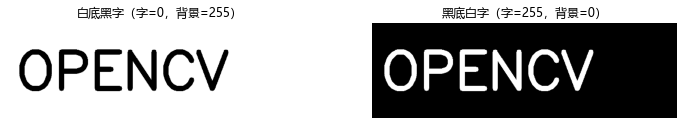


   a    b   AND   OR   XOR   NOT a
[[  0   0   0   0   0 255]
 [  0 255   0 255 255 255]
 [255   0   0 255 255   0]
 [255 255 255 255   0   0]]


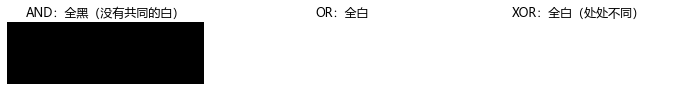

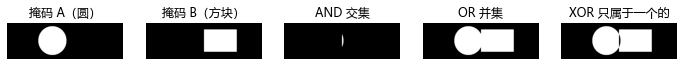

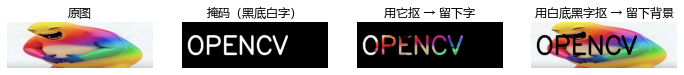

→ 同一张图、同一个函数，掩码反了结果正好相反
   掩码 =   0 -> [[0, 0, 0], [0, 0, 0], [0, 0, 0]]
   掩码 =   1 -> [[10, 20, 30], [40, 50, 60], [70, 80, 90]]
   掩码 = 128 -> [[10, 20, 30], [40, 50, 60], [70, 80, 90]]
   掩码 = 255 -> [[10, 20, 30], [40, 50, 60], [70, 80, 90]]
→ 非零就保留，而且保留的是原值（不会被掩码的值「与」掉）


In [97]:
# 演示 1：掩码与逻辑运算 —— 白底黑字 vs 黑底白字
# ① 现场造两张图（用 LINE_8 不加抗锯齿，保证只有 0 / 255 两种值）
H, W = 200, 640
white_bg = np.full((H, W, 3), 255, np.uint8)                      # 白底
cv2.putText(white_bg, 'OPENCV', (20, 138), cv2.FONT_HERSHEY_SIMPLEX, 3.6,
            (0, 0, 0), 9, cv2.LINE_8)                             # 黑字
black_bg = cv2.bitwise_not(white_bg)                              # 黑底白字 = 直接反相

cv2.imwrite('res/mask_white_text.png', white_bg)
cv2.imwrite('res/mask_black_text.png', black_bg)

print("白底黑字 取值:", np.unique(white_bg),
      " 黑像素占 %.1f%%" % (100 * np.count_nonzero(white_bg == 0) / white_bg.size))
print("黑底白字 取值:", np.unique(black_bg))
print("两者互为反相:", np.array_equal(black_bg, cv2.bitwise_not(white_bg)))
show_img(white_bg, black_bg, titles=['白底黑字（字=0，背景=255）', '黑底白字（字=255，背景=0）'])

# ② 真值表：a、b 的四种组合
a = np.array([[0], [0], [255], [255]], np.uint8)
b = np.array([[0], [255], [0], [255]], np.uint8)
print("\n   a    b   AND   OR   XOR   NOT a")
print(np.hstack([a, b, cv2.bitwise_and(a, b), cv2.bitwise_or(a, b),
                 cv2.bitwise_xor(a, b), cv2.bitwise_not(a)]))

# ③ 两张互补的图做运算：AND 全黑、OR / XOR 全白
show_img(cv2.bitwise_and(white_bg, black_bg),
         cv2.bitwise_or(white_bg, black_bg),
         cv2.bitwise_xor(white_bg, black_bg),
         titles=['AND：全黑（没有共同的白）', 'OR：全白', 'XOR：全白（处处不同）'])

# ④ 更常见的场景：两个"部分重叠"的掩码
mask_a = np.zeros((H, W), np.uint8)
cv2.circle(mask_a, (250, 100), 78, 255, -1)                       # 黑底白圆
mask_b = np.zeros((H, W), np.uint8)
cv2.rectangle(mask_b, (320, 40), (500, 160), 255, -1)             # 黑底白方块
show_img(mask_a, mask_b,
         cv2.bitwise_and(mask_a, mask_b), cv2.bitwise_or(mask_a, mask_b),
         cv2.bitwise_xor(mask_a, mask_b),
         titles=['掩码 A（圆）', '掩码 B（方块）', 'AND 交集', 'OR 并集', 'XOR 只属于一个的'])

# ⑤ 掩码真正的作用：决定每个像素"取不取"
photo = cv2.resize(cv2.imread('res/nl_rainbow.png'), (W, H))
mask = black_bg[:, :, 0].copy()                    # 黑底白字，取一个通道就是掩码
keep_text = cv2.bitwise_and(photo, photo, mask=mask)
keep_bg = cv2.bitwise_and(photo, photo, mask=white_bg[:, :, 0].copy())   # 白底黑字当掩码
show_img(photo, mask, keep_text, keep_bg,
         titles=['原图', '掩码（黑底白字）', '用它抠 → 留下字', '用白底黑字抠 → 留下背景'])
print("→ 同一张图、同一个函数，掩码反了结果正好相反")

# ⑥ 掩码不必是 0/255 —— 只要不是 0 就算「要」
probe = np.array([[[10, 20, 30], [40, 50, 60], [70, 80, 90]]], np.uint8)
for m in (0, 1, 128, 255):
    out = cv2.bitwise_and(probe, probe, mask=np.array([[m, m, m]], np.uint8))
    print("   掩码 = %3d -> %s" % (m, out[0].tolist()))
print("→ 非零就保留，而且保留的是原值（不会被掩码的值「与」掉）")


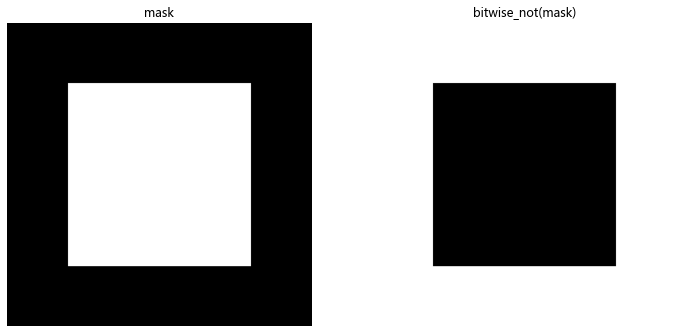

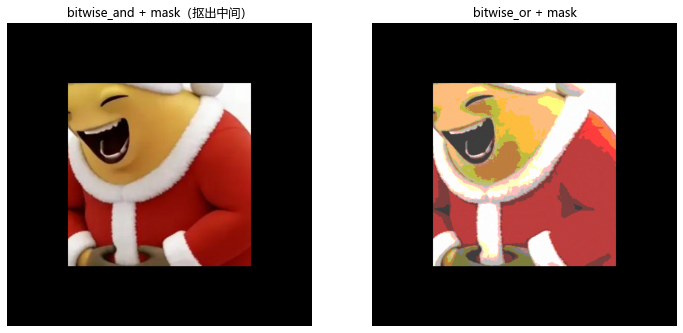

In [98]:
# 演示 2：按位运算
img = cv2.imread('res/nl_santa.png')

mask = np.zeros(img.shape[:2], np.uint8)
mask[100:400, 100:400] = 255          # 中间一块矩形为白

and_img = cv2.bitwise_and(img, img, mask=mask)   # 只保留 mask 为白的地方
not_mask = cv2.bitwise_not(mask)                 # 掩膜取反，黑变白
or_img = cv2.bitwise_or(img, np.full_like(img, 60), mask=mask)

show_img(mask, not_mask, titles=['mask', 'bitwise_not(mask)'])
show_img(and_img, or_img, titles=['bitwise_and + mask（抠出中间）', 'bitwise_or + mask'])


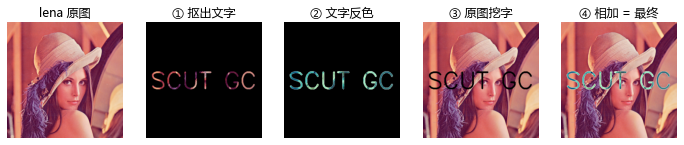

In [99]:
# 演示 3：实战 —— 像素级的逻辑操作：给 lena 做一行"反色文字"
img = cv2.imread('res/lena.png')
mark_white = cv2.imread('res/mark_white.png')      # 黑底白字 —— 本身就是一张掩码
mark_black = cv2.imread('res/mark_black.png')      # 白底黑字 —— 上面那张的反相

# ① 抠出文字：拿"黑底白字"当掩码，只保留笔画处的 lena
#    bitwise_and(src1, src2, dst) 的第三个参数 = 结果写到哪里（顺手存一份）
only_text = np.zeros((512, 512, 3), np.uint8)
cv2.bitwise_and(img, mark_white, only_text)

# ② 把文字做成底片：mask= 表示"只对这些像素取反"（掩码用单通道更省事）
mark_white_gray = cv2.cvtColor(mark_white, cv2.COLOR_BGR2GRAY)
text_inv = only_text.copy()
cv2.bitwise_not(text_inv, text_inv, mask=mark_white_gray)

# ③ 反过来：整张 lena，但把文字笔画挖成黑（因为 mark_black 里字是黑的）
bg_cut = cv2.bitwise_and(img, mark_black)

# ④ ② 和 ③ 正好互补，加起来 = "文字反色、其余原样"（用 cv2.add 饱和，原因见演示 5）
final = cv2.add(bg_cut, text_inv)

show_img(img, only_text, text_inv, bg_cut, final,
         titles=['lena 原图', '① 抠出文字', '② 文字反色', '③ 原图挖字', '④ 相加 = 最终'])


### 补充：换个写法 —— `min` / `max` 也能做同样的事

掩码只有 0 和 255 两个值时，**按位运算和"取大 / 取小"是同一件事**：

| 按位写法 | 等价写法 | 为什么 |
| --- | --- | --- |
| `cv2.bitwise_and(a, m)` | `cv2.min(a, m)` | `and` 遇到 0 就归零 → **取小的那个** |
| `cv2.bitwise_or(a, m)` | `cv2.max(a, m)` | `or` 遇到 255 就变满 → **取大的那个** |

> ⚠️ **但两者并不严格等价**：只有掩码是**干净的 0 / 255**（`cv2.threshold`、
> `cv2.inRange` 出来的）时才成立。演示 3 用的 `mark_white.png` / `mark_black.png`
> 是**抗锯齿**的文字，边缘有两百多种灰度值 —— 那里 `min(img, 130)` 和
> `img & 130` 算出来是不一样的。

> 💡 **怎么选**：掩码干净 → 两种写法随便；**掩码是图标 / 文字 / 羽化过的 →
> 老实写 `bitwise_and`**。而且 `bitwise_and` 一眼就知道在干什么，`min` 容易让队友看不懂。


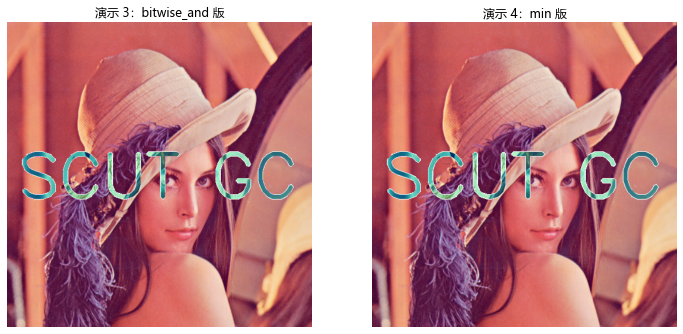

逐像素完全相同吗: False
平均差异: 0.1700  <- 肉眼看不出来，但边缘处确实不一样


In [100]:
# 演示 4：换个写法 —— 用 min / max 代替按位运算，做出和演示 3 一样的效果
result_min = np.zeros((512, 512, 3), np.uint8)
cv2.min(img, mark_white, result_min)                            # ① 等价 bitwise_and：抠出文字
cv2.bitwise_not(result_min, result_min, mask=mark_white_gray)   # ② 文字反色
result_bg = np.zeros((512, 512, 3), np.uint8)
cv2.min(img, mark_black, result_bg)                             # ③ 注意是 min，不是 max！
result_min = cv2.add(result_min, result_bg)                     # ④ 相加

# 和演示 3 的结果并排比一比
show_img(final, result_min, titles=['演示 3：bitwise_and 版', '演示 4：min 版'])

# ⚠️ 看着一样，但不是逐像素相同 —— 标记图是抗锯齿的，边缘处 min 和 & 算出的数不同
print("逐像素完全相同吗:", np.array_equal(final, result_min))
print("平均差异: %.4f  <- 肉眼看不出来，但边缘处确实不一样"
      % np.abs(final.astype(int) - result_min.astype(int)).mean())


cv2.add(x, y) = [[255 255]]   <- 饱和：封顶 255
x + y        = [[4 4]]   <- 溢出：256 取模变 4
（注意要写成二维数组：长度 <= 4 的一维数组会被 OpenCV 当成 Scalar，那样不会饱和）



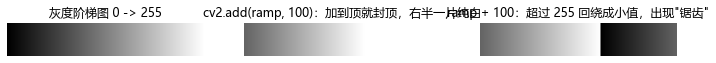

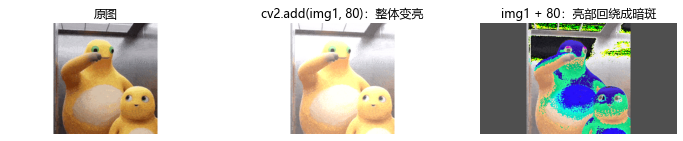

In [101]:
# 演示 5：cv2.add 和 numpy 加法的区别
x = np.array([[250, 250]], np.uint8)
y = np.array([[10, 10]], np.uint8)

print("cv2.add(x, y) =", cv2.add(x, y), "  <- 饱和：封顶 255")
print("x + y        =", x + y, "  <- 溢出：256 取模变 4")
print("（注意要写成二维数组：长度 <= 4 的一维数组会被 OpenCV 当成 Scalar，那样不会饱和）\n")

# ① 用一张"灰度阶梯"图看最直观：灰度从左到右从 0 一路升到 255
ramp = np.tile(np.linspace(0, 255, 600, dtype=np.float32), (100, 1)).astype(np.uint8)
ramp = cv2.cvtColor(ramp, cv2.COLOR_GRAY2BGR)

add_cv = cv2.add(ramp, 100)     # 饱和：加到 255 就停住
add_np = ramp + 100             # 溢出：超过 255 就回绕

show_img(ramp, add_cv, add_np,
         titles=['灰度阶梯图 0 -> 255',
                 'cv2.add(ramp, 100)：加到顶就封顶，右半一片纯白',
                 'ramp + 100：超过 255 回绕成小值，出现"锯齿"'])

# ② 换成真实图像：亮的地方会变成暗斑 / 杂色
img1 = cv2.imread('res/nl_hd13.jpg')
show_img(img1, cv2.add(img1, 80), img1 + 80,
         titles=['原图', 'cv2.add(img1, 80)：整体变亮', 'img1 + 80：亮部回绕成暗斑'])


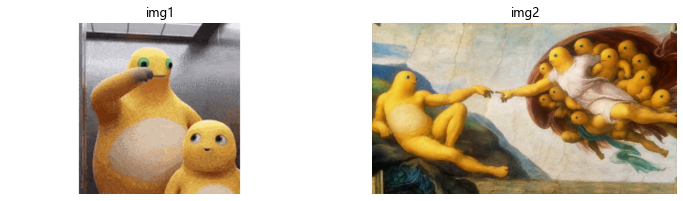

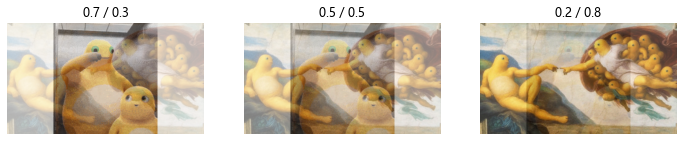

In [102]:
# 演示 6：图像混合 cv2.addWeighted
img1 = cv2.imread('res/nl_hd13.jpg')
img2 = cv2.imread('res/nl_classic2.jpg')

# 两张图尺寸可能不同，先统一
img2 = cv2.resize(img2, (img1.shape[1], img1.shape[0]))

blend73 = cv2.addWeighted(img1, 0.7, img2, 0.3, 0)
blend55 = cv2.addWeighted(img1, 0.5, img2, 0.5, 0)
blend28 = cv2.addWeighted(img1, 0.2, img2, 0.8, 0)

show_img(img1, img2, titles=['img1', 'img2'])
show_img(blend73, blend55, blend28,
         titles=['0.7 / 0.3', '0.5 / 0.5', '0.2 / 0.8'])


### ✍️ 练习

1. 验证 `cv2.add(x, y)` 和 `x + y` 在 `x=200, y=100` 时的差别，并解释原因。
2. 把 `res/nl_hd01.jpg` 和 `res/nl_hd17.jpg` 按 0.5 / 0.5 混合，再按 0.8 / 0.2 混合，比较效果。
3. 用 `cv2.bitwise_not` 把 `res/nl_santa.png` 变成"底片"（反色）。
4. 把演示 3 里的 lena 换成 `res/nl_hd01.jpg`（先 `cv2.resize` 到 512×512），再跑一遍，
   看看 `SCUT GC` 这行字是不是也变成了底片色。
5. 只把演示 3 的 ② 保留、去掉 ③ 和 ④，看看结果会变成什么样？为什么？
6. **思考题**：为什么 `cv2.bitwise_and(img, img, mask=m)` 里要写两遍 `img`？


---

# 第 5 章 二值化与颜色分割

> 🎯 **学习目标**：能用一个阈值或一段 HSV 区间，把目标从背景里"切"出来。

## 讲解要点

### 1. 灰度二值化

把一个**单通道**图像映射到两种取值（通常 0 和 255）：

$$dst(x,y)=\begin{cases}255 & src(x,y) > T\\ 0 & \text{otherwise}\end{cases}$$

```python
thr, binary = cv2.threshold(src, thresh, maxval, type)
# ↑ 返回实际用的阈值（用 OTSU 时会自动算出来）
```

| type | 一句话 |
| --- | --- |
| `THRESH_BINARY` | 亮的变白 |
| `THRESH_BINARY_INV` | 亮的变黑（**白底图抠物体用它**） |
| `THRESH_TRUNC` | 亮的截断到 T |
| `THRESH_TOZERO` | 暗的变全黑 |
| `THRESH_TOZERO_INV` | 亮的变全黑 |

**表背不下来就看图**（横轴输入灰度、纵轴输出灰度、虚线是阈值 T）：

![五种阈值类型的输入-输出曲线](res/threshold.png)

> 💡 **小贴士**：口诀 —— 物体比背景**亮**用 `BINARY`，物体比背景**暗**（白底图）用 `BINARY_INV`。
> 这两个覆盖 95% 的场景，剩下三个知道有这回事就行。

**阈值不知道填多少？**

| 写法 | 适合 |
| --- | --- |
| `cv2.threshold(g, 0, 255, cv2.THRESH_BINARY \| cv2.THRESH_OTSU)` | 直方图**双峰**（背景一堆、目标一堆） |
| `cv2.threshold(g, 0, 255, cv2.THRESH_BINARY \| cv2.THRESH_TRIANGLE)` | 直方图**单峰**、目标很小 |
| `cv2.adaptiveThreshold(...)` | 光照**不均** |

> ⚠️ **易错点**：`THRESH_OTSU` / `THRESH_TRIANGLE` 是**旗标**不是类型，
> 要用**按位或**加在 `type` 上（`thresh` 写 `0` 占位），不能单独用。

**这三种"自动阈值"到底差在哪**（演示 3 会用一张真实照片把它们摆在一起）：

| 方法 | 阈值从哪来 | 治什么病 |
| --- | --- | --- |
| 固定阈值 | 你自己拍一个数 | 光照稳定、目标和背景反差大 |
| **大津法** `+ THRESH_OTSU` | 遍历所有 T，挑**前景和背景分得最开**（类间方差最大）的那个 | 直方图**双峰** |
| **自适应阈值** `cv2.adaptiveThreshold` | **每个像素用自己周围一小块**单独算一个局部阈值 | 光照**不均** |

> ⚠️ **最容易搞错的一点**：**大津法不等于自适应**。
> 它只是"**自动帮你挑一个全局阈值**"—— 图上一半亮一半暗的时候照样救不了，
> 要么亮的那半全白、要么暗的那半全黑。真正能治光照不均的只有 `adaptiveThreshold`。

**`cv2.adaptiveThreshold` 的参数**：

```python
dst = cv2.adaptiveThreshold(src, maxval, method, type, blockSize, C)
```

| 参数 | 含义 |
| --- | --- |
| `maxval` | 满足条件时给的亮值，一般写 255 |
| **`method`** | `ADAPTIVE_THRESH_MEAN_C`：邻域取**算术平均**<br>`ADAPTIVE_THRESH_GAUSSIAN_C`：邻域取**高斯加权平均**（离中心越近权重越大，更抗噪、字边更干净） |
| `type` | **只支持** `THRESH_BINARY` / `THRESH_BINARY_INV`，不能用 TRUNC / TOZERO 那几个 |
| `blockSize` | 每个像素参考的邻域边长，**必须是大于 1 的奇数**（3 / 5 / 7 / 31 …） |
| `C` | 算出来的局部阈值再**减掉** C。C 越大越"苛刻"，越多像素被判成黑 |

判定规则是：**像素 > (局部均值 − C) → 255**。

> 💡 **小贴士**：`blockSize` 大约取"**字笔画宽度的 2~3 倍**"最合适 ——
> 太小会把笔画内部也切得黑白相间，太大就退化成全局阈值（光照不均又救不回来了）。
> 字高十几像素的话，`blockSize=31` 是个好起点。

> 💡 **和上一章区分开**：这里阈值图的"白"表示"**亮**"或者"目标"；
> 第 4 章掩码里的"白"表示"**要**"。概念不同，别串。
> 但好消息是 —— **`threshold` 的输出本身就是一张现成的掩码**，可以直接喂给 `bitwise_and`。

### 2. ⭐ `cv2.inRange`（本章重点）

二值化不止能干灰度，还能干**颜色**：

```python
mask = cv2.inRange(hsv, lower, upper)    # 区间内 -> 255，否则 -> 0
```

`lower` / `upper` 是 `np.array([H, S, V])`。返回值同样是一张现成的掩码。

### 3. 两个必须记住的坑

**坑一：红色必须分两段**（H 跨 0 点）

```python
r_mask = cv2.inRange(hsv, np.array([0, 80, 80]),   np.array([14, 255, 255])) | \
         cv2.inRange(hsv, np.array([243, 80, 80]), np.array([255, 255, 255]))
```

**坑二：mask 一定有小白点噪声** → 用开运算清掉

```python
kernel = np.ones((5, 5), np.uint8)
r_mask = cv2.morphologyEx(r_mask, cv2.MORPH_OPEN, kernel)     # 去小白点
r_mask = cv2.morphologyEx(r_mask, cv2.MORPH_CLOSE, kernel)    # 补小空洞
```

> 💡 **够用就行**：**开运算 = 先腐蚀再膨胀**（抹掉比核小的白点），
> **闭运算 = 先膨胀再腐蚀**（填掉比核小的空洞）。记住这两句 + 会调这两个函数即可，
> 原理和示意图在**下一章（第 6 章 图像形态学变换）**。

> 💡 **小贴士**：调参是有顺序的，别乱试 ——
> **先调 S 下限**（剔掉灰白区域）→ **再调 V 下限**（剔掉过暗/过亮）→ **最后微调 H 宽度**。
> 按这个顺序走，比随机改数字快得多。

### 4. 从掩膜到目标框：`findContours` + `boundingRect`（够用版）

前面拿到的 `mask` 只告诉你「**哪些像素是目标**」，还没告诉你「**目标在哪、多大**」。
要把一片白像素变成「一个框」，标准做法是下面五步：

```python
mask = cv2.inRange(hsv, lower, upper)                     # ① 掩膜
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)     # ② 清掉小白点
contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL,   # ③ 找轮廓
                               cv2.CHAIN_APPROX_SIMPLE)
biggest = max(contours, key=cv2.contourArea)              # ④ 挑面积最大的
x, y, w, h = cv2.boundingRect(biggest)                    # ⑤ 求外接矩形
```

**`cv2.findContours(image, mode, method)`** —— 把连成一片的白像素描成「轮廓」：

| 参数 | 含义 | 常用值 |
| --- | --- | --- |
| `image` | **必须是单通道二值图**（灰度图或掩膜） | 彩色图会直接报错，先 `cvtColor` 或 `inRange` |
| `mode` | 检索哪些轮廓 | **`RETR_EXTERNAL`**：只要最外层（最常用）<br>`RETR_LIST`：所有轮廓，不建层级<br>`RETR_TREE`：建完整层级（父子、内外） |
| `method` | 轮廓点怎么存 | **`CHAIN_APPROX_SIMPLE`**：只留拐点（省内存）<br>`CHAIN_APPROX_NONE`：每个边界像素都留 |

返回值是 **`(contours, hierarchy)` 两个值**（OpenCV 3 以后一直是两个，别照老教程写成三个）：

- `contours`：一个 **list**，每个元素是一条轮廓（本质是 `N×1×2` 的 ndarray，存的是 `[x, y]` 点）；
- `hierarchy`：轮廓之间的父子关系；用不上时写 `_` 接住就行。

**两个把「轮廓」变成「数字」的函数**：

| 函数 | 返回 | 用途 |
| --- | --- | --- |
| `cv2.contourArea(c)` | 轮廓围出的**面积**（浮点数，单位是像素²） | 挑最大的目标、过滤小噪点 |
| `cv2.boundingRect(c)` | **正外接矩形** `(x, y, w, h)` | 画框、算 ROI、喂给 `cv2.rectangle` |

> 💡 **够用就行**：本章只讲「**从掩膜拿到一个框**」这条最常用的路。
> 轮廓的层级（`RETR_TREE` 怎么读）、`cv2.moments` 求质心、`approxPolyDP` 多边形逼近，
> 以及**最小外接旋转矩形 / 最小外接圆 / 凸包**这几种外接形状，
> 都在**选学讲义第 3、4 章**里讲。

> ⚠️ **易错点**：`findContours` 的输入**必须是单通道图**。
> 把 `cv2.imread` 读进来的彩色图直接丢进去，会报一个 `(-215:Assertion failed)` 开头、
> 信息里带 `findContours` 的错误。先 `cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)`，
> 或者直接用 `inRange` 出来的掩膜。

> ⚠️ **易错点**：掩膜全黑时 `contours` 是**空列表**，
> 这时 `max(contours, key=...)` 会抛 `ValueError: max() arg is an empty sequence`。
> **养成先判断 `if contours:` 再用的习惯。**

> 💡 **小贴士**：面积特别小的轮廓基本都是噪点，习惯上先过滤一遍：
> `contours = [c for c in contours if cv2.contourArea(c) > 100]`。

这里用到的阈值 T = 127.0


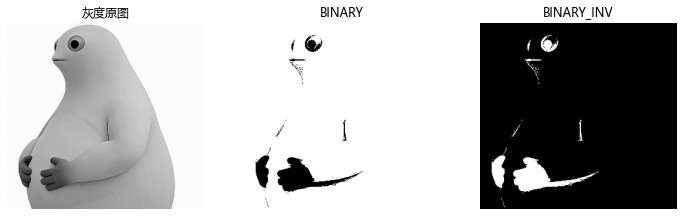

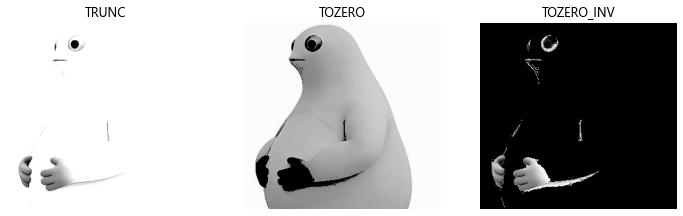

In [103]:
# 演示 1：五种 threshold 类型
img = cv2.imread('res/nl_side.png')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

thr, bin_1 = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)
thr, bin_2 = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY_INV)
thr, bin_3 = cv2.threshold(gray, 127, 255, cv2.THRESH_TRUNC)
thr, bin_4 = cv2.threshold(gray, 127, 255, cv2.THRESH_TOZERO)
thr, bin_5 = cv2.threshold(gray, 127, 255, cv2.THRESH_TOZERO_INV)

print("这里用到的阈值 T =", thr)
show_img(gray, bin_1, bin_2, titles=['灰度原图', 'BINARY', 'BINARY_INV'])
show_img(bin_3, bin_4, bin_5, titles=['TRUNC', 'TOZERO', 'TOZERO_INV'])


固定阈值 T = 235   物体像素占比 43.0%


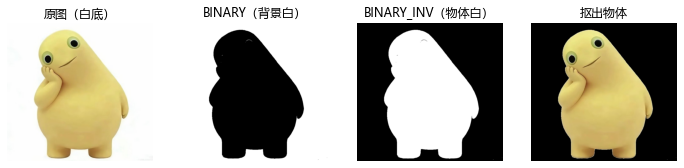

In [104]:
# 演示 2：白底图怎么把物体抠出来（BINARY_INV 的典型用法）
img = cv2.imread('res/nl_think.png')          # 白背景 + 黄色奶蛙
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# ⚠️ 阈值要落在"物体"和"背景"两堆灰度之间的空档里
#    这张图：奶蛙挤在 180~210，白底挤在 250~254，中间 215~244 几乎没有像素
#    取 200 太靠左 —— 奶蛙偏浅的脸和肚子会被判成背景，抠出来中间是黑的、带洞
T = 235                                        # 取在空档中间
thr, mask_dir = cv2.threshold(gray, T, 255, cv2.THRESH_BINARY)      # 背景变白
thr, mask_inv = cv2.threshold(gray, T, 255, cv2.THRESH_BINARY_INV)  # 物体变白
print("固定阈值 T =", T, "  物体像素占比 %.1f%%" % (100 * np.count_nonzero(mask_inv) / mask_inv.size))

cut = img.copy()
cut[mask_inv == 0] = 0                        # 用掩膜把背景涂黑

show_img(img, mask_dir, mask_inv, cut,
         titles=['原图（白底）', 'BINARY（背景白）', 'BINARY_INV（物体白）', '抠出物体'])


上半张平均亮度 175，下半张 60 —— 差了 115 个灰度级
大津法自动求得的全局阈值 T = 131
  固定 127     白像素占比  40.3%
  大津法        白像素占比  38.9%
  自适应·均值     白像素占比  91.5%
  自适应·高斯     白像素占比  92.2%


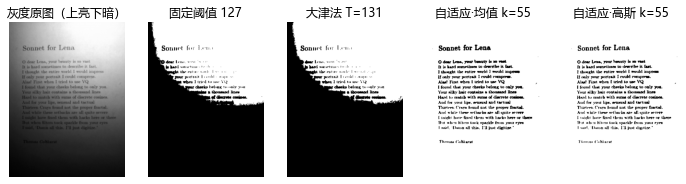

→ 固定阈值和大津法都丢了下面半页的字，只有自适应能整页认出来


In [105]:
# 演示 3：光照不均怎么办 —— 固定阈值 vs 大津法 vs 自适应
# 用的是一张"上亮下暗"的纸面照片，这是文档扫描、赛场补光的典型情况
img = cv2.imread('res/lena_word.png')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 先量一下光照差多少：上半张和下半张的平均亮度
h = gray.shape[0]
print("上半张平均亮度 %.0f，下半张 %.0f —— 差了 %.0f 个灰度级"
      % (gray[:h // 2].mean(), gray[h // 2:].mean(),
         gray[:h // 2].mean() - gray[h // 2:].mean()))

bin_fixed = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)[1]                  # ① 固定阈值
T_otsu, bin_otsu = cv2.threshold(gray, 0, 255,
                                 cv2.THRESH_BINARY + cv2.THRESH_OTSU)            # ② 大津法（自动求全局阈值）
bin_mean = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
                                 cv2.THRESH_BINARY, 55, 10)                      # ③ 自适应·邻域算术平均
bin_gauss = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                  cv2.THRESH_BINARY, 55, 10)                     # ④ 自适应·邻域高斯加权

print("大津法自动求得的全局阈值 T = %.0f" % T_otsu)
for name, m in [('固定 127', bin_fixed), ('大津法', bin_otsu),
                ('自适应·均值', bin_mean), ('自适应·高斯', bin_gauss)]:
    print("  %-10s 白像素占比 %5.1f%%" % (name, 100 * np.count_nonzero(m) / m.size))

show_img(gray, bin_fixed, bin_otsu, bin_mean, bin_gauss,
         titles=['灰度原图（上亮下暗）', '固定阈值 127', '大津法 T=%.0f' % T_otsu,
                 '自适应·均值 k=55', '自适应·高斯 k=55'])
print("→ 固定阈值和大津法都丢了下面半页的字，只有自适应能整页认出来")


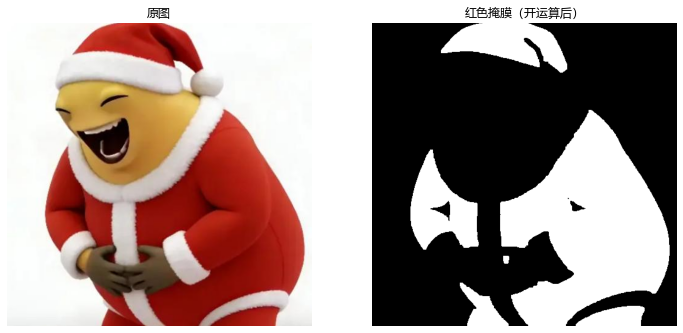

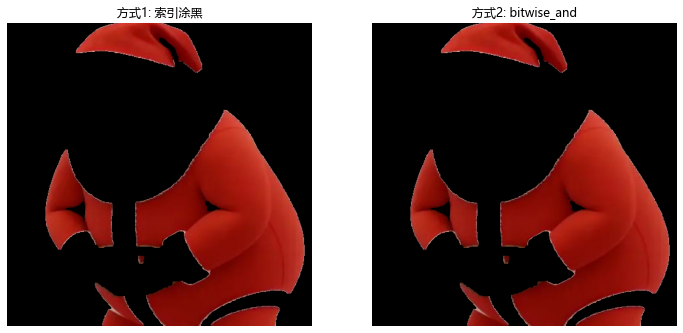

红色像素占比: 32.3%


In [106]:
# 演示 4：颜色分割 —— 把红帽子抠出来（两段合并 + 开运算）
tsubaki = cv2.imread('res/nl_santa.png')
tsubaki_hsv = cv2.cvtColor(tsubaki, cv2.COLOR_BGR2HSV_FULL)

# 红色 H 跨 0 点，必须分两段
red_l1, red_u1 = np.array([0, 80, 80]),   np.array([14, 255, 255])
red_l2, red_u2 = np.array([243, 80, 80]), np.array([255, 255, 255])
r_mask = cv2.inRange(tsubaki_hsv, red_l1, red_u1) | cv2.inRange(tsubaki_hsv, red_l2, red_u2)

# 掩膜一定有小白点噪声，用开运算清掉
r_mask = cv2.morphologyEx(r_mask, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))

# 取结果的两种方式
hana = tsubaki.copy()
hana[r_mask == 0] = 0
hat = cv2.bitwise_and(tsubaki, tsubaki, mask=r_mask)

show_img(tsubaki, r_mask, titles=['原图', '红色掩膜（开运算后）'])
show_img(hana, hat, titles=['方式1: 索引涂黑', '方式2: bitwise_and'])

print("红色像素占比: %.1f%%" % (np.count_nonzero(r_mask) / r_mask.size * 100))


S 下限= 20  蓝色像素数 54636
S 下限= 60  蓝色像素数 53653
S 下限=120  蓝色像素数 51756
S 下限=200  蓝色像素数 4912


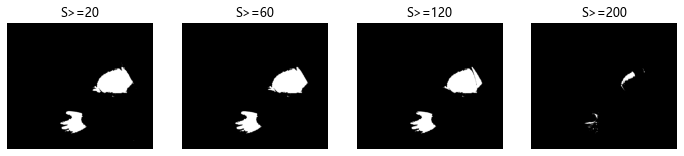

结论：S 下限越高，只保留越'纯'的蓝色，灰蓝/浅蓝会被剔掉


In [107]:
# 演示 5：调参实验 —— S 下限怎么影响结果
rainbow = cv2.imread('res/nl_rainbow.png')
rainbow_hsv = cv2.cvtColor(rainbow, cv2.COLOR_BGR2HSV_FULL)

blue_u = np.array([160, 255, 255])

masks = []
for s_min in [20, 60, 120, 200]:
    m = cv2.inRange(rainbow_hsv, np.array([116, s_min, 40]), blue_u)
    masks.append(m)
    print(f"S 下限={s_min:3d}  蓝色像素数 {np.count_nonzero(m)}")

show_img(*masks, titles=['S>=20', 'S>=60', 'S>=120', 'S>=200'])
print("结论：S 下限越高，只保留越'纯'的蓝色，灰蓝/浅蓝会被剔掉")


In [ ]:
# 演示 6：从掩膜到目标框 —— findContours + boundingRect
img = cv2.imread('res/nl_hd01.jpg')
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV_FULL)

# ① 掩膜：卡出奶蛙皮肤的 H 区间（它的肤色 H≈27，白底背景 S≈0）
mask = cv2.inRange(hsv, np.array([15, 60, 120]), np.array([40, 255, 255]))
print('去噪前 白色像素占比: %.2f%%' % (100 * np.count_nonzero(mask) / mask.size))

# ② 开运算清掉小白点
kernel = np.ones((7, 7), np.uint8)
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
print('去噪后 白色像素占比: %.2f%%' % (100 * np.count_nonzero(mask) / mask.size))

# ③ 找轮廓（输入必须是单通道二值图）
contours, hierarchy = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
print('找到轮廓数:', len(contours))
print('hierarchy 形状:', None if hierarchy is None else hierarchy.shape)

if contours:                                     # ⚠️ 掩膜全黑时 contours 是空列表
    areas = sorted((cv2.contourArea(c) for c in contours), reverse=True)
    print('各轮廓面积（前 5 大）:', [int(a) for a in areas[:5]])

    # ④ 挑面积最大的那条轮廓，求它的正外接矩形
    biggest = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(biggest)
    print(f'最大目标的 boundingRect (x, y, w, h) = ({x}, {y}, {w}, {h})')

    # ⑤ 画框（第 10 章的用法，这里先提前见一面）
    vis = img.copy()
    cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 4)
    cv2.putText(vis, f'nailong  area={int(cv2.contourArea(biggest))}',
                (x, max(y - 16, 30)), cv2.FONT_HERSHEY_SIMPLEX, 1.4, (0, 255, 0), 4)
    show_img(img, vis, titles=['原图', '掩膜 -> 轮廓 -> 外接矩形'])
else:
    print('掩膜是空的，没有找到任何轮廓')

去噪前 白色像素占比: 27.29%
去噪后 白色像素占比: 27.09%
找到轮廓数: 5
hierarchy 形状: (1, 5, 4)
各轮廓面积（前 5 大）: [582202, 345, 238, 77, 42]
最大目标的 boundingRect (x, y, w, h) = (537, 13, 882, 1067)


### ✍️ 练习

**练习 1（基础）**：对 `res/nl_side.png` 用五种 `threshold` 各做一次，说明哪种能把奶蛙和背景分开。

**练习 2（重点）**：把 `res/nl_rainbow.png` 里的**纯蓝色区域**分割出来。要求：

1. 先转到 HSV_FULL，看 H 通道分布
2. 用 `inRange` 卡区间（蓝：116~160）
3. 开运算清理
4. **把结果和原图并排显示**

**练习 3（挑战）**：同时分割出红色和黄色，显示在一张图上。
提示：`mask = r_mask | y_mask`，再用 `cv2.bitwise_and` 取结果。

> ❓ **自测**：`inRange` 得到的 mask 有什么用？说出至少三种取结果的方式。

**练习 4（定位）**：用演示 6 的流程，把 `res/nl_hd13.jpg` 里**面积最大**的奶蛙框出来，
打印它的 `boundingRect`，把框画在原图上并存入 `out/`。
（提示：换一张图，HSV 区间可能要微调 —— 先用第 3 章的采样法看一下它的肤色 H 是多少。）

---

# 第 6 章 图像形态学变换

> 🎯 **学习目标**：会造结构元素，会做腐蚀 / 膨胀 / 开运算 / 闭运算，
> 并且知道每种操作"什么时候用"。
> 💡 **小贴士**：真做工程时你会发现，二值图从来不是"刚好干净"的 ——
> 形态学就是那把扫把：**去小白点、补小空洞、断细连接、平滑边界**。

### 1. 结构元素：形态学的"刷子"

做形态学之前要先回答一个问题：**用多大的刷子、什么形状的刷子？**
这就是 `cv2.getStructuringElement(shape, ksize)`：

| `shape` | 形状 | 像什么 |
| --- | --- | --- |
| `cv2.MORPH_RECT` | 矩形 | 方头刷子（实心） |
| `cv2.MORPH_CROSS` | 十字 | 细刷子（只有上下左右） |
| `cv2.MORPH_ELLIPSE` | 椭圆 / 圆 | 圆头刷子（边缘平滑） |

`ksize` 的格式是 `(宽, 高)` —— **先宽后高**，和 NumPy 的 `shape` 正好反过来。

> ⚠️ **易错点**：`ksize=(5, 3)` 不是 5×5，是 **5 列 × 3 行**的扁核。
> 用扁核做腐蚀，会"横向收得少、纵向收得多"。
> 想要正方形的核就写 `(5, 5)`。

> 💡 **小贴士**：核越大，效果越猛。一般从 `(3, 3)` 起步，
> 用 `iterations` 参数控制"刷几遍"，比直接上大核更细腻。

In [108]:
# 三种结构元素长什么样：直接把数组打出来看
elem_rect = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 3))
elem_cross = cv2.getStructuringElement(cv2.MORPH_CROSS, (5, 5))
elem_ellipse = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 5))

print("MORPH_RECT (5,3):\n", elem_rect)
print("\nMORPH_CROSS (5,5):\n", elem_cross)
print("\nMORPH_ELLIPSE (9,5):\n", elem_ellipse)

for name, k in [('RECT', elem_rect), ('CROSS', elem_cross), ('ELLIPSE', elem_ellipse)]:
    print(f"{name:8s} shape={k.shape}（高, 宽）  非零元素 {np.count_nonzero(k)} 个")

MORPH_RECT (5,3):
 [[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]

MORPH_CROSS (5,5):
 [[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]

MORPH_ELLIPSE (9,5):
 [[0 0 0 0 1 0 0 0 0]
 [0 1 1 1 1 1 1 1 0]
 [1 1 1 1 1 1 1 1 1]
 [0 1 1 1 1 1 1 1 0]
 [0 0 0 0 1 0 0 0 0]]
RECT     shape=(3, 5)（高, 宽）  非零元素 15 个
CROSS    shape=(5, 5)（高, 宽）  非零元素 9 个
ELLIPSE  shape=(5, 9)（高, 宽）  非零元素 25 个


### 2. 腐蚀与膨胀

两者的做法完全一样，只是"取极值的方向"相反：

1. 给定结构元素（先把它旋转 180°）；
2. 把结构元素的**中心**对准原图里的每一个像素；
3. 只看结构元素非零位置覆盖到的那些像素，**取最小值 / 最大值**写回中心像素。

| 操作 | 取 | 效果 |
| --- | --- | --- |
| **腐蚀** `cv2.erode` | **最小值** | 前景**收缩**，去小白点，但主体会变瘦 |
| **膨胀** `cv2.dilate` | **最大值** | 前景**扩张**，补小空洞，但噪声也会变大 |

![腐蚀示意](res/erode.jpg)

**腐蚀可以把细小的噪声区域去掉，但会让主要区域面积缩小、形状发生改变。**

![膨胀示意](res/dilate.png)

**膨胀可以扩充每个区域的面积、填充较小的空洞，但也会让噪声区域变大。**

> ⚠️ **易错点**：腐蚀和膨胀**都不可逆**。腐蚀 3 次再膨胀 3 次，
> 拿不回原来的图（细小的突起已经被彻底抹掉了）。这就是为什么会有"开/闭运算"。

logo 二值化后，前景占比 22.6%


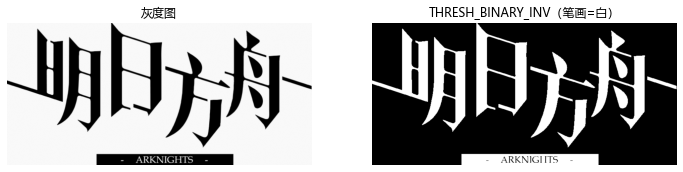

用的核:
 [[0 1 0]
 [1 1 1]
 [0 1 0]]
腐蚀 iterations=1: 前景占比  20.2%
腐蚀 iterations=3: 前景占比  15.6%
腐蚀 iterations=7: 前景占比   8.8%


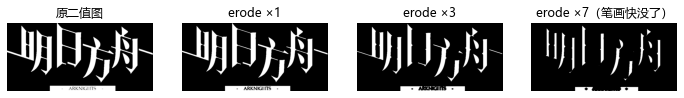

膨胀 iterations=1: 前景占比  25.0%
膨胀 iterations=3: 前景占比  29.5%
膨胀 iterations=7: 前景占比  38.0%


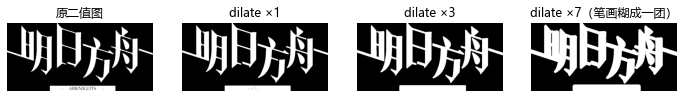

In [109]:
# 准备一张最适合看形态学的图：黑底 + 白色笔画
img_logo = cv2.imread('res/logo.png', cv2.IMREAD_GRAYSCALE)
# 反二值化：让笔画变白（前景=255），背景变黑
_, binary_logo = cv2.threshold(img_logo, 160, 255, cv2.THRESH_BINARY_INV)
print("logo 二值化后，前景占比 %.1f%%" % (100 * np.count_nonzero(binary_logo) / binary_logo.size))
show_img(img_logo, binary_logo, titles=['灰度图', 'THRESH_BINARY_INV（笔画=白）'])

kernel = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))
print("用的核:\n", kernel)

# 腐蚀：次数越大，笔画越细
eroded_1 = cv2.erode(binary_logo, kernel, iterations=1)
eroded_3 = cv2.erode(binary_logo, kernel, iterations=3)
eroded_7 = cv2.erode(binary_logo, kernel, iterations=7)
for it, e in [(1, eroded_1), (3, eroded_3), (7, eroded_7)]:
    print(f"腐蚀 iterations={it}: 前景占比 {100 * np.count_nonzero(e) / e.size:5.1f}%")
show_img(binary_logo, eroded_1, eroded_3, eroded_7,
         titles=['原二值图', 'erode ×1', 'erode ×3', 'erode ×7（笔画快没了）'])

# 膨胀：次数越大，笔画越粗，小洞被填上
dilated_1 = cv2.dilate(binary_logo, kernel, iterations=1)
dilated_3 = cv2.dilate(binary_logo, kernel, iterations=3)
dilated_7 = cv2.dilate(binary_logo, kernel, iterations=7)
for it, d in [(1, dilated_1), (3, dilated_3), (7, dilated_7)]:
    print(f"膨胀 iterations={it}: 前景占比 {100 * np.count_nonzero(d) / d.size:5.1f}%")
show_img(binary_logo, dilated_1, dilated_3, dilated_7,
         titles=['原二值图', 'dilate ×1', 'dilate ×3', 'dilate ×7（笔画糊成一团）'])

### 3. 开运算与闭运算

腐蚀和膨胀都会"改变形状大小"，那怎么才能**只去噪、不改形状**？
把两者结合起来用 —— 这就是开运算和闭运算：

| 运算 | 顺序 | 干什么 |
| --- | --- | --- |
| **开运算** `MORPH_OPEN` | 先腐蚀 → 再膨胀 | 去掉**小白点**、断开细小的连接、平滑边界 |
| **闭运算** `MORPH_CLOSE` | 先膨胀 → 再腐蚀 | 填掉**小空洞**、连接邻近区域、平滑轮廓 |

![开运算示意](res/open.png)

![闭运算示意](res/close.png)

因为"腐蚀掉的"和"膨胀长回来的"尺寸对不上，所以开运算能抹掉比核小的亮斑（它们长不回来），
但主体大块区域基本保持原样 —— 这就是"只去噪、不改形状"。

> ⚠️ **易错点**：**开运算和闭运算的顺序不能反**。
> `MORPH_OPEN` 是"先腐蚀后膨胀"，`MORPH_CLOSE` 是"先膨胀后腐蚀"。
> 反了就是另一个操作（而且效果完全不同）。

> 💡 **小贴士**：这两个词只是记忆问题，记不住就回到那句：
> **开 = 先瘦再胖（把小的抹掉）**，**闭 = 先胖再瘦（把小的填上）**。

原图       前景占比 22.6%
开运算     前景占比 22.5%  <- 略减（小的被抹掉）
闭运算     前景占比 22.9%  <- 略增（小的被填上）


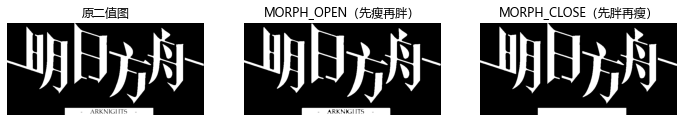


MORPH_GRADIENT 前景占比 4.8%  <- 细而均匀的轮廓线


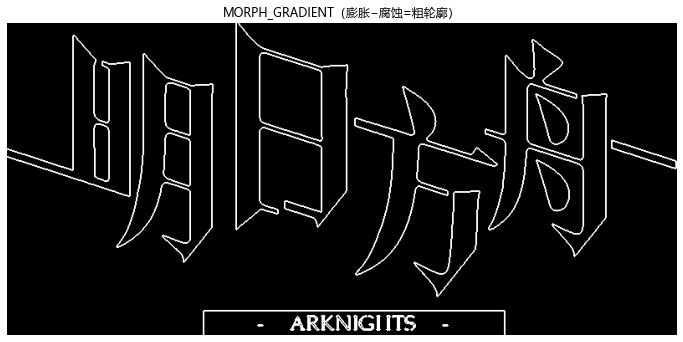

In [110]:
# 开运算：去小白点、断开细连接
img_open = cv2.morphologyEx(binary_logo, cv2.MORPH_OPEN, kernel, iterations=2)
# 闭运算：补小空洞、连接邻近区域
img_close = cv2.morphologyEx(binary_logo, cv2.MORPH_CLOSE, kernel, iterations=2)

print("原图       前景占比 %.1f%%" % (100 * np.count_nonzero(binary_logo) / binary_logo.size))
print("开运算     前景占比 %.1f%%  <- 略减（小的被抹掉）" % (100 * np.count_nonzero(img_open) / img_open.size))
print("闭运算     前景占比 %.1f%%  <- 略增（小的被填上）" % (100 * np.count_nonzero(img_close) / img_close.size))

show_img(binary_logo, img_open, img_close,
         titles=['原二值图', 'MORPH_OPEN（先瘦再胖）', 'MORPH_CLOSE（先胖再瘦）'])

# 形态学梯度：膨胀 − 腐蚀 = 把"边缘一圈"抠出来，也是常见用法
img_grad = cv2.morphologyEx(binary_logo, cv2.MORPH_GRADIENT, kernel, iterations=1)
print("\nMORPH_GRADIENT 前景占比 %.1f%%  <- 细而均匀的轮廓线" % (100 * np.count_nonzero(img_grad) / img_grad.size))
show_img(img_grad, titles=['MORPH_GRADIENT（膨胀−腐蚀=粗轮廓）'])

### ✍️ 练习

1. 把 `kernel` 换成 `MORPH_ELLIPSE (5, 5)` 和 `MORPH_RECT (5, 5)`，重跑腐蚀和膨胀，
   观察笔画粗细变化的方向有什么不同（提示：注意斜笔画）。
2. 对 `res/nl_think.png` 的二值图先做一次 `MORPH_OPEN`，再做一次 `MORPH_CLOSE`，
   和"只做一次"对比，说明这两步分别在解决什么问题。
3. 用 `cv2.MORPH_GRADIENT` 对 `nl_santa.png` 的二值图求轮廓，再和 `cv2.Canny` 的结果对比，
   说说两者的区别。
4. 用 `MORPH_OPEN` + `MORPH_CLOSE` 处理 `res/nl_galaxy.png`（星空暗图）的掩膜，
   看看能不能把零星噪点清掉而不损坏主体。
5. **思考题**：如果掩膜上有一个 **20×20 像素**的黑洞，用 `(5, 5)` 的核做闭运算能不能补上？
   需要多大的核？（提示：闭运算能填的洞，尺寸必须小于核）

---

# 第 7 章 图像卷积

> **卷积是滤波和边缘检测的共同底层。** 理解了它，后面全是套公式。

### 1. 什么是卷积

拿一个小矩阵（**卷积核 / kernel**）在图像上滑动，
每个位置都做一次**加权求和**，结果写到中心像素上：

$$dst(x,y)=\sum_{i=-a}^{a}\sum_{j=-b}^{b} K(i,j)\cdot src(x+i,\ y+j)$$

`cv2.filter2D(src, ddepth, kernel)`

### 一个具体的例子

假设核是 3×3 的锐化核，图像某处 3×3 邻域是：

```text
图像邻域          核             计算
 10  10  10     0  -1   0     0*10 + (-1)*10 + 0*10
 10  50  10    -1   5  -1  +  (-1)*10 + 5*50 + (-1)*10
 10  10  10     0  -1   0  +  0*10 + (-1)*10 + 0*10
                              = -40 + 250 - 40 = 170
```

中心像素原本是 50，**被"增强"成了 170** —— 中心与周围的差异被放大了。

**再换个角度：核在图上滑，每滑一格就做一次加权求和**（这就是"卷积"这个名字的全部含义）：

![2D 卷积动画](res/2D_Convolution_Animation.gif)

> 💡 **小贴士**：后面所有的滤波 —— 均值、高斯、Sobel、Laplacian ——
> **唯一的区别就是"核里的数字不一样"**。
> 所以第 1 节这句话值得反复念：**核设计好了，效果自然对**。

### 2. 核的三条直觉

| 观察 | 结论 |
| --- | --- |
| 核的**所有元素之和 = 1** | 整体亮度不变（如均值核、模糊核） |
| 核的**元素之和 = 0** | 得到"差异图"，平坦区域响应为 0（**边缘核**） |
| 核的**中心为正、周围为负** | 增强中心、抑制周围（**锐化**） |

### 3. ⚠️ 最大的坑：`ddepth` 与负值截断

`cv2.filter2D(src, -1, kernel)` 里 `-1` 表示"输出与输入类型相同"。
输入是 `uint8`，那么：

- 计算得到的**负数会被截断为 0**
- 于是边缘核的结果**几乎全黑**

**正确姿势**：

```python
out = cv2.filter2D(gray, cv2.CV_32F, kernel)   # 用浮点保留负值
out = cv2.convertScaleAbs(out)                 # 取绝对值并转回 uint8
```

### 4. 边界怎么处理：`borderType`

卷积核滑到图像边缘时会"越界"，OpenCV 用 `borderType` 决定怎么补：

| borderType | 补法 | 示意（一维） |
| --- | --- | --- |
| `BORDER_CONSTANT` | 补常数（默认 0） | `000\|abcdef\|000` |
| `BORDER_REPLICATE` | 复制边缘像素 | `aaa\|abcdef\|fff` |
| `BORDER_REFLECT` | 镜像（含边缘） | `fedcba\|abcdef\|fedcba` |
| `BORDER_REFLECT_101` | 镜像（不含边缘，**默认**） | `gfedcb\|abcdef\|gfedcb` |
| `BORDER_WRAP` | 环绕 | `cdefgh\|abcdef\|abcdef` |

> 核越大，边界影响越明显。做定量分析时留意图像四周的若干像素是不可信的。


核的和：均值 1.000 | 锐化 1.0 | 拉普拉斯 0.0


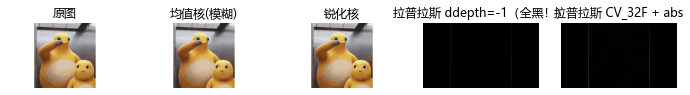

In [111]:
img = cv2.imread('res/nl_hd13.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

kernel_mean = np.ones((9, 9), np.float32) / 81                                  # 均值
kernel_sharpen = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], np.float32)     # 锐化
kernel_edge = np.array([[0, -1, 0], [-1, 4, -1], [0, -1, 0]], np.float32)        # 拉普拉斯

mean_img = cv2.filter2D(img, -1, kernel_mean)
sharpen_img = cv2.filter2D(img, -1, kernel_sharpen)

# 边缘核：必须用 32F，否则负值被截断成全黑
edge_wrong = cv2.filter2D(gray, -1, kernel_edge)
edge_right = cv2.convertScaleAbs(cv2.filter2D(gray, cv2.CV_32F, kernel_edge))

print("核的和：均值 %.3f | 锐化 %.1f | 拉普拉斯 %.1f" %
      (kernel_mean.sum(), kernel_sharpen.sum(), kernel_edge.sum()))

show_img(img, mean_img, sharpen_img, edge_wrong, edge_right,
         titles=["原图", "均值核(模糊)", "锐化核", "拉普拉斯 ddepth=-1（全黑！）", "拉普拉斯 CV_32F + abs"])


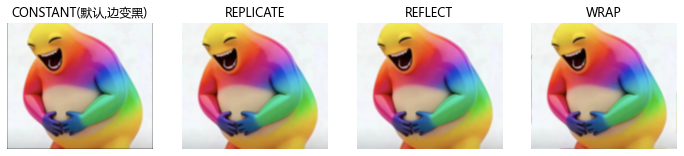

核越大，边界处理方式的影响越明显


In [112]:
# 边界填充方式对比：放大看四周
img = cv2.imread('res/nl_rainbow.png')
k = np.ones((15, 15), np.float32) / 225

b_const = cv2.filter2D(img, -1, k, borderType=cv2.BORDER_CONSTANT)
b_repl = cv2.filter2D(img, -1, k, borderType=cv2.BORDER_REPLICATE)
b_refl = cv2.filter2D(img, -1, k, borderType=cv2.BORDER_REFLECT)
b_wrap = cv2.filter2D(img, -1, k, borderType=cv2.BORDER_WRAP)

show_img(b_const, b_repl, b_refl, b_wrap,
         titles=["CONSTANT(默认,边变黑)", "REPLICATE", "REFLECT", "WRAP"])
print("核越大，边界处理方式的影响越明显")


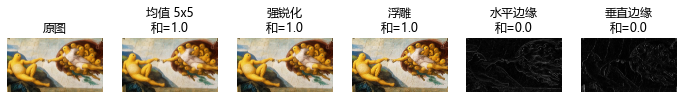

In [113]:
# 自己设计核：从"浮雕"到"纯水平边缘"
img = cv2.imread('res/nl_classic2.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

kernels = {
    "均值 5x5":     np.ones((5, 5), np.float32) / 25,
    "强锐化":       np.array([[-1, -1, -1], [-1, 9, -1], [-1, -1, -1]], np.float32),
    "浮雕":         np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]], np.float32),
    "水平边缘":     np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], np.float32),
    "垂直边缘":     np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32),
}

outs, titles = [], []
for name, kk in kernels.items():
    if abs(kk.sum()) < 1e-6:                       # 和为 0 -> 边缘核
        out = cv2.convertScaleAbs(cv2.filter2D(gray, cv2.CV_32F, kk))
    else:
        out = cv2.filter2D(img, -1, kk)
    outs.append(out); titles.append(f"{name}\n和={kk.sum():.1f}")

show_img(img, *outs, titles=["原图"] + titles)


### ✍️ 练习

1. 用 `BORDER_CONSTANT / REPLICATE / REFLECT` 对同一张图做 **31×31** 均值滤波，
   放大观察四边的差异，解释为什么"大核 + 错误边界"会让边缘出现明显色带。
2. 设计一个核，只保留**对角线方向**的边缘，并验证效果。
3. 验证"核和为 0 必须用 CV_32F"：把 `ddepth` 换成 `-1` 与 `cv2.CV_32F` 各跑一次，比较结果。
4. **思考题**：为什么 `BORDER_REFLECT_101` 被设为默认？（提示：考虑 `BORDER_REFLECT` 在边缘处
   会重复一个像素，对某些算子有影响）


---

# 第 8 章 图像滤波与去噪

> 🎯 **学习目标**：知道四种滤波各治什么病，并且能给图像选对滤波。

## 讲解要点

### 1. 为什么要滤波

真实图像一定有噪声：亮点、黑点、杂色、传感器热噪声、压缩伪影……
不滤波直接做阈值，结果全是噪点。

**但先把"滤波"的本质说清楚：滤波就是一次卷积** ——
一个小矩阵（**核 / kernel**）在图像上滑动，每滑一格就和它盖住的那块像素做一次加权求和：

![2D 卷积动画](res/2D_Convolution_Animation.gif)

（动图里默认的"核"换成**均值**就是 `cv2.blur`，换成**高斯权重**就是 `cv2.GaussianBlur` ——
本章所有滤波，本质上都只是**换了一个核**而已。卷积的完整推导在**第 7 章**。）

### 2. 四种常用滤波

| 方法 | 函数 | 规则 | 边缘 | 速度 |
| --- | --- | --- | --- | --- |
| 均值 | `cv2.blur(img, (k,k))` | 邻域**平均**：用周围像素平均值替换当前像素 | 糊 | 快 |
| 高斯 | `cv2.GaussianBlur(img, (k,k), sigma)` | 邻域**高斯加权**：离中心越近权重越大 | 较糊 | 快 |
| 中值 | `cv2.medianBlur(img, k)` | 邻域**中位数** | 好 | 中 |
| 双边 | `cv2.bilateralFilter(img, d, sc, ss)` | 距离 + 颜色相似度 | **最好** | 慢 |

> ⚠️ **k 必须是正奇数**：3, 5, 7…（核要有唯一中心）

### 3. 高斯滤波：为什么比均值好

均值滤波**一视同仁**，边缘也被一起平均掉了，细节丢失。
高斯滤波让**离中心越近权重越大**，核里元素由高斯分布（钟形曲线）的概率密度算出来：

$$G(x,y)=\frac{1}{2\pi\sigma^2}e^{-\frac{x^2+y^2}{2\sigma^2}}$$

```python
img_gauss = cv2.GaussianBlur(img, (11, 11), 1)   # sigmaX 越大越模糊
```

核长这样：一维核 → 二维核（**外积**）

```python
kernel_gauss = cv2.getGaussianKernel(5, 1)
matrix_kernel = kernel_gauss.dot(kernel_gauss.T)    # OpenCV 内部的做法：可分离卷积
```

### 4. 双边滤波：去噪同时保边

高斯只看**空间距离**，跨过边缘也会把两边混在一起。
双边再加一项**颜色相似度**权重：只有和中心像素颜色接近的邻居才会被平均 ——
于是"**磨皮但轮廓仍然锐利**"，处理后的图像看起来像水彩画。代价是计算量大、慢。

| 参数 | 作用 |
| --- | --- |
| `d` | 邻域直径 |
| `sigmaColor` | **颜色容差**（先调这个：30 保边效果好，100+ 开始明显水彩化） |
| `sigmaSpace` | 空间影响范围 |

### 5. 噪声类型 → 选哪个滤波

| 噪声 | 表现 | 首选 |
| --- | --- | --- |
| 高斯噪声 | 整体颗粒感 | 高斯滤波 |
| **椒盐噪声** | **孤立**的黑点 / 白点 | **中值滤波** |
| 斑点噪声 | 乘性斑点（超声 / 雷达） | 双边 |

> 💡 **小贴士**：为什么中值专治椒盐？**算一遍就懂了** ——
> 3×3 邻域里 1 个白点 255、其余 8 个都是 100。
> 均值 → `(255+800)/9 ≈ 117`，被拉偏；中值 → 排序后第 5 个还是 **100**，完全不受影响。
> 这个例子算完，一辈子记得住。

> ❓ **自测**：做阈值分割之前，为什么建议先滤波？

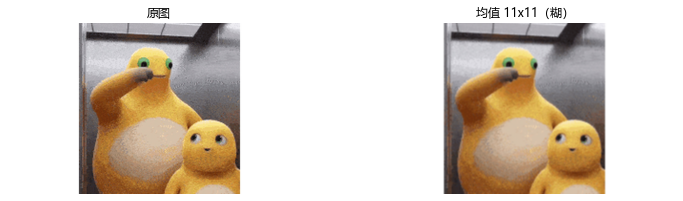

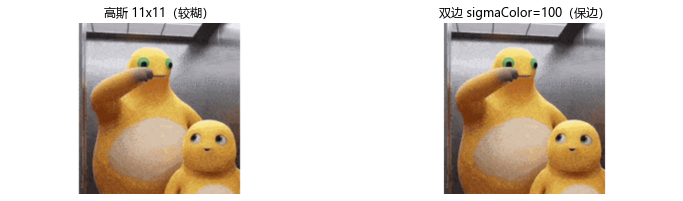

观察：均值和高斯把细节全糊了；双边平滑的同时轮廓还在


In [114]:
# 演示 1：均值 / 高斯 / 双边 的效果对比
img = cv2.imread('res/nl_hd13.jpg')

img_mean = cv2.blur(img, (11, 11))
img_gauss = cv2.GaussianBlur(img, (11, 11), 0)
img_bi = cv2.bilateralFilter(img, 9, 100, 75)

show_img(img, img_mean, titles=['原图', '均值 11x11（糊）'])
show_img(img_gauss, img_bi, titles=['高斯 11x11（较糊）', '双边 sigmaColor=100（保边）'])
print("观察：均值和高斯把细节全糊了；双边平滑的同时轮廓还在")


一维高斯核 (k=5, sigma=1):
[0.0545 0.2442 0.4026 0.2442 0.0545]

二维高斯核 (5x5):
[[0.003  0.0133 0.0219 0.0133 0.003 ]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.0219 0.0983 0.1621 0.0983 0.0219]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.003  0.0133 0.0219 0.0133 0.003 ]]

权重之和 = 1.000000  <- 归一化，保证整体亮度不变


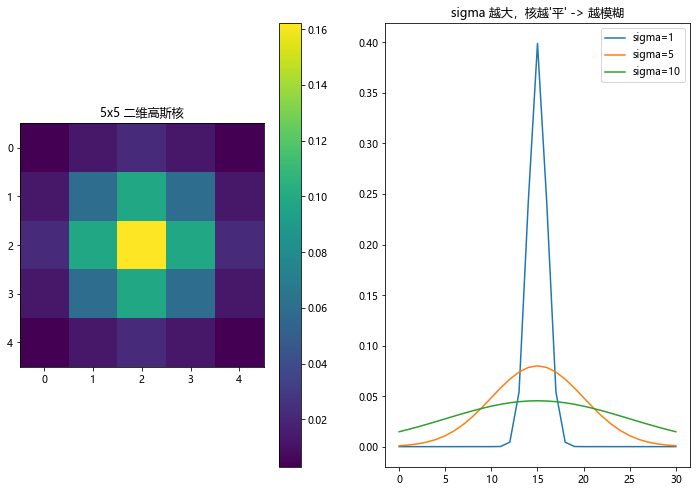

In [115]:
# 演示 2：高斯核长什么样 + sigma 的影响
kernel_gauss = cv2.getGaussianKernel(5, sigma=1)
print("一维高斯核 (k=5, sigma=1):")
print(kernel_gauss.ravel().round(4))

# 二维高斯核 = 一维核的外积（OpenCV 内部就是这么做的）
matrix_kernel = kernel_gauss.dot(kernel_gauss.T)
print("\n二维高斯核 (5x5):")
print(matrix_kernel.round(4))
print("\n权重之和 = %.6f  <- 归一化，保证整体亮度不变" % matrix_kernel.sum())

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(matrix_kernel, cmap='viridis'); plt.title('5x5 二维高斯核'); plt.colorbar()
plt.subplot(1, 2, 2)
for sigma in [1, 5, 10]:
    plt.plot(cv2.getGaussianKernel(31, sigma).ravel(), label=f'sigma={sigma}')
plt.title("sigma 越大，核越'平' -> 越模糊"); plt.legend()
plt.show()


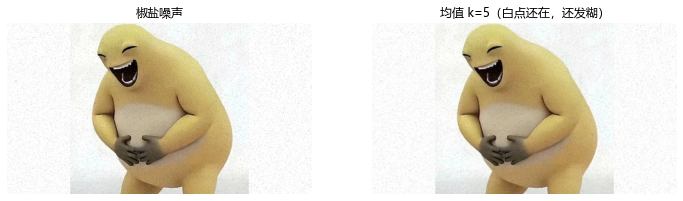

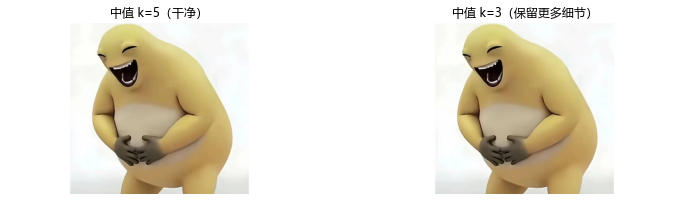

结论：椒盐噪声 -> 中值滤波，几乎完全清除


In [116]:
# 演示 3：椒盐噪声 —— 中值滤波的主场
img = cv2.imread('res/nl_hd01.jpg')

np.random.seed(2024)
noisy = img.copy()
n = int(0.015 * img.shape[0] * img.shape[1])
for val in (0, 255):
    ys = np.random.randint(0, img.shape[0], n)
    xs = np.random.randint(0, img.shape[1], n)
    noisy[ys, xs] = val

show_img(noisy, cv2.blur(noisy, (5, 5)), titles=['椒盐噪声', '均值 k=5（白点还在，还发糊）'])
show_img(cv2.medianBlur(noisy, 5), cv2.medianBlur(noisy, 3),
         titles=['中值 k=5（干净）', '中值 k=3（保留更多细节）'])
print("结论：椒盐噪声 -> 中值滤波，几乎完全清除")


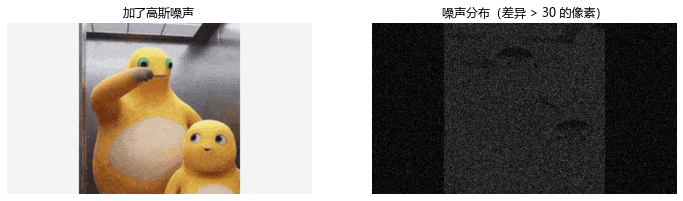

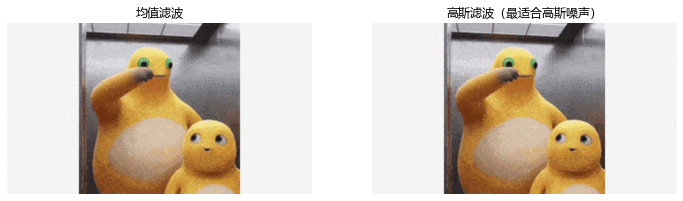

In [117]:
# 演示 4：高斯噪声 + 噪声区域可视化
img = cv2.imread('res/nl_hd13.jpg').astype(np.float32)

# 加高斯噪声
np.random.seed(42)
noise = np.random.normal(0, 25, img.shape).astype(np.float32)
noisy = np.clip(img + noise, 0, 255).astype(np.uint8)


def noise_binary(original, noisy_img, thresh=30):
    """把"和原图差异较大"的像素标成白色，直观看出噪声都在哪。"""
    diff = cv2.absdiff(original, noisy_img)
    gray = cv2.cvtColor(diff, cv2.COLOR_BGR2GRAY)
    _, binary = cv2.threshold(gray, thresh, 255, cv2.THRESH_BINARY)
    return binary


show_img(noisy, noise_binary(img.astype(np.uint8), noisy),
         titles=['加了高斯噪声', '噪声分布（差异 > 30 的像素）'])

# 三种滤波对高斯噪声的效果
show_img(cv2.blur(noisy, (5, 5)), cv2.GaussianBlur(noisy, (5, 5), 0),
         titles=['均值滤波', '高斯滤波（最适合高斯噪声）'])


### ✍️ 练习

1. 对 `res/nl_hd17.jpg` 加 3% 椒盐噪声，比较均值 / 高斯 / 中值：哪个最干净？
2. 固定 `sigma=2`，比较 `ksize = 5 / 11 / 21`，回答：`ksize` 和 `sigma` 各控制什么？
3. 对 `res/nl_classic1.jpg` 做双边滤波，`sigmaColor` 取 30 / 100 / 250，观察水彩画效果的出现。
4. 用 `noise_binary` 看看"中值滤波后"和"原图"还有多少差异。

> ❓ **自测**：拿到一张图，你怎么决定该用哪个滤波？（提示：先判断噪声类型）


---

# 第 9 章 几何变换

> 🎯 **学习目标**：会缩放、平移、旋转、仿射、透视五种变换，知道各自要几个点。

## 讲解要点

### 总览

| 变换 | 矩阵 | 函数 | 需要几个对应点 |
| --- | --- | --- | --- |
| 缩放 | — | `cv2.resize` | — |
| 平移 | 2×3 | `cv2.warpAffine` | — |
| 旋转 | 2×3 | `cv2.getRotationMatrix2D` + `warpAffine` | 中心 + 角度 |
| 仿射 | 2×3 | `cv2.getAffineTransform` + `warpAffine` | **3 组** |
| 透视 | 3×3 | `cv2.getPerspectiveTransform` + `cv2.warpPerspective` | **4 组** |

### 1. 缩放 `cv2.resize`

```python
cv2.resize(src, dsize[, fx[, fy[, interpolation]]])
```

- `dsize`：目标尺寸 **(宽, 高)**；
- 也可以给比例 `fx` / `fy`（此时 `dsize` 传 `None`）；
- `interpolation` 插值方法：

| 插值方法 | 说明 | 适用 |
| --- | --- | --- |
| `cv2.INTER_NEAREST` | 最近邻（最快） | 追求速度 |
| `cv2.INTER_LINEAR`（默认） | 双线性 | 放大 |
| `cv2.INTER_CUBIC` | 双三次（较慢） | 放大更平滑 |
| `cv2.INTER_AREA` | 区域重采样 | **缩小**（推荐） |

### 2. 平移

$$M = \begin{bmatrix} 1 & 0 & t_x \\ 0 & 1 & t_y \end{bmatrix}$$

```python
M = np.float32([[1, 0, 60], [0, 1, 40]])        # 右移 60，下移 40
dst = cv2.warpAffine(img, M, (w, h))
```

> 注意：平移后空出来的地方是**黑色**。

### 3. 旋转

```python
M = cv2.getRotationMatrix2D(center, angle, scale)   # angle 逆时针为正，单位度
dst = cv2.warpAffine(img, M, (w, h))
```

### 4. 仿射变换

仿射变换保持"**平行线仍然平行**"。要确定它，只需要原图 **3 个点**及其在输出图中的位置：

```python
M = cv2.getAffineTransform(pts1, pts2)      # 由 3 组对应点解出 2x3 矩阵
dst = cv2.warpAffine(img, M, (w, h))
```

> 平移和旋转都是仿射变换的特例。

### 5. 透视变换

透视变换**不要求平行线保持平行**，所以能做出"斜着看"的立体效果。
它需要一个 **3×3** 矩阵，由原图 **4 个点**和目标图的 4 个对应点确定：

```python
M = cv2.getPerspectiveTransform(pts1, pts2)
dst = cv2.warpPerspective(img, M, (w, h))
```

> 💡 **小贴士**：透视变换最经典的用途是**文档扫描矫正** ——
> 把拍歪的纸张"拉正"成矩形。
> 💡 这里只讲了"怎么调用"。**完整实战**（怎么量点、怎么算输出尺寸、> 怎么裁黑边）在下面的**第 6 节**，那里有全套代码。

> ❓ **自测**：仿射变换和透视变换，分别需要几组对应点？为什么？


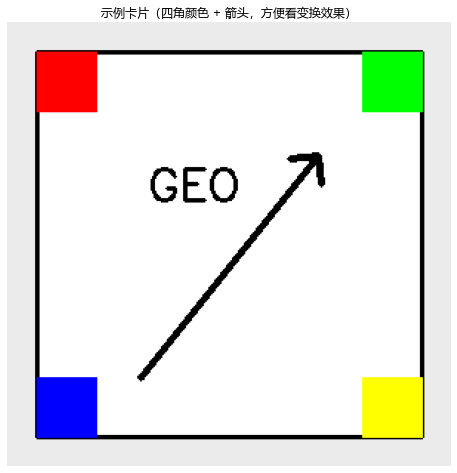

In [118]:
# 造一张带方向标记的卡片图，方便观察旋转 / 透视的效果
card = np.full((300, 300, 3), 235, np.uint8)                    # 浅灰底
cv2.rectangle(card, (20, 20), (280, 280), (255, 255, 255), -1)  # 白卡
cv2.rectangle(card, (20, 20), (280, 280), (0, 0, 0), 2)         # 黑边
cv2.rectangle(card, (20, 20), (60, 60), (0, 0, 255), -1)        # 红 左上
cv2.rectangle(card, (240, 20), (280, 60), (0, 255, 0), -1)      # 绿 右上
cv2.rectangle(card, (20, 240), (60, 280), (255, 0, 0), -1)      # 蓝 左下
cv2.rectangle(card, (240, 240), (280, 280), (0, 255, 255), -1)  # 黄 右下
cv2.arrowedLine(card, (90, 240), (210, 90), (0, 0, 0), 4)       # 箭头指明方向
cv2.putText(card, 'GEO', (95, 120), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 0), 2)
cv2.imwrite('out/card.png', card)

show_img(card, titles=['示例卡片（四角颜色 + 箭头，方便看变换效果）'])


原图尺寸 (宽, 高): (300, 300)


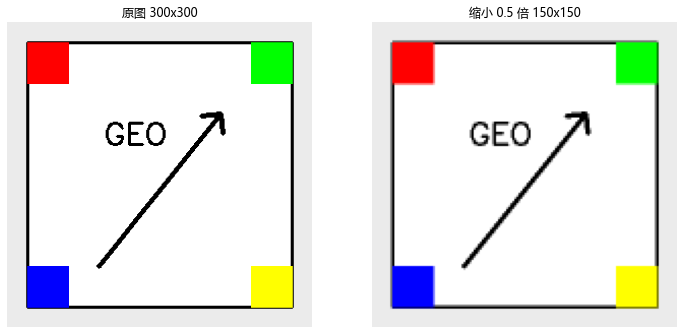

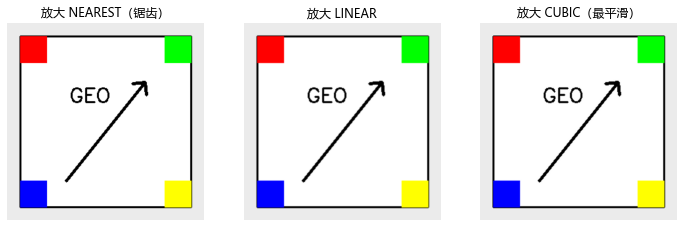

In [119]:
# 演示 1：缩放 —— 插值方法对比
card = cv2.imread('out/card.png')
print("原图尺寸 (宽, 高):", (card.shape[1], card.shape[0]))

small = cv2.resize(card, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)   # 缩小推荐 INTER_AREA

big_nearest = cv2.resize(card, None, fx=2, fy=2, interpolation=cv2.INTER_NEAREST)
big_linear = cv2.resize(card, None, fx=2, fy=2, interpolation=cv2.INTER_LINEAR)
big_cubic = cv2.resize(card, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)

show_img(card, small, titles=['原图 %dx%d' % (card.shape[1], card.shape[0]),
                              '缩小 0.5 倍 %dx%d' % (small.shape[1], small.shape[0])])
show_img(big_nearest, big_linear, big_cubic,
         titles=['放大 NEAREST（锯齿）', '放大 LINEAR', '放大 CUBIC（最平滑）'])


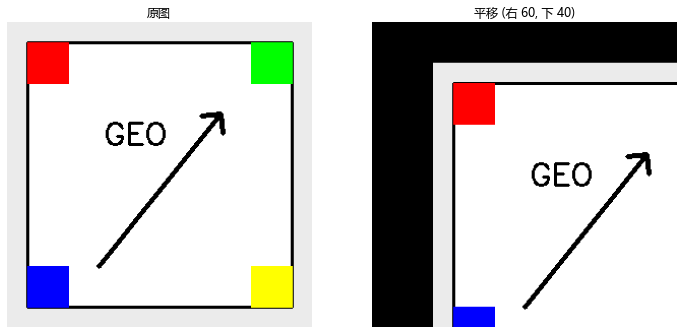

In [120]:
# 演示 2：平移
card = cv2.imread('out/card.png')
h, w = card.shape[:2]

M = np.float32([[1, 0, 60], [0, 1, 40]])      # 右移 60，下移 40
translated = cv2.warpAffine(card, M, (w, h))

show_img(card, translated, titles=['原图', '平移 (右 60, 下 40)'])


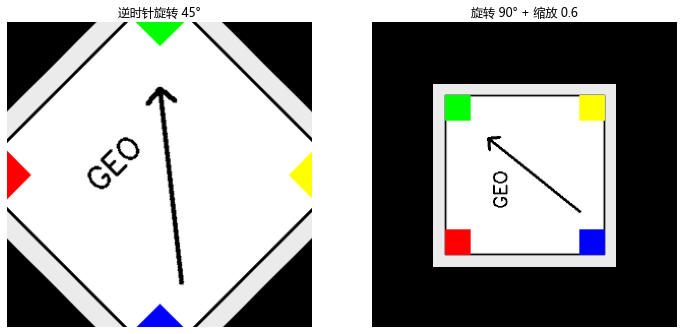

In [121]:
# 演示 3：旋转
card = cv2.imread('out/card.png')
h, w = card.shape[:2]
center = (w // 2, h // 2)

# 绕中心逆时针 45°
M45 = cv2.getRotationMatrix2D(center, 45, 1.0)
rot45 = cv2.warpAffine(card, M45, (w, h))

# 绕中心旋转 90° 并缩小到 0.6 倍
M90 = cv2.getRotationMatrix2D(center, 90, 0.6)
rot90 = cv2.warpAffine(card, M90, (w, h))

show_img(rot45, rot90, titles=['逆时针旋转 45°', '旋转 90° + 缩放 0.6'])


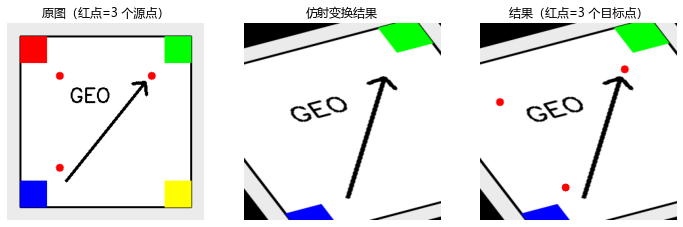

In [122]:
# 演示 4：仿射变换 —— 3 个点
card = cv2.imread('out/card.png')
h, w = card.shape[:2]

pts1 = np.float32([[80, 80], [220, 80], [80, 220]])      # 原图上的 3 个点
pts2 = np.float32([[30, 120], [220, 70], [130, 250]])    # 它们在输出图上的位置

M = cv2.getAffineTransform(pts1, pts2)
affine = cv2.warpAffine(card, M, (w, h))

# 把 3 个点标出来，方便观察
vis1, vis2 = card.copy(), affine.copy()
for p in pts1.astype(int):
    cv2.circle(vis1, tuple(p), 6, (0, 0, 255), -1)
for p in pts2.astype(int):
    cv2.circle(vis2, tuple(p), 6, (0, 0, 255), -1)

show_img(vis1, affine, vis2,
         titles=['原图（红点=3 个源点）', '仿射变换结果', '结果（红点=3 个目标点）'])


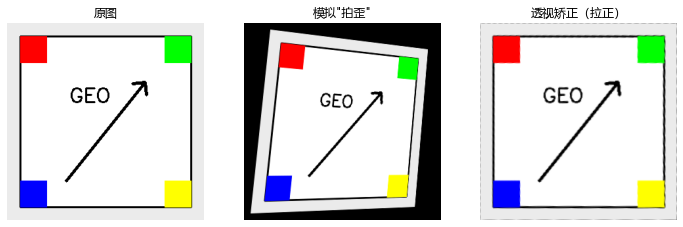

In [123]:
# 演示 5：透视变换 —— 文档矫正（4 个点）
card = cv2.imread('out/card.png')
size = 300

# 原图的 4 个角
pts1 = np.float32([[0, 0], [300, 0], [0, 300], [300, 300]])
# 目标图的 4 个角（拉正成正方形）
pts2 = np.float32([[0, 0], [size, 0], [0, size], [size, size]])

# 先把卡片"拍歪"，模拟一张斜着拍的照片
skew_pts = np.float32([[40, 10], [280, 40], [10, 290], [260, 280]])
M_skew = cv2.getPerspectiveTransform(pts1, skew_pts)
skewed = cv2.warpPerspective(card, M_skew, (size, size))

# 再把它矫正回来
M_fix = cv2.getPerspectiveTransform(skew_pts, pts2)
fixed = cv2.warpPerspective(skewed, M_fix, (size, size))

show_img(card, skewed, fixed, titles=['原图', '模拟"拍歪"', '透视矫正（拉正）'])


---

### 6. 透视变换实战：把斜着拍的"拉正"

> 🎯 **学习目标**：会用 `cv2.getPerspectiveTransform` + `cv2.warpPerspective`
> 把斜着拍的东西"拉正"，并知道四个点该怎么给。
> 💡 **小贴士**：**文档扫描矫正**、**车道线鸟瞰图**都用它。
> 而它的前置步骤——自动找到那四个角——靠的是**轮廓（第 5 章）+ `approxPolyDP`（选学第 3 章）**。

### 6.1 什么是透视变换

**透视变换（Perspective Transformation）就是把一个四边形区域映射成另一个四边形区域。**

想象你站在一条笔直的铁路旁：两条平行的铁轨在远处看起来会汇聚到一点，这就是"透视"效果。
透视变换的作用就是**反过来**——把倾斜的、有透视感的物体"拉直"，
就像从正上方垂直观察它一样。

### 6.2 原理：找一个 3×3 的矩阵

透视变换的核心是求出一个 **3×3 的变换矩阵 $M$**，
它描述源图里的点 $(x, y)$ 怎么映射到目标图的 $(x', y')$。

要确定这个矩阵，至少需要 **4 对点**：

| 名称 | 含义 |
| --- | --- |
| **源坐标点 `src`** | 原图里你要变换的那个四边形的 4 个顶点 |
| **目标坐标点 `dst`** | 你希望这 4 个顶点被映射到的位置，通常是一个**标准矩形** |

给了这 4 对点，OpenCV 就能算出唯一的矩阵 $M$。

> ⚠️ **易错点**：透视变换需要 **4 组**点，仿射变换（`cv2.getAffineTransform`）只要 **3 组**。
> 因为仿射只能表达"平移 + 旋转 + 缩放 + 斜切"，**不能表达"近大远小"**；
> 透视变换多了一维（齐次坐标下的除法），才能把平行的线变成不平行，
> 所以需要多一个点来锁定这个自由度。

### 6.3 应用场景

| 场景 | 怎么做 |
| --- | --- |
| **文档扫描** | 把倾斜拍的名片 / 文档校正成标准矩形 |
| **车道线检测** | 把车载摄像头拍的梯形道路区域转成鸟瞰图，车道线变平行，便于分析 |
| **图像校正** | 纠正因相机角度造成的失真 |
| **机器人视觉** | 把斜装的相机拍到的地面"拉"成俯视图，方便做坐标标定 |

### 6.4 两个关键函数

**① `cv2.getPerspectiveTransform(src, dst)` —— 算矩阵**

| 参数 | 要求 |
| --- | --- |
| `src` | 源图里 4 个点，形状 `(4, 2)`，**`dtype` 必须是 `np.float32`** |
| `dst` | 目标图里对应的 4 个点，同样 `(4, 2)` 的 `np.float32` |
| 返回 | `3×3` 的透视变换矩阵 `M` |

> ⚠️ **点的顺序必须一一对应**：左上 → 右上 → 右下 → 左下。
> 顺序错一个，结果就会扭曲得莫名其妙。

**② `cv2.warpPerspective(image, M, dsize)` —— 应用矩阵**

| 参数 | 含义 |
| --- | --- |
| `image` | 输入图像 |
| `M` | 上一步算出来的 `3×3` 矩阵 |
| `dsize` | 输出图像尺寸，格式是 **`(宽, 高)`** |
| `flags` | 插值方式，默认 `cv2.INTER_LINEAR` |
| `borderMode` / `borderValue` | 出界部分怎么填，默认常量 0（黑） |

**返回**变换后的新图像。

原图尺寸 (高, 宽, 通道): (1080, 1920, 3)


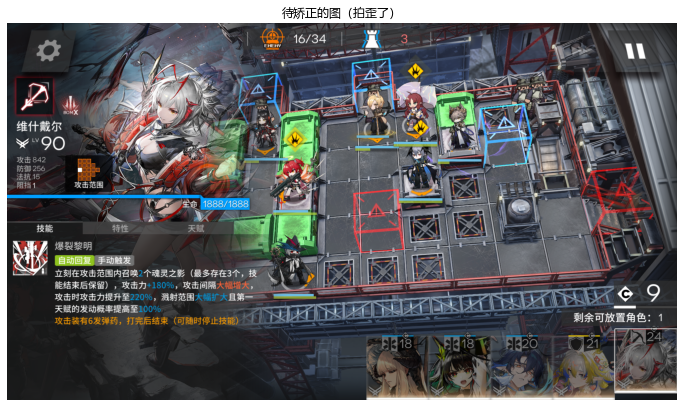

In [124]:
# 待矫正的图：拍歪了的屏幕/纸张
image = cv2.imread('res/perspective_src.png')
print("原图尺寸 (高, 宽, 通道):", image.shape)
show_img(image, titles=['待矫正的图（拍歪了）'])

### 6.5 步骤 2：定义源坐标点

这是最关键的一步：**找到目标物体在原图中的四个顶点**。

**怎么拿到这 4 个坐标？**

- 用画图 / GIMP / Photoshop 打开图片，把鼠标停在四个角上，记下像素坐标 `(x, y)`；
- VSCode 里装 **Image Preview** 插件，打开图片后右上角选 preview，鼠标位置会显示坐标；
- **进阶**：用「二值化（第 5 章）→ 轮廓（第 5 章）→ `approxPolyDP`（选学第 3 章）」自动算出来（本章练习 3 就是这个）。

> ⚠️ **点序固定为「左上 → 右上 → 右下 → 左下」**，且必须和后面的 `dst_points` 一一对应。

src_points:
 [[ 690.  302.]
 [1565.  193.]
 [1709.  720.]
 [ 651.  785.]]


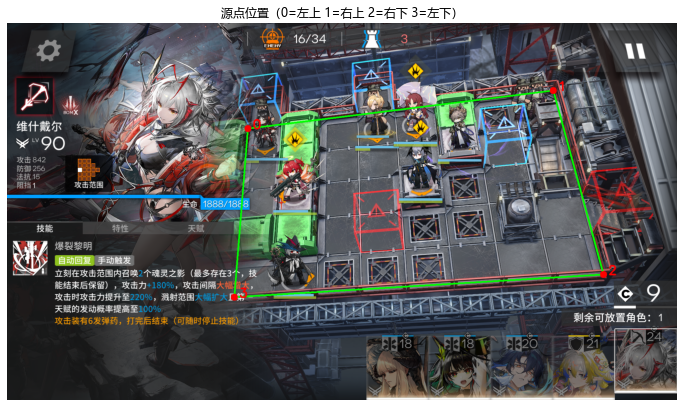

In [125]:
src_points = np.float32([
    [690, 302],     # 0 左上
    [1565, 193],    # 1 右上
    [1709, 720],    # 2 右下
    [651, 785],     # 3 左下
])
print("src_points:\n", src_points)

# 把 4 个点画在原图上，确认位置没取错（这一步千万别省）
check = image.copy()
cv2.polylines(check, [src_points.astype(np.int32)], True, (0, 255, 0), 3)
for i, (px, py) in enumerate(src_points.astype(int)):
    cv2.circle(check, (int(px), int(py)), 10, (0, 0, 255), -1)
    cv2.putText(check, str(i), (int(px) + 14, int(py)), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 0, 255), 3)
show_img(check, titles=['源点位置（0=左上 1=右上 2=右下 3=左下）'])

### 6.6 步骤 3：定义目标坐标点和输出尺寸

我们想让这个倾斜的四边形变成一个**标准矩形**，所以需要给出目标矩形的四个角点。

尺寸怎么定？一个好办法是**保持原来文档的宽高比**：
取源四边形「上边和下边里更长的」当宽度，「左边和右边里更长的」当高度。

In [126]:
# 宽度：上边 (0->1) 和下边 (3->2) 里更长的那个
width_top = np.sqrt(((src_points[1][0] - src_points[0][0]) ** 2) + ((src_points[1][1] - src_points[0][1]) ** 2))
width_bottom = np.sqrt(((src_points[2][0] - src_points[3][0]) ** 2) + ((src_points[2][1] - src_points[3][1]) ** 2))
max_width = int(max(width_top, width_bottom))

# 高度：左边 (0->3) 和右边 (1->2) 里更长的那个
height_left = np.sqrt(((src_points[3][0] - src_points[0][0]) ** 2) + ((src_points[3][1] - src_points[0][1]) ** 2))
height_right = np.sqrt(((src_points[2][0] - src_points[1][0]) ** 2) + ((src_points[2][1] - src_points[1][1]) ** 2))
max_height = int(max(height_left, height_right))

# 目标点：和源点顺序完全一致（左上 -> 右上 -> 右下 -> 左下）
dst_points = np.float32([
    [0, 0],
    [max_width - 1, 0],
    [max_width - 1, max_height - 1],
    [0, max_height - 1],
])

print("源四边形 宽 %.0f / %.0f，高 %.0f / %.0f" % (width_top, width_bottom, height_left, height_right))
print("输出尺寸: 宽 %d × 高 %d" % (max_width, max_height))
print("dst_points:\n", dst_points)

源四边形 宽 882 / 1060，高 485 / 546
输出尺寸: 宽 1059 × 高 546
dst_points:
 [[   0.    0.]
 [1058.    0.]
 [1058.  545.]
 [   0.  545.]]


### 6.7 步骤 4：计算矩阵并应用

现在有了源点和目标点，就可以算矩阵、做变换了。

透视变换矩阵 M:
 [[ 1.81124078e+00  1.46249255e-01 -1.29392341e+03]
 [ 2.24534994e-01  1.80245981e+00 -6.99272010e+02]
 [ 2.41972754e-04  5.39894822e-04  1.00000000e+00]]
形状: (3, 3)

矫正后尺寸: (546, 1059, 3)


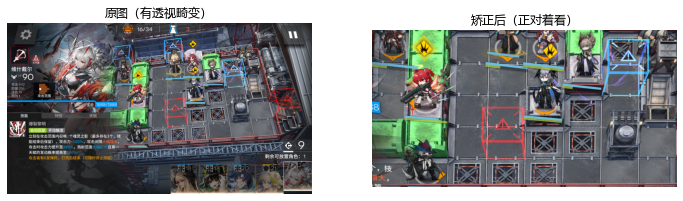

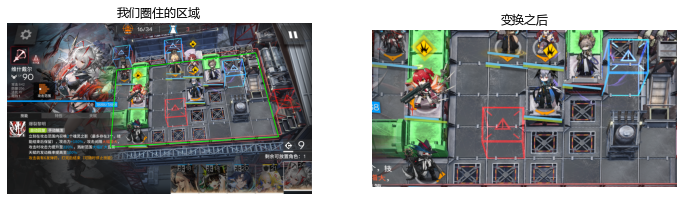

In [127]:
# ① 算 3×3 透视变换矩阵
M = cv2.getPerspectiveTransform(src_points, dst_points)
print("透视变换矩阵 M:\n", M)
print("形状:", M.shape)

# ② 对整个图像应用这个变换
warped = cv2.warpPerspective(image, M, (max_width, max_height))
print("\n矫正后尺寸:", warped.shape)

show_img(image, warped, titles=['原图（有透视畸变）', '矫正后（正对着看）'])

# ③ 在原图上把"取的区域"画出来，方便对照
marked = image.copy()
cv2.polylines(marked, [src_points.astype(np.int32)], True, (0, 255, 0), 4)
show_img(marked, warped, titles=['我们圈住的区域', '变换之后'])

### 6.8 几点注意

> ⚠️ **易错点 ①**：`src` / `dst` 的 `dtype` 必须是 **`np.float32`**。
> 直接写 `np.array([...])`（默认 `float64`）会报
> `error: (-5:Bad argument) ... Can't parse 'src'`。养成习惯：**一律 `np.float32([...])`**。

> ⚠️ **易错点 ②**：`cv2.warpPerspective` 的 `dsize` 是 **`(宽, 高)`**，
> 而 `image.shape` 给的是 `(高, 宽, 通道)` —— 两者**顺序相反**。
> 写反了不会报错，但输出图会变成一条细长条。

> ⚠️ **易错点 ③**：透视变换**只保证"四个角对得上"**。
> 变换前平行的线，变换后**不保证还平行**（因为透视本来就会破坏平行性）。
> 如果你需要"平行线变换后仍平行"，那要用**仿射变换**（3 组点），不是透视变换。

> 💡 **小贴士**：变换后图外会出现黑边，这是正常的（`borderValue` 默认 0）。
> 想裁掉的话：先 `cv2.threshold` 找非黑区域，再用 `cv2.boundingRect` 取 `[y0:y1, x0:x1]`。

### ✍️ 练习

1. 把 `res/nl_hd01.jpg` 缩放到宽度 640（保持宽高比），存入 `out/`。
2. 把 `out/card.png` 分别平移 `(100, 0)`、`(0, 100)`、`(-50, -50)`，并排显示。
3. 把 `out/card.png` 逆时针旋转 30°、60°、90°，比较效果。
4. 用仿射变换把 `out/card.png` 的**上边拉长、下边不变**（提示：只改 `pts2` 上面两个点）。
5. **思考题**：为什么透视变换必须用 4 个点，3 个点行不行？

> ❓ **自测**：如果只想把一张图放大 2 倍，用 `cv2.resize` 还是 `cv2.warpAffine`？为什么？

**透视变换部分（对应上面第 6 节）：**

6. 故意把 `src_points` 的第 1 和第 2 个点**交换顺序**，重新跑一遍，观察结果怎么烂掉，解释原因。
7. 把 `warped` 里 `cv2.warpPerspective` 的插值方式换成 `cv2.INTER_NEAREST`、`cv2.INTER_CUBIC`、
   `cv2.INTER_LANCZOS4`，对比画质和速度。
8. 给矫正结果**自动裁掉黑边**：找出非黑区域的 `boundingRect`，再切片取出。
9. 用 `res/getperspective_transform_01.png` 重复一遍全流程（坐标自己量）。
10. **串起来（重点）**：用**选学讲义第 4 章**练习里写好的 `process_MHZ()` 自动取出
   `res/MHZ.png` 梅花桩的四个角点，直接喂给 `cv2.getPerspectiveTransform`，
   做一次**全自动**的透视矫正，并和手工量点的结果对比。
11. **思考题**：如果拍文档时手机是**往上仰**的，矫正出来的文字会不会有残留变形？
   如果有，是哪个参数不够用了？


---

# 第 10 章 在图像上画图

> 🎯 **学习目标**：会画线、矩形、圆和文字，用来标注算法结果。

## 讲解要点

### 1. 画直线和矩形

```python
cv2.line(img, pt1, pt2, color, thickness)
cv2.rectangle(img, pt1, pt2, color, thickness)        # 传两个对角点
cv2.rectangle(img, (x, y, w, h), color, thickness)    # 或传外接矩形
```

### 2. 画圆

```python
cv2.circle(img, center, radius, color, thickness)
```

### 3. 写文字

```python
cv2.putText(img, text, org, fontFace, fontScale, color, thickness)
#                  ↑文字  ↑左下角坐标
```

### 几个约定

| 参数 | 说明 |
| --- | --- |
| **坐标** | `(x, y)` —— 注意**这里是先 x 后 y**，和 `img[y, x]` 相反 |
| **color** | BGR 三元组，如红色 `(0, 0, 255)`、绿色 `(0, 255, 0)` |
| **thickness** | 线宽，单位像素；**传 -1 表示填充** |
| **fontFace** | 常用 `cv2.FONT_HERSHEY_SIMPLEX` |
| **fontScale** | 字体缩放倍数 |

> ⚠️ **易错点**：画图函数的坐标是 **(x, y)**，而数组索引是 `[y, x]`。
> 这两套混用是新手最常见的 bug 来源 —— 明明想画在左上角，结果画到了别的地方。

> 💡 **小贴士**：还有一个"边画边看"的神器 —— **轨迹栏 `cv2.createTrackbar`**，
> 可以拖动滑块实时调 HSV 阈值，调参效率极高。
> 但它和鼠标事件回调一样是 GUI 功能，**要在 `.py` 里用**，Notebook 里跑不了。

> ❓ **自测**：`cv2.rectangle(img, (10, 10), (60, 60), (0, 255, 0), -1)` 里 `-1` 是什么意思？


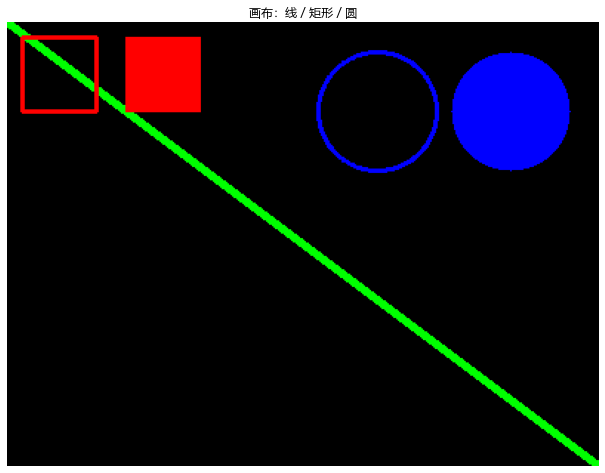

In [128]:
# 演示 1：画线、矩形、圆
canvas = np.zeros((300, 400, 3), dtype='uint8')     # 黑色画布

green = (0, 255, 0)
red = (0, 0, 255)
blue = (255, 0, 0)

cv2.line(canvas, (0, 0), (400, 300), green, 3)              # 对角线
cv2.rectangle(canvas, (10, 10), (60, 60), red, 2)           # 空心矩形
cv2.rectangle(canvas, (80, 10), (130, 60), red, -1)         # 实心矩形（thickness=-1）
cv2.circle(canvas, (250, 60), 40, blue, 2)                  # 空心圆
cv2.circle(canvas, (340, 60), 40, blue, -1)                 # 实心圆

show_img(canvas, titles=['画布：线 / 矩形 / 圆'])


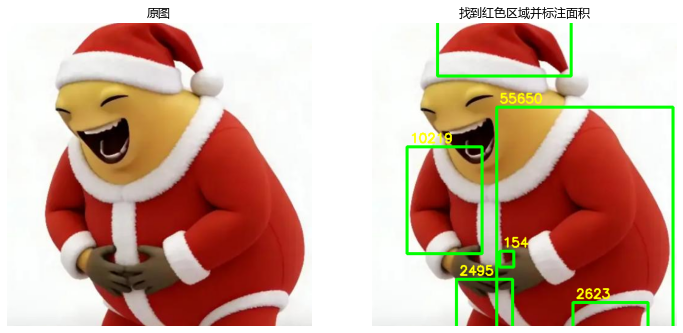

检测到 6 个区域


In [129]:
# 演示 2：画图给算法结果做标注（实战里最常用的用法）
img = cv2.imread('res/nl_santa.png')
img_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV_FULL)

# 分割红色
red_l1, red_u1 = np.array([0, 70, 70]),   np.array([14, 255, 255])
red_l2, red_u2 = np.array([243, 70, 70]), np.array([255, 255, 255])
r_mask = cv2.inRange(img_hsv, red_l1, red_u1) | cv2.inRange(img_hsv, red_l2, red_u2)
r_mask = cv2.morphologyEx(r_mask, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))

# 找轮廓 -> 外接矩形 -> 画出来
contours, _ = cv2.findContours(r_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
result = img.copy()
for c in contours:
    area = cv2.contourArea(c)
    if area < 100:                      # 过滤小噪点
        continue
    x, y, w, h = cv2.boundingRect(c)    # 外接矩形 -> (x, y, 宽, 高)
    cv2.rectangle(result, (x - 5, y - 5), (x + w + 5, y + h + 5), (0, 255, 0), 3)
    # 注意：这里的 (x, y) 是 "x, y"，而 img[y, x] 是 "y, x"
    cv2.putText(result, f'{int(area)}', (x, y - 12),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2)

show_img(img, result, titles=['原图', '找到红色区域并标注面积'])
print("检测到 %d 个区域" % len([c for c in contours if cv2.contourArea(c) >= 100]))


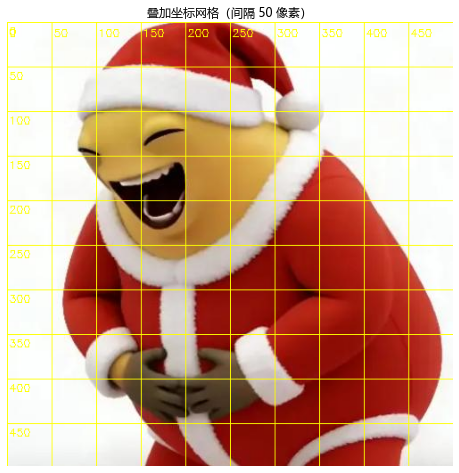

In [130]:
# 演示 3：画坐标网格，用来定位像素（调 HSV 阈值时的必备工具）
img = cv2.imread('res/nl_santa.png')
h, w = img.shape[:2]

grid = img.copy()
for x in range(0, w, 50):
    cv2.line(grid, (x, 0), (x, h), (0, 255, 255), 1)
    cv2.putText(grid, str(x), (x + 2, 16), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 255), 1)
for y in range(0, h, 50):
    cv2.line(grid, (0, y), (w, y), (0, 255, 255), 1)
    cv2.putText(grid, str(y), (2, y + 14), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 255), 1)

show_img(grid, titles=['叠加坐标网格（间隔 50 像素）'])


### ✍️ 练习

1. 画一张 400×400 的黑色画布，在正中央画一个红色实心圆，半径 80。
2. 画一个"棋盘格"：用 `cv2.rectangle` 画 8×8 的黑白格子。
3. 给 `res/nl_point.png` 加上坐标网格（间隔 100），存入 `out/`。
4. 用 `cv2.putText` 在 `res/nl_hd01.jpg` 的左上角写上"RobotIC"。
5. **思考题**：`cv2.putText` 的 `org` 参数是文字的哪个角？（试几次就知道了）

> ❓ **自测**：画图函数的坐标 `(x, y)` 和数组索引 `[y, x]` 是什么关系？


---

# 第 11 章 面向对象编程（OOP）入门

> 🎯 **学习目标**：能把散装代码收拾成一个类，并且会用 `try/except` 防止程序崩掉。

## 讲解要点

### 1. 先看"没有 OOP"的样子

```python
participant1_name = "齐夏"
participant1_skill = "生生不息"
participant1_dao = 0
participant2_name = "乔家劲"
...（一堆散装变量）
```

**三个问题**：

1. 参数散落各处，改一个阈值要翻半天
2. 想同时跑两套逻辑，只能复制粘贴
3. 队友想复用，只能整段拷贝，然后各自维护两份

> 💡 **小贴士**：这一节别一上来就抠语法，**先看痛点**。
> 先承认"散装代码确实难受"，再学类，接受度完全不一样。

### 2. 类与对象

| 概念 | 说明 | 类比 |
| --- | --- | --- |
| **类 class** | 模板 / 蓝图 | "参与者"这个概念 |
| **对象 instance** | 按模板造出来的个体 | "齐夏"这个人 |
| **属性 attribute** | 对象持有的数据（也叫成员变量） | `name`、`dao` |
| **方法 method** | 对象能做的事（也叫成员函数） | `earn_dao()` |
| `__init__` | 构造方法，创建对象时自动执行 | 出生时赋初值 |

```python
qi_xia = Participant("齐夏", "生生不息", 0)     # 创建对象 = 实例化
```

**`self` 是什么**：一句话 —— **`self` 就是"调用这个方法的那个对象"**。

```python
qi_xia.earn_dao(3)     # 等价于 Participant.earn_dao(qi_xia, 3)
```

### 3. 封装：把数据保护起来

| 写法 | 含义 |
| --- | --- |
| `self.x` | 公开属性，外部可随意读写 |
| `self.__x` | 私有属性，**外部直接访问会报错** |

> 💡 **小贴士**：在视觉工程里，阈值（`__lower / __upper`）**应该由类自己管**。
> 外界能随手改，队友一个手滑就把检测搞崩了。封装后外部只需调 `detect()`。
> 记住这个**工程理由**，比背"Python 语法规定"有用得多。

### 4. `try / except`：别让程序一崩到底

```python
try:
    risky()          # 可能出错的代码
except SomeError as e:
    handle(e)        # 出错时怎么办
finally:
    cleanup()        # 无论成败都执行
```

视觉程序里为什么必须有它：摄像头插拔、配置文件缺失、图像路径写错……
没有异常处理，一个偶发问题就让整个程序挂掉；
有了它，可以"跳过这一帧，继续跑" —— **赛场上是生死攸关的**。

> ❓ **自测**：`try` 里只捕获一个具体异常，和捕获所有 `Exception`，各有什么利弊？


In [131]:
# 演示 1：先看没有 OOP 时的写法
participant1_name = "齐夏"
participant1_skill = "生生不息"
participant1_dao = 0

participant2_name = "乔家劲"
participant2_skill = "破万法"
participant2_dao = 0


def activate_skill(name, skill, dao):
    print(f"{name}在游戏中觉醒了{skill}，当前拥有{dao}颗「道」")


activate_skill(participant1_name, participant1_skill, participant1_dao)
print("\n问题：数据分散、容易传错、加一个新属性要改很多地方")


齐夏在游戏中觉醒了生生不息，当前拥有0颗「道」

问题：数据分散、容易传错、加一个新属性要改很多地方


In [132]:
# 演示 2：改成类 —— 属性 / 方法 / self
class Participant:
    """参与者类，代表终焉之地的一个玩家"""

    def __init__(self, name, Echo, dao=0):
        self.name = name          # 姓名（如齐夏）
        self.Echo = Echo          # 回响能力（如破万法）
        self.dao = dao            # 拥有的「道」数量
        self.is_alive = True      # 生存状态

    def activate_skill(self, game_name):
        """参与游戏的方法"""
        print(f"{self.name}在「{game_name}」游戏中觉醒了{self.Echo}")

    def earn_dao(self, amount):
        """获得「道」的方法"""
        self.dao += amount
        print(f"{self.name}获得{amount}颗「道」，当前总计：{self.dao}颗")

    def die(self):
        """死亡方法（但会复活）"""
        self.is_alive = False
        print(f"{self.name}在游戏中死亡...但将在第十一日复活")


# 创建参与者对象 —— 也叫实例化
qi_xia = Participant("齐夏", "生生不息", 0)
qiao_jiajin = Participant("乔家劲", "破万法", 0)

print("=== 参与者入场 ===")
qi_xia.activate_skill("说谎者游戏")
qiao_jiajin.activate_skill("力量竞技场")

qi_xia.earn_dao(3)
qiao_jiajin.earn_dao(2)

print("\n=== 游戏结果 ===")
qi_xia.die()
print("\n两个对象互不影响:", qi_xia.dao, "vs", qiao_jiajin.dao)

print("\nqi_xia.earn_dao(3) 等价于 Participant.earn_dao(qi_xia, 3):")
Participant.earn_dao(qi_xia, 3)


=== 参与者入场 ===
齐夏在「说谎者游戏」游戏中觉醒了生生不息
乔家劲在「力量竞技场」游戏中觉醒了破万法
齐夏获得3颗「道」，当前总计：3颗
乔家劲获得2颗「道」，当前总计：2颗

=== 游戏结果 ===
齐夏在游戏中死亡...但将在第十一日复活

两个对象互不影响: 3 vs 2

qi_xia.earn_dao(3) 等价于 Participant.earn_dao(qi_xia, 3):
齐夏获得3颗「道」，当前总计：6颗


In [133]:
# 演示 3：封装 —— 效果公开，核心机密私有
class EchoAbility:
    """回响能力基类 —— 封装回响能力名称，只暴露效果"""

    def __init__(self, name, effect, eye_position):
        self.effect = effect                 # 公开：能力效果
        self.__eye_position = eye_position   # 私有：眼睛位置（核心机密）
        self.__name = name                   # 私有：回响能力名称

    def ability_effect(self):
        return f"能力效果：{self.effect}"


duoxingpo = EchoAbility("夺心魄", "精神控制，强迫他人模仿自己的动作", "心脏")
print(duoxingpo.ability_effect())            # 只能看到效果

try:
    print(duoxingpo.__name)                  # 访问私有属性会失败
except AttributeError as e:
    print(f"机密保护：{e}")


能力效果：精神控制，强迫他人模仿自己的动作
机密保护：'EchoAbility' object has no attribute '__name'


In [134]:
# 演示 4：try/except 让程序别一崩到底

def safe_read(path, flag=cv2.IMREAD_COLOR):
    """把"可能失败"的读图包装起来，失败时给出可读提示。"""
    try:
        img = cv2.imread(path, flag)
        if img is None:
            raise FileNotFoundError(f"读不到：{path}")
        return img
    except FileNotFoundError as e:
        print(f"读取失败，已跳过：[FileNotFoundError] {e}")
        return None


print("成功:", safe_read('res/nl_side.png').shape)
print("失败:", safe_read('res/不存在.png'))


# 更实用的写法：失败时回退到默认图，程序继续跑
def load_or_default(path, default='res/nl_side.png'):
    try:
        img = cv2.imread(path)
        if img is None:
            raise FileNotFoundError(path)
        return img
    except Exception:
        print(f"  [{path}] 读取失败，回退到 {default}")
        return cv2.imread(default)


print("回退结果:", load_or_default('res/不存在.png').shape)


成功: (302, 320, 3)
读取失败，已跳过：[FileNotFoundError] 读不到：res/不存在.png
失败: None
  [res/不存在.png] 读取失败，回退到 res/nl_side.png
回退结果: (302, 320, 3)


### ✍️ 练习

1. 写一个 `Timer` 类：`start()` / `stop()` / `elapsed()`，用来统计一段代码的耗时。
2. 写一个 `Camera` 类：`__init__(index)` 打开摄像头，提供 `read()`（返回帧或 `None`）与 `release()`，
   并在 `read` 内部用 `try/except` 兜底。
3. 写一个 `ColorRange` 类：构造时传入颜色的 HSV 区间，提供 `mask(hsv)` 方法返回掩膜。
4. **思考题**：`self` 为什么不能省？省掉会发生什么？
5. **思考题**：私有属性 `__x` 真的"不可访问"吗？为什么还说它是"约定"？

> ❓ **自测**：如果你来写一个"颜色分割器"，你会把哪些东西做成属性？


---

# 第 12 章 综合实战：红绿灯识别

> 🎯 **学习目标**：把前面十一章串起来，做一个完整的"颜色识别 → 定位 → 可视化"流程。

## 整体思路（经典的颜色分割流程）

1. 读入图像 → 转 **HSV**（比 BGR 更适合颜色分割）；
2. 用 `cv2.inRange` 按 HSV 阈值分别提取 **红 / 黄 / 绿** 三种颜色的区域；
3. 用开运算去噪 → 统计每种颜色的像素数，**像素最多的那个就是亮起的灯**；
4. 找轮廓定位，用 `cv2.rectangle` + `cv2.putText` 把结果标出来。

| 步骤 | 关键函数 | 出自 |
| --- | --- | --- |
| 转颜色空间 | `cv2.cvtColor(img, cv2.COLOR_BGR2HSV)` | 第 3 章 |
| 颜色分割 | `cv2.inRange`（红色需两段合并） | 第 5 章 |
| 去噪 | `cv2.morphologyEx(..., cv2.MORPH_OPEN, kernel)` | 第 6 章 |
| 统计判定 | `cv2.countNonZero` / `max(areas, key=...)` | 第 5 章 |
| 定位 | `cv2.findContours` + `cv2.boundingRect` | 第 5 章 |
| 可视化 | `cv2.rectangle` / `cv2.putText` | 第 10 章 |
| 封装 | `class` + `try/except` | 第 11 章 |

> 💡 **小贴士**：真实路况下光照变化很大，几个实用的改进方向：
> - `V` 阈值适当放宽，或改用 **Lab 空间 + 自适应阈值**；
> - 先做 **ROI 裁剪**（只分析画面上方区域），大幅减少干扰；
> - 视频里对连续多帧的判定结果做**投票**，避免偶发误判。

> ❓ **自测**：为什么这里用 `countNonZero` 统计像素数就够了，而不是必须找轮廓？


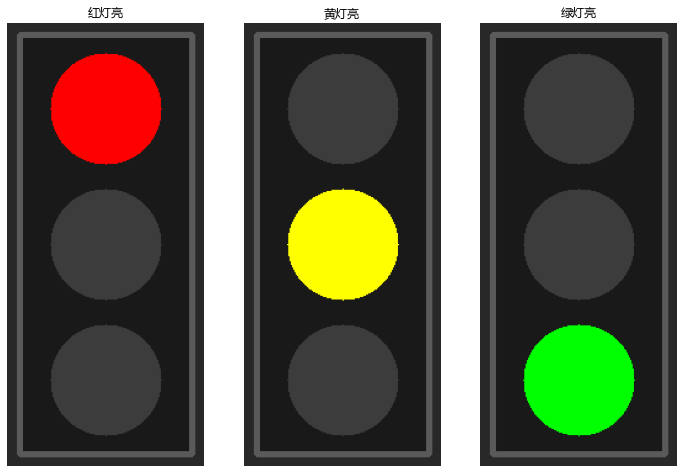

In [135]:
# 演示 1：先造三张"红绿灯"图来做测试
def make_traffic_light(lit='red'):
    """生成一张简易红绿灯图：只有 lit 指定的灯是亮的（饱和），其余为暗灰。"""
    img = np.full((360, 160, 3), 40, np.uint8)                 # 深灰底板
    cv2.rectangle(img, (10, 10), (150, 350), (25, 25, 25), -1)  # 灯箱
    cv2.rectangle(img, (10, 10), (150, 350), (90, 90, 90), 3)   # 边框

    lamps = {'red': ((0, 0, 255), 70),
             'yellow': ((0, 255, 255), 180),
             'green': ((0, 255, 0), 290)}
    for name, (color, cy) in lamps.items():
        fill = color if name == lit else (60, 60, 60)           # 未亮的灯用暗灰
        cv2.circle(img, (80, cy), 45, fill, -1)
    return img


show_img(make_traffic_light('red'), make_traffic_light('yellow'), make_traffic_light('green'),
         titles=['红灯亮', '黄灯亮', '绿灯亮'])


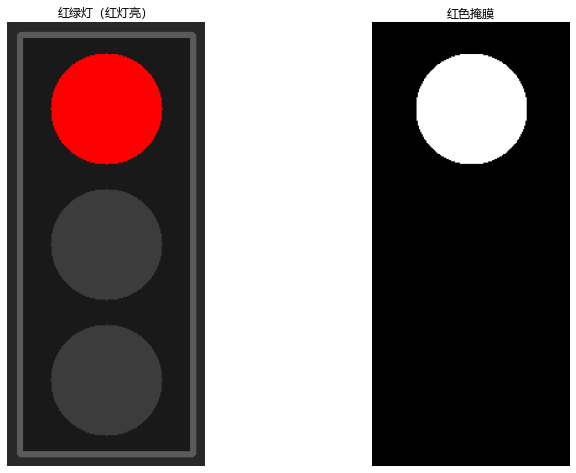

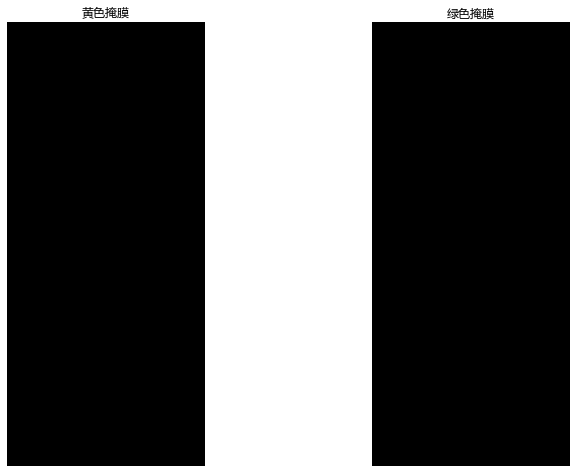

In [136]:
# 演示 2：HSV 颜色分割
def color_masks(img):
    """返回 (hsv, {颜色名: 掩膜})。注意这里用的是标准 HSV（H: 0~179）。"""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    # 红色分两段再合并
    mask_red = cv2.inRange(hsv, (0, 100, 100), (10, 255, 255)) | \
               cv2.inRange(hsv, (170, 100, 100), (179, 255, 255))
    mask_yellow = cv2.inRange(hsv, (20, 100, 100), (35, 255, 255))
    mask_green = cv2.inRange(hsv, (40, 100, 100), (90, 255, 255))

    # 形态学开运算去掉噪点
    kernel = np.ones((5, 5), np.uint8)
    clean = lambda m: cv2.morphologyEx(m, cv2.MORPH_OPEN, kernel)

    return hsv, {'红': clean(mask_red), '黄': clean(mask_yellow), '绿': clean(mask_green)}


img = make_traffic_light('red')
hsv, masks = color_masks(img)

show_img(img, masks['红'], titles=['红绿灯（红灯亮）', '红色掩膜'])
show_img(masks['黄'], masks['绿'], titles=['黄色掩膜', '绿色掩膜'])


亮灯=red    -> 识别结果【红】  像素数={'红': 6357, '黄': 0, '绿': 0}
亮灯=yellow -> 识别结果【黄】  像素数={'红': 0, '黄': 6357, '绿': 0}
亮灯=green  -> 识别结果【绿】  像素数={'红': 0, '黄': 0, '绿': 6357}


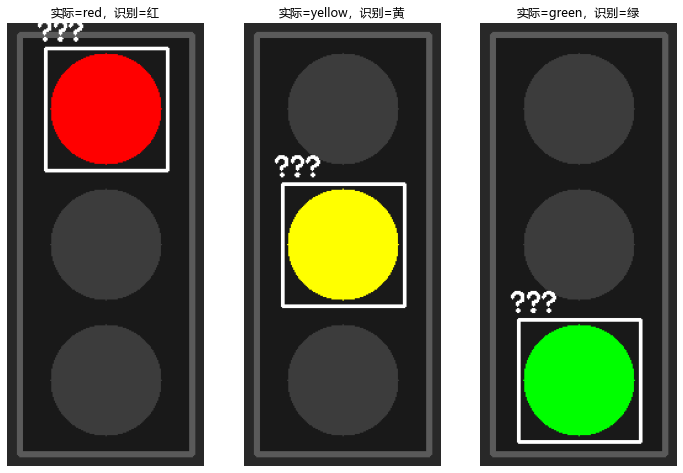

In [137]:
# 演示 3：判定 + 定位 + 可视化
def detect_traffic_light(img, min_area=100):
    """识别红绿灯：返回 (颜色名, 各颜色像素数, 画了框的结果图)。"""
    _, masks = color_masks(img)
    areas = {name: int(cv2.countNonZero(m)) for name, m in masks.items()}

    color = max(areas, key=areas.get)          # 像素最多的颜色 = 亮起的灯
    if areas[color] < min_area:                # 太小 -> 认为没亮灯
        return "未检测到", areas, img.copy()

    mask = masks[color]
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    result = img.copy()
    for c in contours:
        if cv2.contourArea(c) > min_area:
            x, y, w, h = cv2.boundingRect(c)
            cv2.rectangle(result, (x - 5, y - 5), (x + w + 5, y + h + 5), (255, 255, 255), 2)
            cv2.putText(result, color, (x - 12, y - 12),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
    return color, areas, result


# 三种情况各测一次
results, titles = [], []
for lit in ['red', 'yellow', 'green']:
    test_img = make_traffic_light(lit)
    color, areas, vis = detect_traffic_light(test_img)
    print(f"亮灯={lit:6s} -> 识别结果【{color}】  像素数={areas}")
    results.append(vis)
    titles.append(f'实际={lit}，识别={color}')

show_img(*results, titles=titles)


亮灯=red    -> 【红】
亮灯=yellow -> 【黄】
亮灯=green  -> 【绿】
照片尺寸: (1920, 1440, 3)


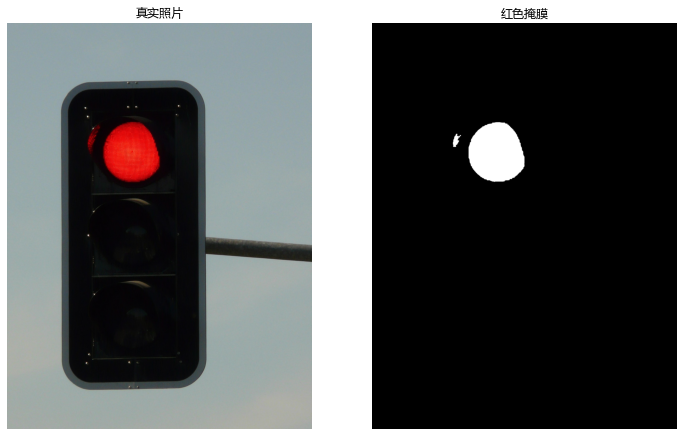

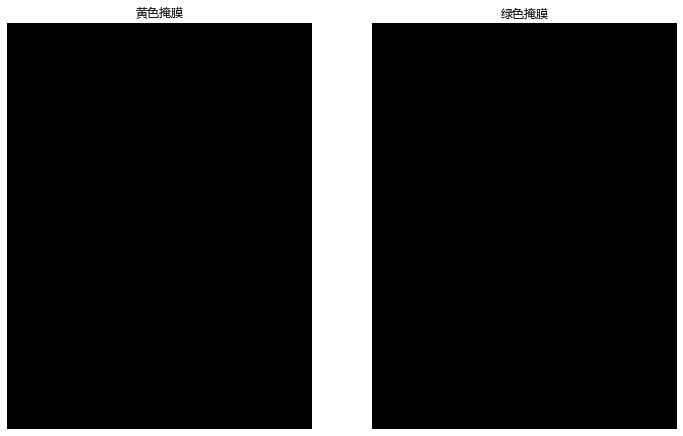

真实照片识别结果: 红 {'红': 59441, '黄': 0, '绿': 0}
照片里只有红灯亮着，黄色和绿色都是 0 像素，所以判定为红色——和假设一致。


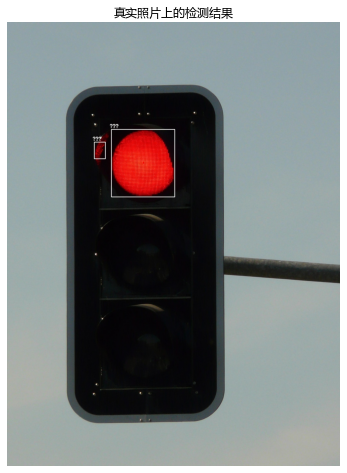

In [138]:
# 演示 4：封装成类（把第 11 章的 OOP 用起来）
class TrafficLightDetector:
    """红绿灯识别器：颜色阈值由类自己管，外部只需要调 detect()。"""

    def __init__(self, min_area=100, morph_size=5):
        self.min_area = min_area
        self.__ranges = {                    # 私有：阈值不给外部乱改
            '红': [((0, 100, 100), (10, 255, 255)),
                   ((170, 100, 100), (179, 255, 255))],
            '黄': [((20, 100, 100), (35, 255, 255))],
            '绿': [((40, 100, 100), (90, 255, 255))],
        }
        self.__kernel = np.ones((morph_size, morph_size), np.uint8)

    def masks(self, img):
        """生成每种颜色的掩膜（多区间自动合并 + 开运算去噪）。"""
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        out = {}
        for name, ranges in self.__ranges.items():
            m = None
            for lower, upper in ranges:
                cur = cv2.inRange(hsv, np.array(lower), np.array(upper))
                m = cur if m is None else (m | cur)          # 按位或合并多段
            out[name] = cv2.morphologyEx(m, cv2.MORPH_OPEN, self.__kernel)
        return out

    def detect(self, img):
        """返回 (颜色名, 各颜色像素数, 可视化图)。"""
        masks = self.masks(img)
        areas = {name: int(cv2.countNonZero(m)) for name, m in masks.items()}
        color = max(areas, key=areas.get)

        result = img.copy()
        if areas[color] < self.min_area:
            return '未检测到', areas, result

        contours, _ = cv2.findContours(masks[color], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        for c in contours:
            if cv2.contourArea(c) > self.min_area:
                x, y, w, h = cv2.boundingRect(c)
                cv2.rectangle(result, (x - 5, y - 5), (x + w + 5, y + h + 5), (255, 255, 255), 2)
                cv2.putText(result, color, (x - 12, y - 12),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
        return color, areas, result


detector = TrafficLightDetector(min_area=100)

# 用 try/except 兜底：任何一张图出问题都不影响后面的
for lit in ['red', 'yellow', 'green']:
    try:
        color, areas, vis = detector.detect(make_traffic_light(lit))
        print(f"亮灯={lit:6s} -> 【{color}】")
    except Exception as e:
        print(f"亮灯={lit:6s} -> 处理出错，已跳过：[{type(e).__name__}] {e}")

# 拿一张真实照片试试（可以换成你自己拍的红绿灯照片）
photo_path = 'res/hans-traffic-light-8511_1920.jpg'

# 讲义第 1 章教的：imread 失败只会安静地返回 None，所以一定要先判断再使用
photo = cv2.imread(photo_path)

if photo is None:
    print(f"没读到 {photo_path}，跳过真实照片测试。")
    print("想测试的话，把你自己拍的红绿灯照片放到 res/ 下，改一下上面的文件名即可。")
else:
    print("照片尺寸:", photo.shape)

    # 先把三张掩膜摆出来看看分割效果
    photo_masks = detector.masks(photo)
    show_img(photo, photo_masks['红'], titles=['真实照片', '红色掩膜'])
    show_img(photo_masks['黄'], photo_masks['绿'], titles=['黄色掩膜', '绿色掩膜'])

    color, areas, vis = detector.detect(photo)
    print("真实照片识别结果:", color, areas)
    print("照片里只有红灯亮着，黄色和绿色都是 0 像素，所以判定为红色——和假设一致。")
    show_img(vis, titles=['真实照片上的检测结果'])


### ✍️ 练习

1. 把演示 3 里的 `min_area` 改成 5000，重新测三张图，观察结果变化，解释为什么。
2. 给 `TrafficLightDetector` 加一个 `set_roi(x, y, w, h)` 方法，只在 ROI 内做检测。
3. 给 `TrafficLightDetector` 加一个 `from_config(path)` 类方法，从 JSON 文件读阈值。
4. 用 `res/nl_video.mp4`，逐帧跑一遍 `detector.detect()`，把判定结果用 `cv2.putText` 写在画面上，
   再用 `cv2.VideoWriter` 存成 `out/traffic_result.avi`。
5. **思考题**：如果红色和黄色像素数非常接近，该怎么处理？（提示：加一个"不确定"的判定分支）

> ❓ **自测**：把这章和前面九章对照一遍，说出每一步分别用到哪一章的知识。


---

# 附录 A · 函数速查表

## 读写与显示

| 函数 | 说明 |
| --- | --- |
| `cv2.imread(path, flag)` | 读图；失败返回 `None`；**不支持中文路径** |
| `cv2.imwrite(path, img)` | 保存；`[cv2.IMWRITE_JPEG_QUALITY, q]`；也不支持中文路径 |
| `cv2.imencode` + `buf.tofile` | 写中文路径的标准做法 |
| `np.fromfile` + `cv2.imdecode` | 读中文路径的标准做法 |
| `cv2.imshow` / `cv2.waitKey` / `cv2.destroyAllWindows` | GUI 三件套（写 `.py` 用） |
| `plt.imshow(img[:, :, ::-1])` | 给 matplotlib 显示（BGR → RGB） |
| `plt.imshow(gray, cmap='gray')` | 灰度图显示 |

## 视频

| 函数 | 说明 |
| --- | --- |
| `cv2.VideoCapture(0 / path)` | 打开摄像头 / 视频文件 |
| `cap.isOpened()` / `cap.read()` | 是否打开 / 读一帧 `(ret, frame)` |
| `cap.get(propId)` / `cap.set(propId, v)` | 读写属性（宽高、帧率、总帧数、跳帧） |
| `cv2.VideoWriter(path, fourcc, fps, **(宽, 高)**)` | 写视频 |
| `cap.release()` / `out.release()` | **必须调用** |

## 图像基本操作

| 函数 | 说明 |
| --- | --- |
| `img[y, x]` / `img.item(y, x, c)` | 访问像素 |
| `img[y0:y1, x0:x1]` | ROI（视图，要独立操作记得 `.copy()`） |
| `cv2.split` / `cv2.merge` | 拆 / 合通道 |
| `cv2.copyMakeBorder` | 边框填充 |
| `cv2.resize(img, (w, h), interpolation=...)` | 缩放 |

## 颜色空间

| 函数 | 说明 |
| --- | --- |
| `cv2.cvtColor` | `COLOR_BGR2GRAY` / `COLOR_BGR2HSV` / **`COLOR_BGR2HSV_FULL`** / `COLOR_BGR2RGB` / `COLOR_BGR2LAB` / `COLOR_BGR2YCrCb`（**`src` 不能是 `None`**，详见第 3 章） |
| `cv2.inRange(src, lo, hi)` | 颜色区间掩膜 |
| `cv2.countNonZero(mask)` | 统计掩膜像素数 |

## 阈值、滤波、形态学

| 函数 | 说明 |
| --- | --- |
| `cv2.threshold(src, T, maxval, type)` | 固定阈值 / `+THRESH_OTSU` |
| `cv2.adaptiveThreshold` | 自适应阈值 |
| `cv2.blur` / `cv2.GaussianBlur` / `cv2.medianBlur` / `cv2.bilateralFilter` | 四种滤波 |
| `cv2.getGaussianKernel(k, sigma)` | 一维高斯核 |
| `cv2.getStructuringElement` / `cv2.erode` / `cv2.dilate` | 结构元素 / 腐蚀 / 膨胀 |
| `cv2.morphologyEx(..., cv2.MORPH_OPEN, k)` | 开运算去噪 |

## 算术、几何、画图

| 函数 | 说明 |
| --- | --- |
| `cv2.add` / `cv2.addWeighted` | 饱和加法 / 混合 |
| `cv2.bitwise_and` / `_or` / `_not` / `_xor` | 按位运算（配 mask 用） |
| `cv2.warpAffine` / `cv2.getRotationMatrix2D` / `cv2.getAffineTransform` | 平移 / 旋转 / 仿射 |
| `cv2.getPerspectiveTransform` / `cv2.warpPerspective` | 透视变换 |
| `cv2.line` / `cv2.rectangle` / `cv2.circle` / `cv2.putText` | 画图（坐标先 x 后 y） |
| `cv2.findContours` / `cv2.boundingRect` / `cv2.contourArea` | 找轮廓 / 外接矩形 / 面积 |



*本讲义依据 26赛季RobotIC 算法培训讲义 `cv1` 重写，素材来自 `wallpaper-main` 奶蛙图库。*

---

> 🙏 **致谢学长**
>
> 这份讲义是在学长们整理的《RobotIC 算法培训讲义》（`cv1` / `cv2`）的基础上重写的。


